# Planificación adaptativa de entrenamientos de alta carga mediante aprendizaje automático
## Caso de estudio del triatlón de media distancia (113 km) — Trabajo Fin de Máster
**Autor:** Marco Hidalgo Sanguano | **Director:** José Manuel Díaz Sarachaga

Cuaderno de trabajo del TFM. Recoge, en el orden en que se hicieron, la carga y limpieza de los datos, los
experimentos con los modelos y la construcción del motor de planificación. Se organiza en cuatro fases:

| Fase | Contenido | Secciones |
|---|---|---|
| 0. Datos | Exportaciones de Garmin Connect y conjuntos públicos, limpieza, TRIMP y CTL/ATL/TSB | 1 a 4 |
| 1. Transferencia | Estimar la velocidad en ciclismo a partir de la carrera, y al revés: comparación de algoritmos, optimización y modelo final | 6 |
| 2. Planificación | Reglas de tipo de semana, periodización, zonas, ritmos y plan semanal | 7 |
| 3. Explicación | Texto explicativo del plan con Gemini o con plantillas | 8 |

La sección 5 guarda un agrupamiento K-means que se probó y se descartó; nada de esa sección se usa después.

### Deportistas
Se identifican con letras en todas las salidas, sin nombres.

| Deportista | Historial principal | Papel en el estudio |
|---|---|---|
| A (mujer) | Carrera y natación, solo 15 sesiones de ciclismo | Caso para el que se pensó la estimación entre disciplinas |
| B | Sobre todo carrera | Contraste |
| C | Las tres disciplinas, el mayor volumen | Contraste |
| D | Sobre todo ciclismo, casi sin frecuencia cardíaca | Contraste |

### Conjuntos públicos (Kaggle)
| Conjunto | Uso |
|---|---|
| Triathlon results (vladislavboyadzhi) | Entrenamiento y validación de los modelos de transferencia |
| Athlete training and recovery tracker (prince7489) | Exploración de variables de recuperación |
| GoldenCheetah OpenData (markliversedge) | Calibración de la combinación del modelo con las sesiones propias (sección 6g) |

### Salidas
Al terminar, la carpeta `salidas/` contiene los modelos que usa la aplicación (`salidas/modelos/`), las
tablas en Parquet y SQLite y las figuras (`salidas/figuras/`).

## 0. Instalación y configuración

In [1]:
# Paquetes que no vienen instalados por defecto en Colab. XGBoost y scikit-learn se fijan
# en las mismas versiones que la aplicación (requirements.txt) para que los modelos
# guardados aquí se carguen allí sin problemas de compatibilidad.
!pip install -q kagglehub "xgboost==2.1.4" "scikit-learn==1.6.1" shap plotly google-generativeai pyarrow
print("Dependencias instaladas")

Dependencias instaladas


In [2]:
import os, glob, json, zipfile, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import plotly.graph_objects as go
from plotly.subplots import make_subplots

from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
from sklearn.model_selection import KFold, cross_validate, train_test_split
from sklearn.impute import SimpleImputer

import xgboost as xgb
import shap

warnings.filterwarnings('ignore')
pd.set_option('display.max_columns', 50)
pd.set_option('display.float_format', '{:.2f}'.format)

# Cada deportista se identifica con una letra; aquí se asocia al nombre de su ZIP de Garmin Connect
PARTICIPANTES = {'A': 'Josh', 'B': 'Marco', 'C': 'Andresin', 'D': 'Patico'}
sexo_por_atleta = {'A': 'F', 'B': 'M', 'C': 'M', 'D': 'M'}   # para el TRIMP y los modelos
SUJETO_PRUEBA = 'A'   # deportista sin historial de ciclismo
COLORS = {'A': '#E91E63', 'B': '#2196F3', 'C': '#FF5722', 'D': '#4CAF50'}

# Estilo común de las figuras: fondo blanco y texto negro
os.makedirs('salidas/figuras', exist_ok=True)
plt.rcParams.update({'font.size': 10, 'axes.titleweight': 'bold', 'axes.titlesize': 11})
print("Librerías cargadas")

Librerías cargadas


In [3]:
# API de Gemini para la capa explicativa. Es opcional: si no hay clave
# se usan plantillas de texto fijas y el cuaderno funciona igual.
GEMINI_API_KEY = ""   # pega aquí la clave de https://aistudio.google.com/
USE_LLM = bool(GEMINI_API_KEY)
if USE_LLM:
    import google.generativeai as genai
    genai.configure(api_key=GEMINI_API_KEY)
    llm_model = genai.GenerativeModel('gemini-1.5-flash')
    print("Gemini configurado")
else:
    print("Sin clave de Gemini: se usarán plantillas de texto")

Sin clave de Gemini: se usarán plantillas de texto


## 1. Carga de los conjuntos públicos

Los resultados de pruebas 70.3 aportan el volumen necesario para entrenar los modelos sin depender de los
cuatro deportistas. Los otros dos conjuntos solo se exploran.

In [4]:
import kagglehub

# 1.1 Resultados de triatlón: tiempos parciales reales de competición
path_tri = kagglehub.dataset_download("vladislavboyadzhi/triathlon-results")
tri_files = glob.glob(os.path.join(path_tri, '*.csv'))
df_triathlon = pd.concat([pd.read_csv(f) for f in tri_files], ignore_index=True)
print(f"Triathlon: {df_triathlon.shape[0]:,} filas x {df_triathlon.shape[1]} columnas")
print("Columnas:", df_triathlon.columns.tolist()[:15])


Using Colab cache for faster access to the 'triathlon-results' dataset.
Triathlon: 2,967,514 filas x 17 columnas
Columnas: ['event_dt', 'event_flg', 'event_name', 'event_f_cnt', 'event_m_cnt', 'event_link', 'gender', 'person_link', 'person_flag', 'person_name', 'person_event_group', 'person_event_swim_time_text', 'person_event_t1_time_text', 'person_event_cycle_time_text', 'person_event_t2_time_text']


In [5]:
# 1.2 Athlete training and recovery tracker (solo exploración)
path_ath = kagglehub.dataset_download("prince7489/athlete-training-and-recovery-tracker-dataset")
ath_files = glob.glob(os.path.join(path_ath, '*.csv'))
df_recovery = pd.concat([pd.read_csv(f) for f in ath_files], ignore_index=True)
print(f"Recovery: {df_recovery.shape[0]:,} filas x {df_recovery.shape[1]} columnas")

# Los nombres de columna cambian entre versiones del conjunto,
# así que se normalizan buscando palabras clave
col_map = {}
for col in df_recovery.columns:
    cl = col.lower().replace(' ', '_')
    if ('heart' in cl or cl in ('hr', 'avg_hr')): col_map[col] = 'avg_hr'
    elif 'session' in cl and 'load' in cl: col_map[col] = 'session_load'
    elif 'recovery' in cl and 'score' in cl: col_map[col] = 'recovery_score'
    elif 'sleep' in cl and ('hour' in cl or 'qual' in cl): col_map[col] = 'sleep_quality'
    elif 'stress' in cl: col_map[col] = 'stress_score'
    elif 'duration' in cl: col_map[col] = 'duration_min'
    elif 'distance' in cl: col_map[col] = 'distance_km'
    elif any(x in cl for x in ('sport', 'activity', 'exercise')): col_map[col] = 'sport_type'
    elif 'date' in cl: col_map[col] = 'date'
    elif 'hrv' in cl: col_map[col] = 'hrv'
df_recovery_clean = df_recovery.rename(columns=col_map)
print(f"{len(df_recovery_clean)} sesiones de recovery")

Using Colab cache for faster access to the 'athlete-training-and-recovery-tracker-dataset' dataset.
Recovery: 1,000 filas x 11 columnas
1000 sesiones de recovery


In [6]:
# 1.3 GoldenCheetah OpenData. Miles de deportistas con historial de bici y de carrera: se usa en la
# sección 6g para calibrar cómo se combina el modelo con las sesiones propias. Si la descarga falla,
# esa sección usa los valores de la calibración original y el resto del cuaderno no cambia.
def _leer_tabla(path):
    """Lee un CSV; si 'path' es una carpeta de partes, concatena los CSV internos."""
    if os.path.isdir(path):
        partes = [p for p in glob.glob(os.path.join(path, "**", "*.csv"), recursive=True)
                  if os.path.isfile(p)]
        return pd.concat([pd.read_csv(p) for p in partes], ignore_index=True)
    return pd.read_csv(path)

def _localizar(path_base, clave, excluir=()):
    """Devuelve la ruta (archivo o carpeta) cuyo nombre contiene 'clave'."""
    cand = [p for p in glob.glob(os.path.join(path_base, "**", "*"), recursive=True)
            if clave in os.path.basename(p).lower()
            and not any(x in os.path.basename(p).lower() for x in excluir)]
    archivos = [p for p in cand if os.path.isfile(p)]   # prioriza archivos reales
    return (archivos or cand or [None])[0]

try:
    path_gc = kagglehub.dataset_download(
        "markliversedge/goldencheetah-opendata-athlete-activity-and-mmp")
    ruta_act = _localizar(path_gc, "activit", excluir=("mmp",))   # actividades, sin MMP
    ruta_ath = _localizar(path_gc, "athlet")                       # atletas
    df_gc = _leer_tabla(ruta_act) if ruta_act else pd.DataFrame()
    df_gc_ath = _leer_tabla(ruta_ath) if ruta_ath else pd.DataFrame()
    print(f"GoldenCheetah REAL · actividades: {df_gc.shape} · atletas: {df_gc_ath.shape}")
    print("Columnas actividades:", list(df_gc.columns)[:25])
    print("Columnas atletas:", list(df_gc_ath.columns)[:25])
except Exception as e:
    print(f"No se pudo cargar GoldenCheetah ({e}); revisa kaggle.json")
    df_gc = pd.DataFrame(); df_gc_ath = pd.DataFrame()

Using Colab cache for faster access to the 'goldencheetah-opendata-athlete-activity-and-mmp' dataset.
GoldenCheetah REAL · actividades: (2398134, 34) · atletas: (6043, 36)
Columnas actividades: ['id', 'file', 'date', 'age', 'gender', 'sport', 'data', '1s_critical_power', '15s_critical_power', '2m_critical_power', '3m_critical_power', '5m_critical_power', '8m_critical_power', '10m_critical_power', '20m_critical_power', '30m_critical_power', '1m_peak_wpk', '5m_peak_wpk', '10m_peak_wpk', '20m_peak_wpk', '30m_peak_wpk', 'workout_time', 'total_distance', 'elevation_gain', 'total_work']
Columnas atletas: ['id', 'age', 'gender', 'activities', 'bike', 'run', 'swim', 'other', '1s_critical_power', '15s_critical_power', '2m_critical_power', '3m_critical_power', '5m_critical_power', '8m_critical_power', '10m_critical_power', '20m_critical_power', '30m_critical_power', '1m_peak_wpk', '5m_peak_wpk', '10m_peak_wpk', '20m_peak_wpk', '30m_peak_wpk', '20s_peak', '20s_peak_wpk', '60s_peak']


In [7]:
print("=== df_triathlon (resultados reales) ===  filas:", len(df_triathlon))
print(list(df_triathlon.columns))
print(df_triathlon.head(3).to_string())

print("\n=== df_gc (GoldenCheetah) ===")
try:
    print("filas:", len(df_gc), "| columnas:", list(df_gc.columns))
    if 'sport' in df_gc.columns: print(df_gc['sport'].value_counts())
except Exception as e:
    print("df_gc no disponible:", e)

=== df_triathlon (resultados reales) ===  filas: 2967514
['event_dt', 'event_flg', 'event_name', 'event_f_cnt', 'event_m_cnt', 'event_link', 'gender', 'person_link', 'person_flag', 'person_name', 'person_event_group', 'person_event_swim_time_text', 'person_event_t1_time_text', 'person_event_cycle_time_text', 'person_event_t2_time_text', 'person_event_run_time_text', 'person_event_finish_time_text']
     event_dt event_flg                     event_name  event_f_cnt  event_m_cnt                                 event_link gender person_link person_flag person_name person_event_group person_event_swim_time_text person_event_t1_time_text person_event_cycle_time_text person_event_t2_time_text person_event_run_time_text person_event_finish_time_text
0  2022-12-11       USA      Ironman Florida 70.3 2022       383.00      1105.00      /rus/result/ironman/florida/half/2022    NaN         NaN         NaN         NaN                NaN                         NaN                       NaN       

## 2. Carga de los datos personales (Garmin Connect)

Cada deportista cedió la exportación completa de su cuenta de Garmin Connect (un ZIP por persona).
El cuaderno busca los ZIP en la carpeta actual, en `/content/` y en Google Drive
(`MyDrive/TFM_Triatlon/` o `MyDrive/`). Para subirlos directamente a Colab:

```python
from google.colab import files
files.upload()   # Josh.zip, Marco.zip, Andresin.zip, Patico.zip
```

In [8]:
# Funciones auxiliares para dos campos de Garmin que vienen anidados

def extract_body_battery(bb_raw):
    """Saca el Body Battery de inicio de día del JSON de Garmin."""
    if isinstance(bb_raw, (int, float)):
        return float(bb_raw)
    if isinstance(bb_raw, dict):
        stat_list = bb_raw.get('bodyBatteryStatList', [])
        if stat_list:
            stats = {s['bodyBatteryStatType']: s['statsValue'] for s in stat_list}
            return float(stats.get('STARTOFDAY',
                         stats.get('HIGHEST',
                         stats.get('MOSTRECENT', float('nan')))))
        cv = bb_raw.get('chargedValue')
        if cv is not None:
            return float(cv)
    return float('nan')

def extract_stress(stress_raw):
    """Nivel de estrés medio del día. Garmin usa dos formatos distintos."""
    if isinstance(stress_raw, (int, float)):
        return float(stress_raw)
    if isinstance(stress_raw, dict):
        agg_list = stress_raw.get('aggregatorList', [])
        if agg_list:
            total = next((a for a in agg_list if a.get('type') == 'TOTAL'), None)
            if total:
                return float(total.get('averageStressLevel', float('nan')))
        return float(stress_raw.get('avgStressLevel', stress_raw.get('average', float('nan'))))
    return float('nan')

print("Funciones auxiliares listas")

Funciones auxiliares listas


In [9]:
# Reglas de validez de una actividad (se aplican al leerla, antes de calcular nada):
# fecha posterior a 2010 y no futura, y duración positiva de menos de 12 h. Las que no las cumplen
# se descartan y se cuentan en `descartadas`. Garmin guarda a veces fechas con su origen de tiempo
# (31/12/1989) cuando falta el reloj, y hay sesiones con duración vacía o de más de un día.
FECHA_MIN = pd.Timestamp('2010-01-01').date()
DURACION_MAX_MIN = 12 * 60
descartadas = []

# Lector principal: del ZIP de Garmin Connect a tablas de pandas.
# Extrae actividades, bienestar diario, sueño, readiness/HRV y VO2max.
# Si falta una variable se registra como ausente y el proceso continúa.

def parse_garmin_zip(zip_path, athlete_name):
    data = {k: [] for k in ('activities', 'uds', 'sleep', 'readiness', 'vo2')}

    with zipfile.ZipFile(zip_path, 'r') as z:
        files = z.namelist()

        # Actividades resumidas
        for af in [f for f in files if 'summarizedActivities' in f and f.endswith('.json')]:
            with z.open(af) as f: raw = json.load(f)
            acts = raw[0]['summarizedActivitiesExport'] if isinstance(raw, list) else raw.get('summarizedActivitiesExport', [])
            for a in acts:
                sport = a.get('sportType', '')
                if sport not in ('RUNNING', 'CYCLING', 'SWIMMING'): continue
                ts = a.get('startTimeGmt', 0)
                date = pd.to_datetime(ts, unit='ms', utc=True).date() if ts else None
                dur_ms    = a.get('duration') or a.get('movingDuration', 0)
                dur_min   = (dur_ms or 0) / 60000
                if date is None or date < FECHA_MIN or date > pd.Timestamp.today().date():
                    descartadas.append((athlete_name, sport, date, round(dur_min, 1), 'fecha imposible')); continue
                if dur_min <= 0 or dur_min > DURACION_MAX_MIN:
                    descartadas.append((athlete_name, sport, date, round(dur_min, 1), 'duración imposible')); continue
                dist_cm   = a.get('distance', np.nan)
                speed_raw = a.get('avgSpeed', np.nan)
                speed_kmh = speed_raw * 36 if speed_raw else np.nan
                # velocidades físicamente imposibles para la disciplina: se dejan ausentes, la sesión se conserva
                if speed_kmh and speed_kmh > {'RUNNING': 25, 'CYCLING': 60, 'SWIMMING': 6}[sport]:
                    speed_kmh = np.nan
                # por debajo de 5 km/h suele ser rodillo sin GPS: se marca como ausente
                if sport == 'CYCLING' and (not speed_kmh or speed_kmh < 5):
                    speed_kmh = np.nan
                elev_cm      = a.get('elevationGain', np.nan)
                elev_loss_cm = a.get('elevationLoss', np.nan)
                start_alt_cm = a.get('startElevation', np.nan)
                cadence = a.get('avgDoubleCadence') or ((a.get('avgRunCadence', 0) or 0) * 2) or np.nan
                data['activities'].append({
                    'athlete': athlete_name, 'date': date, 'sport': sport,
                    'duration_min':   round(dur_ms / 60000, 1),
                    'distance_km':    round(dist_cm / 100000, 2) if dist_cm else np.nan,
                    'avg_speed_kmh':  round(speed_kmh, 2) if not pd.isna(speed_kmh) else np.nan,
                    'avg_hr':         a.get('avgHr', np.nan),
                    'max_hr':         a.get('maxHr', np.nan),
                    'calories':       a.get('calories', np.nan),
                    'elevation_m':       round(elev_cm / 100, 1) if elev_cm else np.nan,
                    'elevation_loss_m':  round(elev_loss_cm / 100, 1) if elev_loss_cm else np.nan,
                    'start_altitude_m':  round(start_alt_cm / 100, 1) if start_alt_cm else np.nan,
                    'cadence':        cadence,
                    'stride_length_cm': a.get('avgStrideLength', np.nan),
                    'aerobic_te':     a.get('aerobicTrainingEffect', np.nan),
                    'anaerobic_te':   a.get('anaerobicTrainingEffect', np.nan),
                    'training_load':  a.get('activityTrainingLoad', np.nan),
                    'avg_respiration': a.get('avgRespirationRate', np.nan),
                    'min_temp':       a.get('minTemperature', np.nan),
                    'max_temp':       a.get('maxTemperature', np.nan),
                    'vo2max_activity': a.get('vO2MaxValue', np.nan),
                })

        # Bienestar diario (archivos UDS)
        for uf in [f for f in files if 'UDSFile' in f and f.endswith('.json')]:
            with z.open(uf) as f: uds_raw = json.load(f)
            for r in uds_raw:
                ds = r.get('calendarDate', '')
                if not ds: continue
                data['uds'].append({
                    'athlete': athlete_name,
                    'date':         pd.to_datetime(ds).date(),
                    'resting_hr':   r.get('restingHeartRate', np.nan),
                    'min_hr':       r.get('minHeartRate', np.nan),
                    'max_hr_day':   r.get('maxHeartRate', np.nan),
                    'body_battery': extract_body_battery(r.get('bodyBattery', {})),
                    'stress_avg':   extract_stress(r.get('allDayStress', {})),
                    'active_seconds': r.get('activeSeconds', np.nan),
                    'steps':        r.get('totalSteps', np.nan),
                    'distance_day_m': r.get('totalDistanceMeters', np.nan),
                })

        # Sueño
        for sf in [f for f in files if 'sleepData' in f and f.endswith('.json')]:
            with z.open(sf) as f: sleep_raw = json.load(f)
            for r in sleep_raw:
                ds = r.get('calendarDate', '')
                if not ds: continue
                deep  = r.get('deepSleepSeconds', 0) or 0
                light = r.get('lightSleepSeconds', 0) or 0
                rem   = r.get('remSleepSeconds', 0) or 0
                total = deep + light + rem
                data['sleep'].append({
                    'athlete': athlete_name,
                    'date': pd.to_datetime(ds).date(),
                    'sleep_total_min': round(total / 60, 1),
                    'sleep_deep_min':  round(deep / 60, 1),
                    'sleep_rem_min':   round(rem / 60, 1),
                    'sleep_deep_pct':  round(deep / total * 100, 1) if total > 0 else np.nan,
                })

        # Training readiness (incluye HRV semanal)
        for rf in [f for f in files if 'TrainingReadiness' in f and f.endswith('.json')]:
            with z.open(rf) as f: read_raw = json.load(f)
            for r in read_raw:
                ds = r.get('calendarDate', '')
                if not ds: continue
                data['readiness'].append({
                    'athlete': athlete_name,
                    'date': pd.to_datetime(ds).date(),
                    'readiness_score':    r.get('score', np.nan),
                    'readiness_level':    r.get('level', ''),
                    'sleep_score':        r.get('sleepScore', np.nan),
                    'hrv_weekly_avg':     r.get('hrvWeeklyAverage', np.nan),
                    'recovery_time_h':    r.get('recoveryTime', np.nan),
                    'acute_load':         r.get('acuteLoad', np.nan),
                    'hrv_factor_pct':     r.get('hrvFactorPercent', np.nan),
                    'stress_history_pct': r.get('stressHistoryFactorPercent', np.nan),
                })

        # VO2max
        for vf in [f for f in files if ('Vo2Max' in f or 'vo2' in f.lower()) and f.endswith('.json')]:
            with z.open(vf) as f: vo2_raw = json.load(f)
            for r in vo2_raw:
                ds = r.get('calendarDate', '')
                if not ds: continue
                data['vo2'].append({
                    'athlete': athlete_name,
                    'date': pd.to_datetime(ds).date(),
                    'sport': r.get('sport', ''),
                    'vo2max': r.get('vo2MaxValue', np.nan),
                })

    result = {}
    for key, rows in data.items():
        if rows:
            df = pd.DataFrame(rows)
            df['date'] = pd.to_datetime(df['date'])
            result[key] = df.sort_values('date').reset_index(drop=True)
        else:
            result[key] = pd.DataFrame()

    # resumen rápido por consola para validar la carga
    acts = result['activities']
    sport_counts = acts.groupby('sport').size().to_dict() if not acts.empty else {}
    n_uds = len(result['uds']); n_sl = len(result['sleep']); n_rd = len(result['readiness'])
    bb_avg = result['uds']['body_battery'].mean() if not result['uds'].empty else np.nan
    fc_rep = result['uds']['resting_hr'].median() if not result['uds'].empty else np.nan
    print(f"  {athlete_name:10s}: bici={sport_counts.get('CYCLING', 0)} carrera={sport_counts.get('RUNNING', 0)} "
          f"natacion={sport_counts.get('SWIMMING', 0)} | BB={bb_avg:.0f} | FCrep={fc_rep:.0f} | "
          f"bienestar={n_uds}d sueno={n_sl}d readiness={n_rd}d")
    return result

print("Lector definido")

Lector definido


In [10]:
# Localiza los ZIP y los procesa. Fuera de Colab basta con dejarlos en la carpeta del cuaderno.
SEARCH_PATHS = ['.', '/content/', '/content/drive/MyDrive/TFM_Triatlon/', '/content/drive/MyDrive/']

try:
    from google.colab import drive
    if not os.path.exists('/content/drive'):
        drive.mount('/content/drive')
except ImportError:
    pass   # no estamos en Colab

def find_zip(nombre):
    for base in SEARCH_PATHS:
        encontrados = glob.glob(os.path.join(base, f'{nombre}*.zip'))
        if encontrados:
            return encontrados[0]
    return None

garmin_data = {}
print("Cargando deportistas...")
for letra, nombre_zip in PARTICIPANTES.items():
    ruta = find_zip(nombre_zip)
    if ruta:
        garmin_data[letra] = parse_garmin_zip(ruta, letra)
    else:
        print(f"  {letra}: no se encontró {nombre_zip}.zip, se omite")
print(f"\n{len(garmin_data)} deportistas cargados")

# Resumen de lo descartado por las reglas de validez
if descartadas:
    desc = pd.DataFrame(descartadas, columns=['athlete', 'sport', 'date', 'duration_min', 'motivo'])
    print(f"\nActividades descartadas por datos imposibles: {len(desc)}")
    print(desc.groupby(['athlete', 'motivo']).size().unstack(fill_value=0).to_string())
    print(desc[desc['motivo'] == 'fecha imposible'].to_string(index=False))

Mounted at /content/drive
Cargando deportistas...
  A         : bici=15 carrera=252 natacion=66 | BB=53 | FCrep=54 | bienestar=1229d sueno=1229d readiness=0d
  B         : bici=267 carrera=793 natacion=240 | BB=34 | FCrep=53 | bienestar=3051d sueno=2918d readiness=0d
  C         : bici=919 carrera=283 natacion=319 | BB=28 | FCrep=54 | bienestar=2454d sueno=2389d readiness=1908d
  D         : bici=405 carrera=180 natacion=15 | BB=nan | FCrep=nan | bienestar=868d sueno=586d readiness=0d

4 deportistas cargados

Actividades descartadas por datos imposibles: 17
motivo   duración imposible  fecha imposible
athlete                                     
B                         1                0
C                         9                1
D                         6                0
athlete   sport       date  duration_min          motivo
      C CYCLING 1989-12-31          0.00 fecha imposible


## 3. Fase 0 — Actividades, TRIMP y modelo Fitness-Fatiga (CTL, ATL y TSB)

El TRIMP de Banister mide la carga de cada sesión. Con la serie diaria se calculan la carga crónica (CTL,
forma), la aguda (ATL, fatiga) y su diferencia (TSB, frescura), con medias móviles exponenciales de 42 y
7 días.

In [11]:
# Consolidar las actividades de todos en un solo DataFrame
dfs = [d['activities'] for d in garmin_data.values() if not d.get('activities', pd.DataFrame()).empty]
df_act = pd.concat(dfs, ignore_index=True) if dfs else pd.DataFrame()
print(f"Total actividades: {len(df_act):,}")
if not df_act.empty:
    print(df_act.groupby(['athlete', 'sport']).size().unstack(fill_value=0).to_string())

Total actividades: 3,754
sport    CYCLING  RUNNING  SWIMMING
athlete                            
A             15      252        66
B            267      793       240
C            919      283       319
D            405      180        15


In [12]:
resting_hrs = {
    name: d['uds']['resting_hr'].median() if not d.get('uds', pd.DataFrame()).empty else 55
    for name, d in garmin_data.items()
}

# El sexo de cada deportista (sexo_por_atleta) está en la celda de configuración.

def calcular_trimp(row, fc_max=185, sexo='M'):
    """TRIMP de Banister con coeficientes por sexo y ajuste por desnivel.

    Coeficientes de Banister (distinta respuesta del lactato):
      - hombres: 0,64 · e^(1,92 · r)
      - mujeres: 0,86 · e^(1,67 · r)
    Las sesiones con más de 200 m de desnivel positivo multiplican su carga por
    (1 + 0,0001 · (D+ − 200)). Es un ajuste propio del sistema para reflejar el
    esfuerzo de las subidas. La FC máxima se fija en 185 ppm para todos, una
    simplificación: cambia la escala de la carga, pero no su evolución.
    """
    dur = row.get('duration_min', np.nan)
    fc  = row.get('avg_hr', np.nan)
    if pd.isna(dur) or pd.isna(fc) or dur <= 0: return np.nan
    ratio = np.clip((fc - row.get('fc_rep', 55)) / (fc_max - row.get('fc_rep', 55)), 0.01, 1.0)
    coef, k = (0.64, 1.92) if str(sexo).upper().startswith('M') else (0.86, 1.67)
    trimp_base = dur * ratio * coef * np.exp(k * ratio)
    elev = row.get('elevation_m', 0) or 0
    elev_factor = 1 + max(0, elev - 200) * 0.0001
    return round(trimp_base * elev_factor, 2)

def corregir_vo2_altitud(vo2_raw, altitude_m):
    """Corrección aproximada del VO2máx del reloj para quien entrena en altura:
    se resta un 1 % por cada 100 m por encima de 1.500 m. Solo se usa para
    describir al deportista; ningún modelo utiliza el VO2máx.
    """
    if pd.isna(vo2_raw) or pd.isna(altitude_m) or altitude_m < 1500:
        return vo2_raw
    penalty = (altitude_m - 1500) / 100 * 0.01
    return round(float(vo2_raw) * (1 - penalty), 1)

if not df_act.empty:
    df_act['fc_rep'] = df_act['athlete'].map(resting_hrs).fillna(55)
    df_act['sexo'] = df_act['athlete'].map(sexo_por_atleta).fillna('M')
    df_act['TRIMP'] = df_act.apply(lambda r: calcular_trimp(r, sexo=r['sexo']), axis=1)
    print(f"TRIMP calculado en {df_act['TRIMP'].notna().sum():,} de {len(df_act):,} actividades")
else:
    print("No hay actividades: revisa que se hayan cargado los ZIP de Garmin.")
    df_act['fc_rep'] = np.nan
    df_act['sexo'] = 'M'
    df_act['TRIMP'] = np.nan

TRIMP calculado en 2,436 de 3,754 actividades


In [13]:
# CTL/ATL/TSB con medias móviles exponenciales (42 y 7 días)
def calcular_fitness_fatiga(df_athlete):
    if df_athlete.empty: return pd.DataFrame()
    daily = df_athlete.groupby('date')['TRIMP'].sum().reset_index()
    daily['date'] = pd.to_datetime(daily['date'])
    idx   = pd.date_range(daily['date'].min(), daily['date'].max(), freq='D')
    daily = daily.set_index('date').reindex(idx, fill_value=0).reset_index()
    daily.columns = ['date', 'trimp_daily']
    daily['CTL'] = daily['trimp_daily'].ewm(span=42, adjust=False).mean().round(1)
    daily['ATL'] = daily['trimp_daily'].ewm(span=7,  adjust=False).mean().round(1)
    daily['TSB'] = (daily['CTL'] - daily['ATL']).round(1)
    return daily

fitness_data = {}
print("Estado fitness-fatiga actual:")
for name in garmin_data:
    acts_a = df_act[df_act['athlete'] == name]
    fd = calcular_fitness_fatiga(acts_a)
    if not fd.empty:
        fd['athlete'] = name
        fitness_data[name] = fd
        nota = " (caso de evaluación)" if name == SUJETO_PRUEBA else ""
        print(f"  {name:10s}: CTL={fd['CTL'].iloc[-1]:.1f} ATL={fd['ATL'].iloc[-1]:.1f} TSB={fd['TSB'].iloc[-1]:.1f}{nota}")

Estado fitness-fatiga actual:
  A         : CTL=44.5 ATL=59.1 TSB=-14.6 (caso de evaluación)
  B         : CTL=63.7 ATL=80.5 TSB=-16.8
  C         : CTL=74.1 ATL=70.7 TSB=3.4
  D         : CTL=0.5 ATL=0.0 TSB=0.5


In [14]:
# Gráfico CTL/ATL/TSB por participante (último año)
fig = make_subplots(rows=len(fitness_data), cols=1,
    subplot_titles=[f"Deportista {n} — Fitness-Fatiga" for n in fitness_data],
    shared_xaxes=False, vertical_spacing=0.08)

for i, (name, fd) in enumerate(fitness_data.items(), 1):
    fd_plot = fd.tail(365)
    fig.add_trace(go.Scatter(x=fd_plot['date'], y=fd_plot['CTL'],
        name='CTL', line=dict(color='#2196F3', width=2), showlegend=(i == 1)), row=i, col=1)
    fig.add_trace(go.Scatter(x=fd_plot['date'], y=fd_plot['ATL'],
        name='ATL', line=dict(color='#F44336', width=1.5, dash='dash'), showlegend=(i == 1)), row=i, col=1)
    fig.add_trace(go.Scatter(x=fd_plot['date'], y=fd_plot['TSB'],
        name='TSB', line=dict(color='#4CAF50', width=1.5, dash='dot'),
        fill='tozeroy', fillcolor='rgba(76,175,80,0.1)', showlegend=(i == 1)), row=i, col=1)
    # referencias: 0, zona de riesgo (-25) y frescura (+10)
    fig.add_hline(y=0,   line_dash='dash', line_color='gray',    opacity=0.5, row=i, col=1)
    fig.add_hline(y=-25, line_dash='dot',  line_color='#F44336', opacity=0.6, row=i, col=1)
    fig.add_hline(y=10,  line_dash='dot',  line_color='#4CAF50', opacity=0.6, row=i, col=1)

fig.update_layout(height=280 * len(fitness_data), title_text="Modelo Fitness-Fatiga (Banister)",
                  template='plotly_white', hovermode='x unified')
fig.show()

In [15]:
# Cobertura de los datos de cada deportista (ya sin las actividades con fecha o duración imposibles).
filas = []
for letra, d in garmin_data.items():
    a = df_act[df_act['athlete'] == letra]
    n = a['sport'].value_counts()
    uds, rd, sl = d.get('uds', pd.DataFrame()), d.get('readiness', pd.DataFrame()), d.get('sleep', pd.DataFrame())
    metricas = []
    if not uds.empty and uds['body_battery'].notna().any(): metricas.append('Body Battery')
    if not uds.empty and uds['stress_avg'].notna().any(): metricas.append('estrés')
    if not sl.empty: metricas.append('sueño')
    if not rd.empty and rd['hrv_weekly_avg'].notna().any(): metricas.append('HRV')
    filas.append({'Deportista': letra,
                  'Actividades (nat / bici / carrera)': f"{len(a)} ({n.get('SWIMMING', 0)} / {n.get('CYCLING', 0)} / {n.get('RUNNING', 0)})",
                  'Periodo': f"{a['date'].min().year}-{a['date'].max().year}",
                  'Actividades con FC (%)': round(a['avg_hr'].notna().mean() * 100, 1),
                  'Métricas de recuperación': ', '.join(metricas) or 'ninguna'})
tabla_cobertura = pd.DataFrame(filas).set_index('Deportista')
print(f"TRIMP calculable en {df_act['TRIMP'].notna().sum():,} de {len(df_act):,} actividades "
      f"({df_act['TRIMP'].notna().mean() * 100:.1f} %)")
tabla_cobertura

TRIMP calculable en 2,436 de 3,754 actividades (64.9 %)


,Actividades (nat / bici / carrera),Periodo,Actividades con FC (%),Métricas de recuperación
Deportista,,,,
A,333 (66 / 15 / 252),2019-2026,100.00,"Body Battery, estrés, sueño"
B,1300 (240 / 267 / 793),2017-2026,57.10,"Body Battery, estrés, sueño"
C,1521 (319 / 919 / 283),2019-2026,86.20,"Body Battery, estrés, sueño, HRV"
D,600 (15 / 405 / 180),2021-2026,8.80,sueño


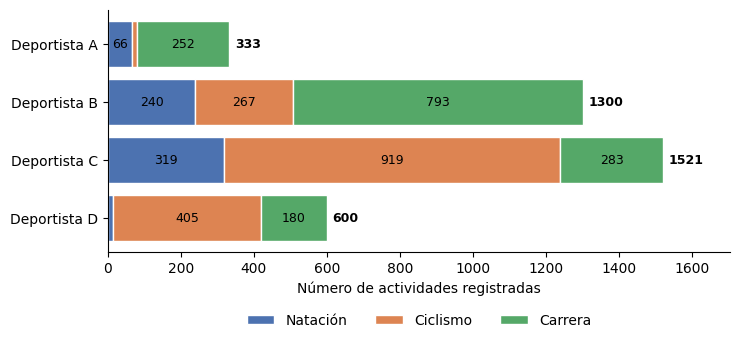

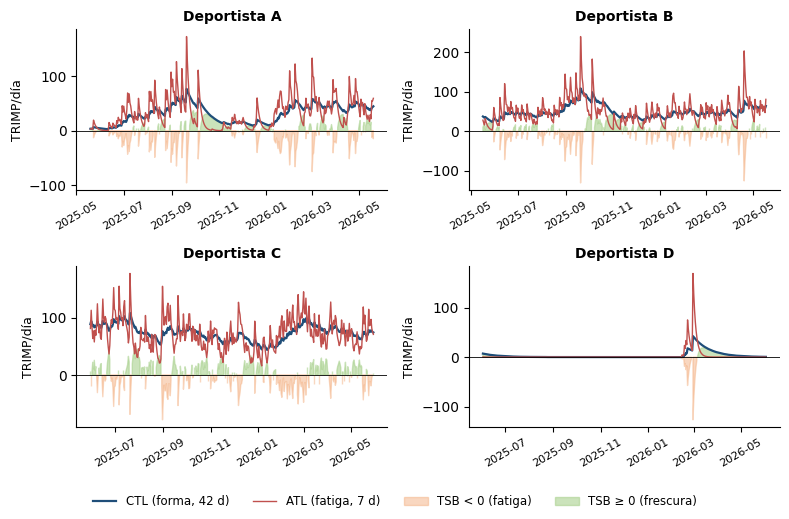

In [16]:
# Figuras de la fase 0
letras = list(garmin_data)
etiqueta = {l: f'Deportista {l}' for l in letras}

# Actividades registradas por deportista y disciplina
ct = df_act.groupby(['athlete', 'sport']).size().unstack(fill_value=0).reindex(letras)
fig, ax = plt.subplots(figsize=(7.5, 3.6))
colores = {'SWIMMING': '#4C72B0', 'CYCLING': '#DD8452', 'RUNNING': '#55A868'}
nombres = {'SWIMMING': 'Natación', 'CYCLING': 'Ciclismo', 'RUNNING': 'Carrera'}
izq = np.zeros(len(letras))
for sp in ['SWIMMING', 'CYCLING', 'RUNNING']:
    v = ct.get(sp, pd.Series(0, index=ct.index)).values
    ax.barh([etiqueta[l] for l in letras], v, left=izq, color=colores[sp], label=nombres[sp], edgecolor='white')
    for i, (l0, val) in enumerate(zip(izq, v)):
        if val >= 60:
            ax.text(l0 + val / 2, i, str(val), ha='center', va='center', fontsize=9)
    izq += v
for i, t in enumerate(izq):
    ax.text(t + 15, i, f'{int(t)}', va='center', fontsize=9, fontweight='bold')
ax.invert_yaxis(); ax.set_xlabel('Número de actividades registradas')
ax.legend(ncol=3, loc='upper center', bbox_to_anchor=(0.5, -0.2), frameon=False); ax.set_xlim(0, max(izq) * 1.12)
ax.spines[['top', 'right']].set_visible(False)
plt.tight_layout(); plt.savefig('salidas/figuras/actividades_por_deportista.png', dpi=200); plt.show()

# CTL, ATL y TSB del último año de cada deportista
fig, axs = plt.subplots(2, 2, figsize=(8, 5.2))
for ax, l in zip(axs.flat, letras):
    d = fitness_data[l]
    d = d[d['date'] >= d['date'].max() - pd.Timedelta(days=365)]
    ax.plot(d['date'], d['CTL'], color='#1f4e79', lw=1.6, label='CTL (forma, 42 d)')
    ax.plot(d['date'], d['ATL'], color='#c0504d', lw=1.0, label='ATL (fatiga, 7 d)')
    ax.fill_between(d['date'], d['TSB'], 0, where=d['TSB'] < 0, color='#f4b183', alpha=0.5, label='TSB < 0 (fatiga)')
    ax.fill_between(d['date'], d['TSB'], 0, where=d['TSB'] >= 0, color='#a9d18e', alpha=0.6, label='TSB ≥ 0 (frescura)')
    ax.axhline(0, color='black', lw=0.6); ax.set_title(etiqueta[l], fontsize=10)
    ax.tick_params(axis='x', labelsize=8, rotation=30); ax.spines[['top', 'right']].set_visible(False)
    ax.set_ylabel('TRIMP/día', fontsize=9)
h, lab = axs[0, 0].get_legend_handles_labels()
fig.legend(h, lab, ncol=4, loc='lower center', frameon=False, fontsize=8.5)
plt.tight_layout(rect=(0, 0.06, 1, 1)); plt.savefig('salidas/figuras/ctl_atl_tsb_ultimo_anio.png', dpi=200); plt.show()

**Hallazgos de la fase 0.** La regla de validez del lector descarta 17 de las 3.771 actividades leídas: una
fechada el 31/12/1989 (el origen de tiempo de Garmin, que aparece cuando el reloj no tiene la fecha), una
sesión de ciclismo de 34 horas, una de natación de 12 horas y 14 sin duración. Ninguna tenía carga calculable,
así que CTL, ATL y TSB no cambian. Además, cuatro velocidades imposibles quedan como ausentes.

Quedan 3.754 actividades (1.606 de ciclismo, 1.508 de carrera y 640 de natación), pero la carga TRIMP solo se
puede calcular en 2.436 (64,9 %), porque falta la frecuencia cardíaca. El caso extremo es D, con FC en el 8,8 %
de sus actividades: su CTL es casi nula y cualquier decisión basada en la carga no es fiable para él. Los
historiales son muy desiguales: A apenas tiene 15 sesiones de ciclismo, que es justo la situación que debe
resolver la fase 1.

## 4. Variables de cada deportista en los últimos 90 días

Para cada deportista se resumen los últimos 90 días en siete categorías: sesión, intensidad, rendimiento,
fatiga, recuperación, técnica y ambiente (34 variables). Describen su estado reciente y aportan la FC de
reposo y las velocidades de referencia con las que después se calculan sus zonas y ritmos.

In [17]:
def build_athlete_profile(name):
    """Construye el vector de variables de un deportista. Si una variable no está
    disponible queda como ausente y el proceso continúa."""
    p = {'athlete': name}
    acts = df_act[df_act['athlete'] == name].copy()
    if acts.empty: return p

    cutoff = acts['date'].max() - pd.Timedelta(days=90)
    recent = acts[acts['date'] >= cutoff]
    if recent.empty: recent = acts.tail(30)

    # 1. Sesión
    p['sessions_per_week']  = len(recent) / 12.86   # 90 dias / 7
    p['avg_duration_min']   = recent['duration_min'].mean()
    for sp in ('RUNNING', 'CYCLING', 'SWIMMING'):
        p[f'sessions_{sp.lower()}'] = (recent['sport'] == sp).sum()

    # 2. Intensidad
    p['avg_hr']             = recent['avg_hr'].mean()
    p['avg_trimp_session']  = recent['TRIMP'].mean()
    p['weekly_trimp']       = recent['TRIMP'].sum() / 12.86
    fc_max = 185
    p['pct_z12'] = len(recent[recent['avg_hr'] < fc_max * 0.75]) / len(recent) * 100 if len(recent) else np.nan
    p['pct_z45'] = len(recent[recent['avg_hr'] > fc_max * 0.85]) / len(recent) * 100 if len(recent) else np.nan

    # 3. Rendimiento por disciplina
    run = recent[recent['sport'] == 'RUNNING']
    cyc = recent[recent['sport'] == 'CYCLING'].dropna(subset=['avg_speed_kmh'])
    swm = recent[recent['sport'] == 'SWIMMING']
    p['pace_running_kmh']  = run['avg_speed_kmh'].mean() if not run.empty else np.nan
    p['pace_cycling_kmh']  = cyc['avg_speed_kmh'].mean() if not cyc.empty else np.nan
    p['pace_swimming_kmh'] = swm['avg_speed_kmh'].mean() if not swm.empty else np.nan
    alt_median = (recent['start_altitude_m'].median()
                  if 'start_altitude_m' in recent.columns else np.nan)
    vo2_raw = recent['vo2max_activity'].dropna().mean()
    p['vo2max']            = corregir_vo2_altitud(vo2_raw, alt_median)
    p['train_altitude_m']  = alt_median

    # 4. Fatiga / HRV
    d = garmin_data.get(name, {})
    rd = d.get('readiness', pd.DataFrame())
    if not rd.empty:
        rd_r = rd.tail(90)
        p['hrv_weekly_avg']      = rd_r['hrv_weekly_avg'].median()
        p['hrv_factor_pct']      = rd_r['hrv_factor_pct'].median()
        p['readiness_score_avg'] = rd_r['readiness_score'].mean()
        p['recovery_time_avg_h'] = rd_r['recovery_time_h'].median()
    else:
        p['hrv_weekly_avg'] = p['hrv_factor_pct'] = p['readiness_score_avg'] = p['recovery_time_avg_h'] = np.nan

    # 5. Recuperación
    uds = d.get('uds', pd.DataFrame())
    if not uds.empty:
        uds_r = uds.tail(90)
        p['resting_hr']       = uds_r['resting_hr'].median()
        p['body_battery_avg'] = uds_r['body_battery'].mean()
        p['stress_avg']       = uds_r['stress_avg'].mean()
    else:
        p['resting_hr'] = p['body_battery_avg'] = p['stress_avg'] = np.nan

    sl = d.get('sleep', pd.DataFrame())
    if not sl.empty:
        sl_r = sl.tail(90)
        p['sleep_total_avg_min'] = sl_r['sleep_total_min'].mean()
        p['sleep_deep_pct']      = sl_r['sleep_deep_pct'].mean()
    else:
        p['sleep_total_avg_min'] = p['sleep_deep_pct'] = np.nan

    # 6. Técnica
    p['avg_cadence']    = recent['cadence'].mean()
    p['avg_stride_cm']  = run['stride_length_cm'].mean() if not run.empty else np.nan

    # 7. Ambiente: desnivel (D+ carga cardiovascular, D- carga excéntrica)
    # y altitud media, que condiciona el VO2max
    p['avg_elevation_gain_m'] = recent['elevation_m'].mean()
    p['avg_elevation_loss_m'] = (recent['elevation_loss_m'].mean()
                                  if 'elevation_loss_m' in recent.columns else np.nan)
    p['avg_start_altitude_m'] = (recent['start_altitude_m'].mean()
                                  if 'start_altitude_m' in recent.columns else np.nan)
    p['avg_temp'] = ((recent['min_temp'].fillna(0) + recent['max_temp'].fillna(0)) / 2).mean()

    # Estado fitness-fatiga actual
    if name in fitness_data:
        fd = fitness_data[name]
        p['ctl_current'] = fd['CTL'].iloc[-1]
        p['atl_current'] = fd['ATL'].iloc[-1]
        p['tsb_current'] = fd['TSB'].iloc[-1]
        p['ctl_trend_30d'] = fd['CTL'].iloc[-1] - fd['CTL'].iloc[-30]
    else:
        p['ctl_current'] = p['atl_current'] = p['tsb_current'] = p['ctl_trend_30d'] = np.nan

    return p

athlete_profiles = [build_athlete_profile(n) for n in garmin_data]
df_profiles = pd.DataFrame(athlete_profiles).set_index('athlete')
print(f"Perfiles construidos: {df_profiles.shape}")
df_profiles.round(2)

Perfiles construidos: (4, 34)


,sessions_per_week,avg_duration_min,sessions_running,sessions_cycling,sessions_swimming,avg_hr,avg_trimp_session,weekly_trimp,pct_z12,pct_z45,pace_running_kmh,pace_cycling_kmh,pace_swimming_kmh,vo2max,train_altitude_m,hrv_weekly_avg,hrv_factor_pct,readiness_score_avg,recovery_time_avg_h,resting_hr,body_battery_avg,stress_avg,sleep_total_avg_min,sleep_deep_pct,avg_cadence,avg_stride_cm,avg_elevation_gain_m,avg_elevation_loss_m,avg_start_altitude_m,avg_temp,ctl_current,atl_current,tsb_current,ctl_trend_30d
athlete,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,
A,4.28,51.19,23,5,27,129.55,75.85,324.42,69.09,12.73,6.59,10.15,2.56,42.83,NaN,NaN,NaN,NaN,NaN,53.00,49.10,27.52,423.12,19.84,133.58,77.63,164.07,130.25,NaN,0.00,44.50,59.10,-14.60,-0.20
B,3.65,64.94,28,7,12,140.36,106.44,389.01,42.55,12.77,10.16,18.62,2.41,51.88,NaN,NaN,NaN,NaN,NaN,54.00,30.66,30.56,405.40,21.72,140.88,119.81,240.58,225.45,NaN,19.06,63.70,80.50,-16.80,12.20
C,7.62,61.30,31,39,28,128.25,74.76,529.02,69.39,0.00,9.49,23.21,3.17,48.89,NaN,96.00,100.00,56.59,1095.50,49.00,31.67,35.52,406.76,19.92,170.61,92.44,125.06,133.16,NaN,5.27,74.10,70.70,3.40,-1.60
D,2.18,126.14,1,27,0,NaN,NaN,0.00,0.00,0.00,5.22,18.67,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,164.72,97.64,76.80,199.67,694.11,688.29,NaN,19.68,0.50,0.00,0.50,-1.40


## 5. Análisis exploratorio descartado: agrupamiento K-means

Se probó un agrupamiento K-means para asignar un perfil a cada deportista. Se descartó: con cuatro casos hay
que añadir una población de referencia sintética de 300 perfiles, los grupos no se separan (coeficiente de
silueta de 0,06 con k = 4) y el perfil no cambia el plan.

Se conserva solo como registro. Ningún resultado de esta sección se usa en el resto del cuaderno, se guarda
en `salidas/` ni lo utiliza la aplicación.

Silueta por k: {2: np.float64(0.81), 3: np.float64(0.065), 4: np.float64(0.062), 5: np.float64(0.067), 6: np.float64(0.075)}
k usado: 4 (silueta 0.062)


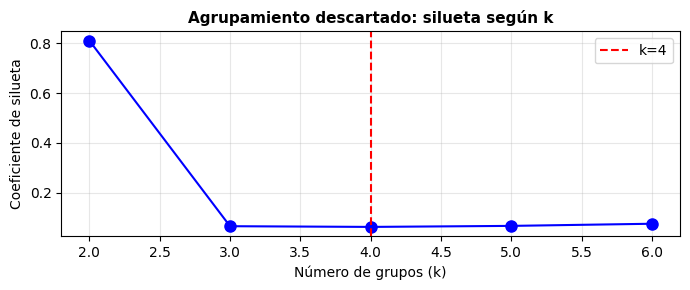

In [18]:
# Variables que entraban en el agrupamiento
cluster_features = ['sessions_per_week', 'weekly_trimp', 'pct_z12', 'pct_z45', 'avg_hr',
                    'resting_hr', 'body_battery_avg', 'stress_avg', 'sleep_deep_pct',
                    'avg_cadence', 'pace_running_kmh', 'ctl_current', 'tsb_current', 'vo2max']
cluster_features = [f for f in cluster_features if f in df_profiles.columns]
X_cluster = df_profiles[cluster_features]

# Con cuatro deportistas no se puede agrupar, así que se añade una población
# de referencia sintética de 300 perfiles con rangos orientados por los
# conjuntos públicos. Esa población es la principal debilidad del análisis.
np.random.seed(42); n_pub = 300
df_pub = pd.DataFrame({
    'sessions_per_week':  np.random.normal(5, 2, n_pub).clip(1, 14),
    'weekly_trimp':       np.random.normal(250, 100, n_pub).clip(20, 800),
    'avg_hr':             np.random.normal(148, 15, n_pub).clip(90, 185),
    'pct_z12':            np.random.normal(65, 15, n_pub).clip(0, 100),
    'pct_z45':            np.random.normal(10, 8, n_pub).clip(0, 100),
    'pace_running_kmh':   np.random.normal(10, 2, n_pub).clip(5, 18),
    'ctl_current':        np.random.normal(45, 20, n_pub).clip(3, 120),
    'tsb_current':        np.random.normal(-5, 15, n_pub).clip(-50, 30),
    'resting_hr':         np.random.normal(58, 8, n_pub).clip(40, 80),
    'body_battery_avg':   np.random.normal(55, 18, n_pub).clip(10, 95),
}).reindex(columns=cluster_features)

df_all_c = pd.concat([X_cluster, df_pub], ignore_index=True)
imp = SimpleImputer(strategy='median'); sc = StandardScaler()
X_all   = sc.fit_transform(imp.fit_transform(df_all_c[cluster_features]))
X_pers  = sc.transform(imp.transform(X_cluster[cluster_features]))

# Coeficiente de silueta para k entre 2 y 6
k_range = range(2, min(7, len(df_all_c)))
sil_scores = []
for k in k_range:
    km = KMeans(n_clusters=k, random_state=42, n_init=10)
    sil_scores.append(silhouette_score(X_all, km.fit_predict(X_all)))

best_k = 4   # número de grupos fijado en el diseño explorado; la silueta máxima está en k = 2
print(f"Silueta por k: {dict(zip(k_range, [round(s, 3) for s in sil_scores]))}")
print(f"k usado: {best_k} (silueta {sil_scores[list(k_range).index(best_k)]:.3f})")

fig, ax = plt.subplots(figsize=(7, 3))
ax.plot(list(k_range), sil_scores, 'bo-', markersize=8)
ax.axvline(best_k, color='red', linestyle='--', label=f'k={best_k}')
ax.set_xlabel('Número de grupos (k)'); ax.set_ylabel('Coeficiente de silueta')
ax.set_title('Agrupamiento descartado: silueta según k')
ax.legend(); ax.grid(True, alpha=0.3)
plt.tight_layout(); plt.show()

In [19]:
# Grupo asignado a cada deportista. Se guarda aparte para no mezclarlo con
# las variables que sí se usan (df_profiles).
kmeans = KMeans(n_clusters=best_k, random_state=42, n_init=20)
kmeans.fit(X_all)
grupo_kmeans = pd.Series(kmeans.predict(X_pers), index=X_cluster.index, name='grupo')
print("Grupo de cada deportista (solo informativo, no se usa):")
print(grupo_kmeans.to_string())

Grupo de cada deportista (solo informativo, no se usa):
athlete
A    0
B    0
C    2
D    3


**Hallazgo.** La silueta máxima (0,81) aparece con k = 2 y solo separa a D, cuyo vector está formado casi
por completo por valores imputados. Con k entre 3 y 6 no supera 0,08: los grupos no están separados. Por
eso el agrupamiento se descartó y ningún resultado de esta sección se usa después.

## 6. Fase 1 — Transferencia del rendimiento entre disciplinas

Objetivo: estimar a qué velocidad puede entrenar un deportista la disciplina que todavía no practica, a partir
de la que sí practica. Se necesitan dos modelos de regresión:

- **Modelo directo:** velocidad en ciclismo a partir de la velocidad de carrera y el sexo. Es el caso de A,
  que tiene 252 sesiones de carrera y solo 15 de ciclismo.
- **Modelo inverso:** velocidad de carrera a partir de la velocidad en ciclismo y el sexo, para el ciclista
  que empieza a correr.

Los modelos aprenden de resultados reales de pruebas 70.3; los cuatro deportistas no intervienen en el
entrenamiento, solo se les aplica el modelo al final. La sección sigue el orden habitual de un problema
supervisado:

1. **6a.** Preparar los datos.
2. **6b.** Comparar varios algoritmos de regresión y elegir uno.
3. **6c.** Optimizar los hiperparámetros del algoritmo elegido.
4. **6d.** Entrenar los modelos finales, explicarlos con SHAP y aplicarlos a los deportistas.
5. **6e y 6f.** Dos comprobaciones: si conviene añadir la natación y si bastan 80.000 registros.
6. **6g.** Resumen.

### 6a. Preparación de los datos

In [20]:
# Tiempos parciales reales de pruebas 70.3, convertidos a velocidades. La natación también se
# convierte, aunque solo se usa para comprobar cuánto aportaría como variable (sección 6e).

def _t2min(txt):
    if pd.isna(txt): return np.nan
    s = str(txt).strip()
    if not s or any(c.isalpha() for c in s): return np.nan
    p = s.split(':')
    try: p = [float(x) for x in p]
    except ValueError: return np.nan
    if len(p) == 3: return p[0]*60 + p[1] + p[2]/60
    if len(p) == 2: return p[0] + p[1]/60
    return np.nan

half = df_triathlon[
    df_triathlon['event_link'].astype(str).str.contains('/half/', na=False) |
    df_triathlon['event_name'].astype(str).str.contains('70.3', na=False)].copy()
for c_src, c_min in [('person_event_cycle_time_text', 'bike_min'),
                     ('person_event_run_time_text',  'run_min'),
                     ('person_event_swim_time_text', 'swim_min')]:
    half[c_min] = half[c_src].apply(_t2min)
half = half.dropna(subset=['bike_min', 'run_min'])
half = half[(half['bike_min'] > 0) & (half['run_min'] > 0)]
half['pace_cycling_kmh']  = 90.0 / (half['bike_min'] / 60.0)
half['running_speed_kmh'] = 21.1 / (half['run_min']  / 60.0)
half['swim_speed_kmh']    = 1.9  / (half['swim_min'] / 60.0)
half[['pace_cycling_kmh', 'running_speed_kmh', 'swim_speed_kmh']] = \
    half[['pace_cycling_kmh', 'running_speed_kmh', 'swim_speed_kmh']].replace([np.inf, -np.inf], np.nan)
half = half[half['pace_cycling_kmh'].between(15, 50) &
            half['running_speed_kmh'].between(5, 20)]
g = half['gender'].astype(str).str.upper().str[0]
half['sexo_M'] = np.where(g == 'M', 1.0, np.where(g.isin(['F', 'W']), 0.0, np.nan))
print(f"Registros válidos de 70.3 con ciclismo y carrera: {len(half):,}")
print(half[['pace_cycling_kmh','running_speed_kmh','swim_speed_kmh','sexo_M']].describe().round(2))

# Sesión válida para medir la velocidad sostenida: distancia y duración mínimas y velocidad plausible.
# Así no cuentan los desplazamientos cortos, el rodillo sin GPS ni las sesiones mal registradas.
# Es el mismo criterio que usa la aplicación.
SESION_VALIDA = {'CYCLING': dict(km=10, minutos=30, v_min=12, v_max=50),
                 'RUNNING': dict(km=3, minutos=15, v_min=5, v_max=20)}

def sesiones_validas(df_sport, deporte):
    c = SESION_VALIDA[deporte]
    ok = (df_sport['avg_speed_kmh'].between(c['v_min'], c['v_max'])
          & (df_sport['duration_min'] >= c['minutos']) & (df_sport['distance_km'] >= c['km']))
    return df_sport[ok]

# Velocidad sostenida de un deportista: percentil 80 de sus últimas 25 sesiones (las
# actividades están ordenadas por fecha). La media mezclaría rodajes suaves con esfuerzos
# intensos y subestimaría lo que el deportista puede mantener.
def ritmo_sostenido(df_sport, n=25, q=0.80):
    if df_sport.empty:
        return np.nan
    return df_sport.tail(n)['avg_speed_kmh'].quantile(q)

# Variables de cada modelo
FEATURE_COLS = ['running_speed_kmh', 'sexo_M']   # directo: carrera y sexo para estimar el ciclismo
FEAT_CYC2RUN = ['pace_cycling_kmh', 'sexo_M']    # inverso: ciclismo y sexo para estimar la carrera

# Una muestra aleatoria de 80.000 resultados para cada modelo. Con este tamaño la validación
# cruzada y la búsqueda de hiperparámetros caben en una sesión de Colab; la sección 6f
# comprueba que más datos no mejorarían el error.
df_dir = half.sample(min(len(half), 80000), random_state=42)[
    FEATURE_COLS + ['swim_speed_kmh', 'pace_cycling_kmh']].copy()
df_inv = half.sample(min(len(half), 80000), random_state=7)[
    FEAT_CYC2RUN + ['swim_speed_kmh', 'running_speed_kmh']].copy()
print(f"\nMuestras: {len(df_dir):,} resultados para el modelo directo y {len(df_inv):,} para el inverso")
print(f"Resultados sin sexo informado: {df_dir['sexo_M'].isna().sum()} en el directo y {df_inv['sexo_M'].isna().sum()} en el inverso")

# Las mismas cinco particiones en todas las pruebas, para que las diferencias se deban al
# modelo y no a cómo se repartieron los datos.
kf = KFold(n_splits=5, shuffle=True, random_state=42)

Registros válidos de 70.3 con ciclismo y carrera: 1,453,932
       pace_cycling_kmh  running_speed_kmh  swim_speed_kmh     sexo_M
count        1453932.00         1453932.00      1415997.00 1453932.00
mean              30.30              10.24            3.13       0.76
std                4.19               2.13            3.95       0.43
min               15.00               5.00            0.18       0.00
25%               27.42               8.67            2.56       1.00
50%               30.29              10.13            2.93       1.00
75%               33.12              11.66            3.36       1.00
max               50.00              19.99          244.29       1.00

Muestras: 80,000 resultados para el modelo directo y 80,000 para el inverso
Resultados sin sexo informado: 0 en el directo y 0 en el inverso


### 6b. ¿Qué algoritmo usar? Comparación de modelos de regresión

Antes de elegir un algoritmo se comparan los principales modelos de regresión, todos con las mismas filas, las
mismas variables y las mismas cinco particiones:

| Modelo | Por qué se prueba |
|---|---|
| Regresión lineal | El modelo más simple e interpretable; sirve de referencia. Supone una relación en línea recta |
| k vecinos más próximos (kNN) | Aprende por analogía con los resultados más parecidos; no supone ninguna forma |
| Máquina de vectores de soporte (SVR) | Con kernel RBF recoge relaciones no lineales |
| Árbol de decisión | Interpretable, pero un solo árbol tiende al sobreajuste |
| Random Forest | Conjunto de árboles por bagging; reduce la varianza del árbol individual |
| Gradient Boosting | Conjunto de árboles por boosting: cada árbol corrige los errores de los anteriores |
| XGBoost | Implementación de gradient boosting con regularización y tratamiento propio de los valores ausentes |

Cada modelo se prueba con una configuración razonable; solo el elegido se optimiza después (6c). kNN y SVR
necesitan las variables en la misma escala, así que se estandarizan. SVR se entrena con 10.000 filas de cada
partición, porque su coste crece muy rápido con el número de datos.

**Cómo se elige.** La métrica principal es el **MAE** (error absoluto medio, en km/h), porque es el error que
notará el deportista en su ritmo y se traduce directamente a minutos. También se miran el RMSE, el R², la
estabilidad entre particiones y la diferencia entre el error de entrenamiento y el de validación (sobreajuste).
Los modelos que quedan a menos de una desviación estándar del mejor se consideran empatados. Entre ellos se
prefiere, por este orden:

1. Un algoritmo que esté entre los mejores **en las dos direcciones**. La aplicación usa los dos modelos a la
   vez, y un mismo método simplifica entrenarlos, explicarlos y reentrenarlos.
2. Una predicción que cambie **de forma gradual** con la velocidad de entrada. Un ritmo de entrenamiento no
   debería saltar a escalones: dos deportistas con velocidades parecidas deben recibir referencias parecidas.
3. Menor tiempo de predicción, menor tamaño y mayor facilidad para explicar cada predicción.

In [21]:
import time, pickle
from sklearn.base import BaseEstimator, RegressorMixin, clone
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression
from sklearn.neighbors import KNeighborsRegressor
from sklearn.svm import SVR
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor

class ConSubmuestra(BaseEstimator, RegressorMixin):
    """Entrena el modelo con una muestra aleatoria de n filas. Se usa para SVR, que con
    64.000 filas tardaría demasiado; la validación se hace igualmente con todas las filas."""
    def __init__(self, modelo, n=10_000, semilla=42):
        self.modelo, self.n, self.semilla = modelo, n, semilla
    def fit(self, X, y):
        idx = np.random.default_rng(self.semilla).choice(len(X), min(self.n, len(X)), replace=False)
        self.modelo_ = clone(self.modelo).fit(X[idx], y[idx])
        return self
    def predict(self, X):
        return self.modelo_.predict(X)

# Configuración de partida de XGBoost: tasa de aprendizaje baja con bastantes árboles y un 80 %
# de las filas en cada árbol, dos formas de evitar el sobreajuste en boosting. No se reparten
# las variables entre árboles (colsample_bytree = 1): con solo dos, cada árbol se quedaría con
# una y no podría combinar velocidad y sexo.
PARAMS_XGB = dict(n_estimators=400, max_depth=5, learning_rate=0.05, subsample=0.8,
                  colsample_bytree=1.0, missing=np.nan, random_state=42, n_jobs=-1)

MODELOS = {
    'Regresión lineal':  LinearRegression(),
    'kNN (k = 50)':      make_pipeline(StandardScaler(), KNeighborsRegressor(n_neighbors=50)),
    'SVR (kernel RBF)':  ConSubmuestra(make_pipeline(StandardScaler(), SVR(C=1.0, epsilon=0.5))),
    'Árbol de decisión': DecisionTreeRegressor(max_depth=6, min_samples_leaf=20, random_state=42),
    'Random Forest':     RandomForestRegressor(n_estimators=300, min_samples_leaf=20, n_jobs=-1, random_state=42),
    'Gradient Boosting': GradientBoostingRegressor(n_estimators=400, learning_rate=0.05, max_depth=5,
                                                   subsample=0.8, random_state=42),
    'XGBoost':           xgb.XGBRegressor(**PARAMS_XGB),
}

def comparar(datos, variables, objetivo):
    X, y = datos[variables].values, datos[objetivo].values
    filas = []
    for nombre, modelo in MODELOS.items():
        t0 = time.time()
        cv = cross_validate(modelo, X, y, cv=kf, return_train_score=True, return_estimator=True,
                            scoring=('neg_mean_absolute_error', 'neg_root_mean_squared_error', 'r2'))
        t_cv = time.time() - t0
        t1 = time.time(); cv['estimator'][0].predict(X[:10_000]); t_pred = (time.time() - t1) * 1000
        filas.append({'Modelo': nombre,
                      'MAE (km/h)':        -cv['test_neg_mean_absolute_error'].mean(),
                      'MAE d. t.':          cv['test_neg_mean_absolute_error'].std(),
                      'RMSE (km/h)':       -cv['test_neg_root_mean_squared_error'].mean(),
                      'R² validación':      cv['test_r2'].mean(),
                      'R² entrenamiento':   cv['train_r2'].mean(),
                      'Tiempo de validación cruzada (s)': t_cv,
                      'Predecir 10.000 (ms)': t_pred,
                      'Tamaño (KB)':        len(pickle.dumps(cv['estimator'][0])) / 1024})
    tabla = pd.DataFrame(filas).set_index('Modelo').sort_values('MAE (km/h)')
    mejor = tabla.iloc[0]
    tabla['Empata con el mejor'] = np.where(tabla['MAE (km/h)'] <= mejor['MAE (km/h)'] + mejor['MAE d. t.'], 'sí', 'no')
    return tabla

print("Comparando modelos (puede tardar unos minutos)...")
comp_dir = comparar(df_dir, FEATURE_COLS, 'pace_cycling_kmh')
comp_inv = comparar(df_inv, FEAT_CYC2RUN, 'running_speed_kmh')
pd.set_option('display.float_format', '{:.3f}'.format)
print("Modelo directo (carrera y sexo, para estimar el ciclismo)")
display(comp_dir)
print("Modelo inverso (ciclismo y sexo, para estimar la carrera)")
display(comp_inv)
pd.set_option('display.float_format', '{:.2f}'.format)

Comparando modelos (puede tardar unos minutos)...
Modelo directo (carrera y sexo, para estimar el ciclismo)


,MAE (km/h),MAE d. t.,RMSE (km/h),R² validación,R² entrenamiento,Tiempo de validación cruzada (s),Predecir 10.000 (ms),Tamaño (KB),Empata con el mejor
Modelo,,,,,,,,,
SVR (kernel RBF),2.372,0.010,3.039,0.468,0.468,201.114,3651.427,236.303,sí
Regresión lineal,2.375,0.009,3.038,0.469,0.469,0.094,0.247,0.426,sí
Árbol de decisión,2.379,0.010,3.041,0.467,0.472,0.336,0.875,9.958,sí
XGBoost,2.380,0.009,3.041,0.467,0.474,11.632,63.597,886.620,sí
Gradient Boosting,2.381,0.007,3.048,0.465,0.490,114.904,74.099,1507.815,sí
kNN (k = 50),2.400,0.008,3.066,0.459,0.481,10.330,209.545,2257.480,no
Random Forest,2.418,0.007,3.087,0.451,0.500,138.887,393.227,62707.505,no


Modelo inverso (ciclismo y sexo, para estimar la carrera)


,MAE (km/h),MAE d. t.,RMSE (km/h),R² validación,R² entrenamiento,Tiempo de validación cruzada (s),Predecir 10.000 (ms),Tamaño (KB),Empata con el mejor
Modelo,,,,,,,,,
SVR (kernel RBF),1.248,0.005,1.579,0.457,0.457,172.183,3171.116,206.571,sí
XGBoost,1.251,0.006,1.580,0.457,0.463,7.694,63.540,897.310,sí
Árbol de decisión,1.252,0.006,1.580,0.457,0.461,0.320,0.924,9.817,sí
Gradient Boosting,1.252,0.006,1.585,0.453,0.477,115.565,75.626,1489.613,sí
kNN (k = 50),1.261,0.006,1.591,0.449,0.470,9.884,213.560,2257.480,no
Regresión lineal,1.263,0.007,1.598,0.444,0.444,0.075,0.273,0.426,no
Random Forest,1.267,0.007,1.600,0.443,0.489,108.637,370.218,61891.880,no


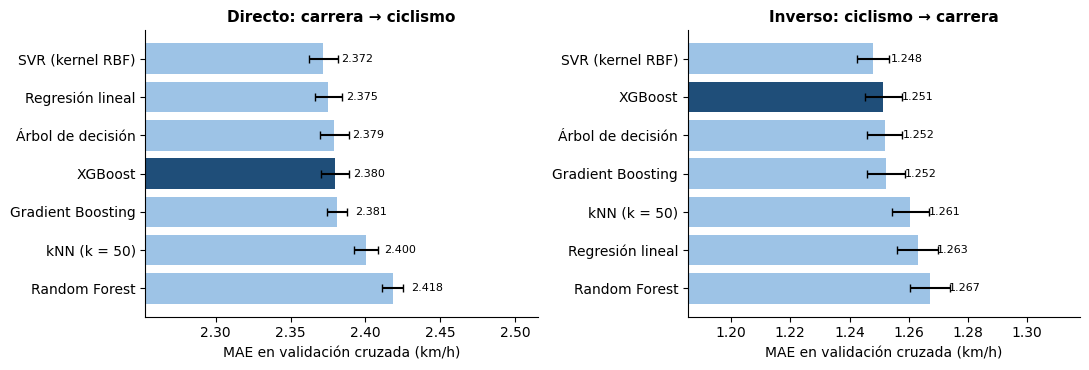

In [22]:
# Error de validación de cada modelo, con su variación entre particiones
fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))
for ax, (titulo, tabla) in zip(axes, [('Directo: carrera → ciclismo', comp_dir),
                                      ('Inverso: ciclismo → carrera', comp_inv)]):
    t = tabla.sort_values('MAE (km/h)', ascending=False)
    colores = ['#1f4e79' if n == 'XGBoost' else '#9dc3e6' for n in t.index]
    ax.barh(t.index, t['MAE (km/h)'], xerr=t['MAE d. t.'], color=colores, capsize=3)
    for i, v in enumerate(t['MAE (km/h)']):
        ax.text(v * 1.005, i, f'{v:.3f}', va='center', fontsize=8)
    ax.set_xlim(t['MAE (km/h)'].min() * 0.95, t['MAE (km/h)'].max() * 1.04)
    ax.set_title(titulo); ax.set_xlabel('MAE en validación cruzada (km/h)')
    ax.spines[['top', 'right']].set_visible(False)
plt.tight_layout(); plt.savefig('salidas/figuras/comparacion_modelos.png', dpi=200); plt.show()

Regresión lineal: 200 valores distintos de predicción en 200 velocidades
Árbol de decisión: 30 valores distintos de predicción en 200 velocidades
kNN (k = 50): 199 valores distintos de predicción en 200 velocidades
XGBoost: 160 valores distintos de predicción en 200 velocidades


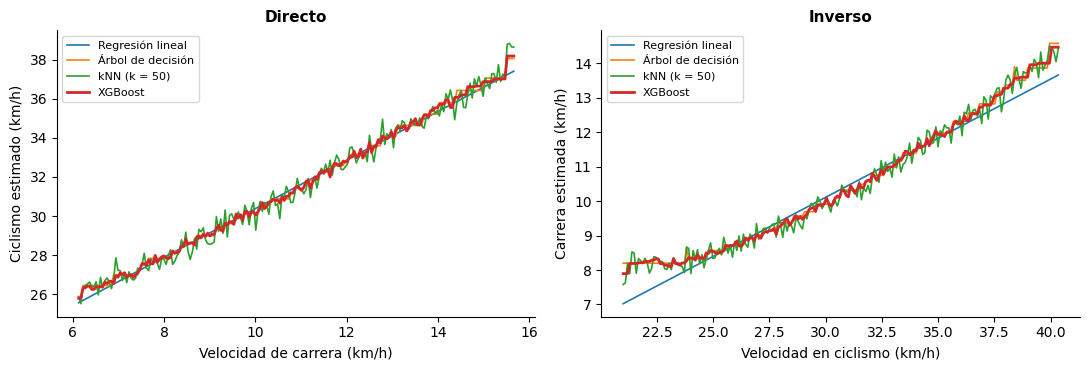

In [23]:
# Cómo responde cada modelo a la velocidad de entrada (hombres; las mujeres siguen el mismo patrón).
# Sirve para ver si la relación es recta o curva y si la predicción cambia de forma gradual.
MUESTRA_CURVA = {'Regresión lineal': LinearRegression(),
                 'Árbol de decisión': DecisionTreeRegressor(max_depth=6, min_samples_leaf=20, random_state=42),
                 'kNN (k = 50)': make_pipeline(StandardScaler(), KNeighborsRegressor(n_neighbors=50)),
                 'XGBoost': xgb.XGBRegressor(**PARAMS_XGB)}
fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))
for ax, (titulo, datos, variables, objetivo, entrada, salida) in zip(axes, [
        ('Directo', df_dir, FEATURE_COLS, 'pace_cycling_kmh', 'Velocidad de carrera (km/h)', 'Ciclismo estimado (km/h)'),
        ('Inverso', df_inv, FEAT_CYC2RUN, 'running_speed_kmh', 'Velocidad en ciclismo (km/h)', 'Carrera estimada (km/h)')]):
    x0 = datos[variables[0]]
    rejilla_x = np.linspace(x0.quantile(0.01), x0.quantile(0.99), 200)
    X_curva = np.column_stack([rejilla_x, np.ones_like(rejilla_x)])
    for nombre, modelo in MUESTRA_CURVA.items():
        modelo.fit(datos[variables].values, datos[objetivo].values)
        pred = modelo.predict(X_curva)
        ax.plot(rejilla_x, pred, lw=2 if nombre == 'XGBoost' else 1.2, label=nombre)
        if titulo == 'Directo':
            print(f"{nombre}: {len(np.unique(np.round(pred, 3)))} valores distintos de predicción en 200 velocidades")
    ax.set_xlabel(entrada); ax.set_ylabel(salida); ax.set_title(titulo); ax.legend(fontsize=8)
    ax.spines[['top', 'right']].set_visible(False)
plt.tight_layout(); plt.savefig('salidas/figuras/curva_respuesta_modelos.png', dpi=200); plt.show()

**Hallazgo.** Los modelos razonables empatan. En el modelo directo, cinco quedan a menos de una desviación
estándar del mejor, con un MAE entre 2,372 y 2,381 km/h: SVR, regresión lineal, árbol de decisión, XGBoost y
Gradient Boosting. En el inverso empatan cuatro, entre 1,248 y 1,252 km/h: SVR, XGBoost, árbol de decisión y
Gradient Boosting. Random Forest y kNN quedan por detrás en los dos y son los que más sobreajustan.

Aplicando los criterios de desempate:

1. **Las dos direcciones.** La regresión lineal empata en el directo, pero en el inverso es claramente peor
   (1,263 km/h). Se descarta.
2. **Predicción gradual.** El árbol de decisión devuelve solo 30 valores distintos en 200 velocidades de carrera:
   avanza a escalones. XGBoost devuelve 160. Se descarta el árbol.
3. **Velocidad, tamaño y estabilidad.** SVR tarda unas 47 veces más en predecir que XGBoost (3,6 s frente a
   78 ms por cada 10.000 casos) y solo se pudo entrenar con 10.000 filas. Gradient Boosting tarda unas diez
   veces más en validarse (115 s frente a 11 s) y sobreajusta más (R² de entrenamiento 0,490 frente a 0,465 de
   validación; XGBoost, 0,474 frente a 0,467).

**Se elige XGBoost.** La curva de respuesta deja un resultado interesante: de la carrera al ciclismo la
relación es prácticamente una recta (la regresión lineal iguala a los modelos no lineales), mientras que del
ciclismo a la carrera hay curvatura, sobre todo en los extremos de velocidad.

### 6c. Optimización de los hiperparámetros de XGBoost

Una vez elegido el algoritmo, se buscan sus mejores hiperparámetros, por separado para el modelo directo y el
inverso. El procedimiento sigue tres pasos:

1. **Conjunto de prueba.** Se aparta un 30 % de los datos, que no se usa en ninguna decisión; solo sirve
   para medir al final, sin sesgo, cuánto mejora la optimización. La búsqueda se hace con el 70 % restante y
   validación cruzada de cinco particiones.
2. **Exploración con búsqueda aleatoria** (`RandomizedSearchCV`). Prueba 50 combinaciones al azar dentro de
   rangos amplios de siete hiperparámetros, para localizar la zona donde está la mejor configuración sin
   probar todas las combinaciones.
3. **Explotación con búsqueda en rejilla** (`GridSearchCV`). Prueba todas las combinaciones de una rejilla
   pequeña centrada en el mejor resultado de la búsqueda aleatoria, para afinar los tres hiperparámetros que
   más pesan: número de árboles, tasa de aprendizaje y profundidad.

Antes, una curva de validación muestra cómo cambia el error con la profundidad de los árboles: hasta dónde
mejora y desde dónde el modelo empieza a sobreajustar.

Directo: 56,000 filas para la búsqueda y 24,000 para la prueba
Inverso: 56,000 filas para la búsqueda y 24,000 para la prueba
Directo, MAE de validación por profundidad: 1: 2.378, 2: 2.378, 3: 2.379, 4: 2.381, 5: 2.383, 6: 2.386, 8: 2.389, 10: 2.389
Inverso, MAE de validación por profundidad: 1: 1.249, 2: 1.249, 3: 1.249, 4: 1.250, 5: 1.251, 6: 1.252, 8: 1.253, 10: 1.254


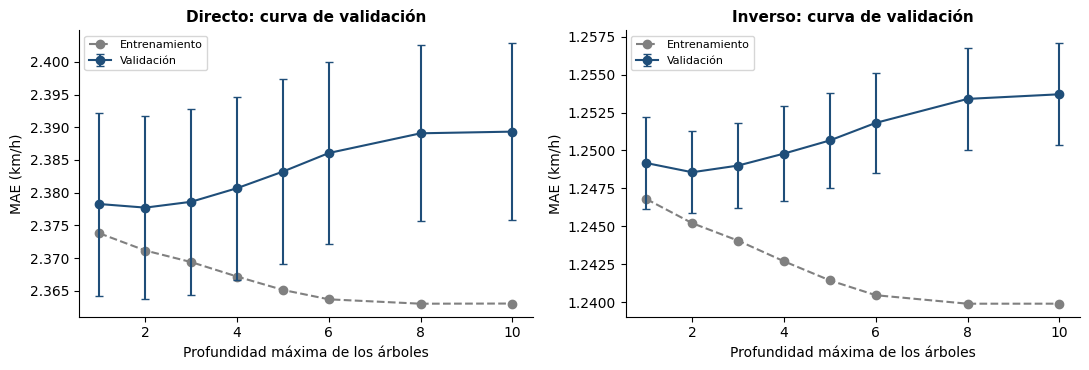

In [24]:
from sklearn.model_selection import validation_curve, RandomizedSearchCV, GridSearchCV
from scipy.stats import randint, uniform, loguniform

# 70 % para buscar los hiperparámetros y 30 % reservado para la prueba final
PARTES = {}
for nombre, datos, variables, objetivo in [('Directo', df_dir, FEATURE_COLS, 'pace_cycling_kmh'),
                                           ('Inverso', df_inv, FEAT_CYC2RUN, 'running_speed_kmh')]:
    PARTES[nombre] = train_test_split(datos[variables].values, datos[objetivo].values,
                                      test_size=0.30, random_state=42)
    print(f"{nombre}: {len(PARTES[nombre][0]):,} filas para la búsqueda y {len(PARTES[nombre][1]):,} para la prueba")

# Curva de validación: error según la profundidad de los árboles
profundidades = [1, 2, 3, 4, 5, 6, 8, 10]
fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))
for ax, (nombre, (X_tr, X_te, y_tr, y_te)) in zip(axes, PARTES.items()):
    tr, va = validation_curve(xgb.XGBRegressor(**PARAMS_XGB), X_tr, y_tr, param_name='max_depth',
                              param_range=profundidades, cv=kf, scoring='neg_mean_absolute_error')
    ax.plot(profundidades, -tr.mean(1), 'o--', color='grey', label='Entrenamiento')
    ax.errorbar(profundidades, -va.mean(1), yerr=va.std(1), fmt='o-', color='#1f4e79', capsize=3,
                label='Validación')
    ax.set_xlabel('Profundidad máxima de los árboles'); ax.set_ylabel('MAE (km/h)')
    ax.set_title(f'{nombre}: curva de validación'); ax.legend(fontsize=8)
    ax.spines[['top', 'right']].set_visible(False)
    print(f"{nombre}, MAE de validación por profundidad: "
          + ', '.join(f'{d}: {m:.3f}' for d, m in zip(profundidades, -va.mean(1))))
plt.tight_layout(); plt.savefig('salidas/figuras/curva_validacion_profundidad.png', dpi=200); plt.show()

In [25]:
# Paso 2. Exploración: búsqueda aleatoria en rangos amplios
ESPACIO = {
    'n_estimators':     randint(100, 1201),
    'learning_rate':    loguniform(0.01, 0.3),
    'max_depth':        randint(2, 9),
    'min_child_weight': randint(1, 51),
    'subsample':        uniform(0.6, 0.4),      # entre 0,6 y 1,0
    'reg_lambda':       loguniform(0.1, 10),
    'gamma':            uniform(0, 1),
}
ALEATORIA = {}
for nombre, (X_tr, X_te, y_tr, y_te) in PARTES.items():
    t0 = time.time()
    busq = RandomizedSearchCV(xgb.XGBRegressor(**{**PARAMS_XGB, 'n_jobs': 1}), ESPACIO, n_iter=50, cv=kf,
                              scoring='neg_mean_absolute_error', random_state=42, n_jobs=-1)
    busq.fit(X_tr, y_tr)
    ALEATORIA[nombre] = busq
    res = pd.DataFrame(busq.cv_results_)
    print(f"\n{nombre} ({time.time() - t0:.0f} s): mejor MAE {-busq.best_score_:.4f} km/h; "
          f"entre las {len(res)} combinaciones el MAE va de {-res['mean_test_score'].max():.3f} a {-res['mean_test_score'].min():.3f}")
    print("  Mejores valores:", {k: (round(v, 3) if isinstance(v, float) else v) for k, v in busq.best_params_.items()})


Directo (373 s): mejor MAE 2.3774 km/h; entre las 50 combinaciones el MAE va de 2.377 a 2.390
  Mejores valores: {'gamma': np.float64(0.887), 'learning_rate': np.float64(0.011), 'max_depth': 3, 'min_child_weight': 2, 'n_estimators': 826, 'reg_lambda': np.float64(2.208), 'subsample': np.float64(0.731)}

Inverso (351 s): mejor MAE 1.2483 km/h; entre las 50 combinaciones el MAE va de 1.248 a 1.254
  Mejores valores: {'gamma': np.float64(0.349), 'learning_rate': np.float64(0.014), 'max_depth': 2, 'min_child_weight': 33, 'n_estimators': 650, 'reg_lambda': np.float64(7.472), 'subsample': np.float64(0.655)}


In [26]:
# Paso 3. Explotación: rejilla pequeña alrededor del mejor resultado de la búsqueda aleatoria.
# Se afinan los tres hiperparámetros que más pesan; el resto se queda con el valor encontrado.
REJILLA = {}
for nombre, (X_tr, X_te, y_tr, y_te) in PARTES.items():
    b = ALEATORIA[nombre].best_params_
    rejilla = {
        'n_estimators':  sorted({max(50, int(round(b['n_estimators'] * f / 50) * 50)) for f in (0.75, 1.0, 1.25)}),
        'learning_rate': sorted({round(b['learning_rate'] * f, 4) for f in (0.67, 1.0, 1.5)}),
        'max_depth':     sorted({d for d in (b['max_depth'] - 1, b['max_depth'], b['max_depth'] + 1) if d >= 1}),
    }
    fijos = {k: v for k, v in b.items() if k not in rejilla}
    t0 = time.time()
    busq = GridSearchCV(xgb.XGBRegressor(**{**PARAMS_XGB, **fijos, 'n_jobs': 1}), rejilla, cv=kf,
                        scoring='neg_mean_absolute_error', n_jobs=-1, return_train_score=True)
    busq.fit(X_tr, y_tr)
    REJILLA[nombre] = busq
    print(f"\n{nombre} ({time.time() - t0:.0f} s, {len(busq.cv_results_['params'])} combinaciones): "
          f"mejor MAE {-busq.best_score_:.4f} km/h con {busq.best_params_}")
    top = pd.DataFrame(busq.cv_results_).sort_values('rank_test_score').head(5)
    display(pd.DataFrame({'Árboles': top['param_n_estimators'], 'Tasa': top['param_learning_rate'],
                          'Profundidad': top['param_max_depth'], 'MAE validación': -top['mean_test_score'],
                          'MAE entrenamiento': -top['mean_train_score']}).round(4))


Directo (233 s, 27 combinaciones): mejor MAE 2.3773 km/h con {'learning_rate': np.float64(0.0074), 'max_depth': 3, 'n_estimators': 1050}


,Árboles,Tasa,Profundidad,MAE validación,MAE entrenamiento
5,1050,0.01,3,2.38,2.37
10,850,0.01,2,2.38,2.37
11,1050,0.01,2,2.38,2.37
18,600,0.02,2,2.38,2.37
4,850,0.01,3,2.38,2.37



Inverso (145 s, 27 combinaciones): mejor MAE 1.2482 km/h con {'learning_rate': np.float64(0.0208), 'max_depth': 2, 'n_estimators': 500}


,Árboles,Tasa,Profundidad,MAE validación,MAE entrenamiento
21,500,0.02,2,1.25,1.25
14,800,0.01,2,1.25,1.25
22,650,0.02,2,1.25,1.25
13,650,0.01,2,1.25,1.25
23,800,0.02,2,1.25,1.25


In [27]:
# Resultado en el 30 % reservado: regresión lineal, configuración de partida y configuración optimizada
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

def a_python(v):
    return float(v) if isinstance(v, np.floating) else int(v) if isinstance(v, np.integer) else v

filas = []
PARAMS_FINALES = {}
for nombre, (X_tr, X_te, y_tr, y_te) in PARTES.items():
    optimos = {**ALEATORIA[nombre].best_params_, **REJILLA[nombre].best_params_}
    PARAMS_FINALES[nombre] = {**PARAMS_XGB, **{k: a_python(v) for k, v in optimos.items()}}
    candidatos = [('Regresión lineal', LinearRegression()),
                  ('XGBoost, configuración de partida', xgb.XGBRegressor(**PARAMS_XGB)),
                  ('XGBoost, configuración optimizada', xgb.XGBRegressor(**PARAMS_FINALES[nombre]))]
    for etiqueta, modelo in candidatos:
        p = modelo.fit(X_tr, y_tr).predict(X_te)
        filas.append({'Modelo': nombre, 'Configuración': etiqueta,
                      'MAE prueba (km/h)': mean_absolute_error(y_te, p),
                      'RMSE prueba (km/h)': mean_squared_error(y_te, p) ** 0.5,
                      'R² prueba': r2_score(y_te, p)})
prueba = pd.DataFrame(filas).set_index(['Modelo', 'Configuración'])
pd.set_option('display.float_format', '{:.4f}'.format); display(prueba)
pd.set_option('display.float_format', '{:.2f}'.format)

# Hiperparámetros con los que se entrenan los modelos finales
PARAMS_DIR, PARAMS_INV = PARAMS_FINALES['Directo'], PARAMS_FINALES['Inverso']
for nombre, p in PARAMS_FINALES.items():
    print(f"{nombre}:", {k: (round(v, 4) if isinstance(v, float) else v) for k, v in p.items()
                         if k not in ('missing', 'n_jobs', 'random_state')})

MAE prueba (km/h)  \
Modelo  Configuración                                          
Directo Regresión lineal                              2.3691   
        XGBoost, configuración de partida             2.3734   
        XGBoost, configuración optimizada             2.3687   
Inverso Regresión lineal                              1.2668   
        XGBoost, configuración de partida             1.2559   
        XGBoost, configuración optimizada             1.2545   

                                           RMSE prueba (km/h)  R² prueba  
Modelo  Configuración                                                     
Directo Regresión lineal                               3.0353     0.4712  
        XGBoost, configuración de partida              3.0382     0.4702  
        XGBoost, configuración optimizada              3.0338     0.4717  
Inverso Regresión lineal                               1.6010     0.4455  
        XGBoost, configuración de partida              1.5826     0.4581  
        XGBoost, configuración optimizada              1.5816     0.4588

Directo: {'n_estimators': 1050, 'max_depth': 3, 'learning_rate': 0.0074, 'subsample': 0.7313, 'colsample_bytree': 1.0, 'gamma': 0.8866, 'min_child_weight': 2, 'reg_lambda': 2.2083}
Inverso: {'n_estimators': 500, 'max_depth': 2, 'learning_rate': 0.0208, 'subsample': 0.655, 'colsample_bytree': 1.0, 'gamma': 0.3487, 'min_child_weight': 33, 'reg_lambda': 7.4724}


**Hallazgo.** Optimizar apenas cambia el resultado. Entre las 50 combinaciones de la búsqueda aleatoria, el MAE
de validación solo va de 2,377 a 2,390 km/h en el modelo directo y de 1,248 a 1,254 km/h en el inverso. La curva
de validación muestra que los árboles poco profundos (de 1 a 3 niveles) generalizan mejor; a partir de ahí el
error de entrenamiento sigue bajando, pero el de validación sube: empieza el sobreajuste.

Tras la rejilla, los hiperparámetros finales son:

- **Directo:** 1.050 árboles, tasa de aprendizaje 0,0074 y profundidad 3.
- **Inverso:** 500 árboles, tasa de aprendizaje 0,021 y profundidad 2.

En el 30 % reservado, el MAE baja de 2,373 a 2,369 km/h en el directo y de 1,256 a 1,255 km/h en el inverso. En
el directo, la regresión lineal da el mismo error que XGBoost optimizado (2,369 km/h). Modelos y
configuraciones muy distintos llegan al mismo error: el límite lo marca la información de las dos variables,
no el algoritmo.

### 6d. Modelos finales, explicación y aplicación a los deportistas

Los dos modelos se entrenan con sus 80.000 resultados y los hiperparámetros optimizados. Su error se mide de
nuevo con validación cruzada de cinco particiones, comparando también el R² de entrenamiento con el de
validación para descartar el sobreajuste.

In [28]:
def validar(variables, objetivo, datos, params):
    """Validación cruzada de cinco particiones: R² y MAE de validación de cada partición y
    R² de entrenamiento."""
    cv = cross_validate(xgb.XGBRegressor(**params), datos[variables].values, datos[objetivo].values,
                        cv=kf, scoring=('r2', 'neg_mean_absolute_error'), return_train_score=True)
    return cv['test_r2'], -cv['test_neg_mean_absolute_error'], cv['train_r2']

# Modelo directo: carrera y sexo para estimar el ciclismo
cv_r2, cv_mae, cv_r2_tr = validar(FEATURE_COLS, 'pace_cycling_kmh', df_dir, PARAMS_DIR)
print("Modelo directo, validación cruzada de cinco particiones:")
print(f"  R²  = {cv_r2.mean():.3f} ± {cv_r2.std():.3f} (entrenamiento {cv_r2_tr.mean():.3f})")
print(f"  MAE = {cv_mae.mean():.2f} ± {cv_mae.std():.2f} km/h")

X = df_dir[FEATURE_COLS].values
model_xgb = xgb.XGBRegressor(**PARAMS_DIR).fit(X, df_dir['pace_cycling_kmh'].values)

Modelo directo, validación cruzada de cinco particiones:
  R²  = 0.469 ± 0.008 (entrenamiento 0.472)
  MAE = 2.37 ± 0.01 km/h


Efecto medio de cada variable sobre la predicción (media de |SHAP|, km/h):
Velocidad de carrera   2.19
Sexo (1 = hombre)      0.58


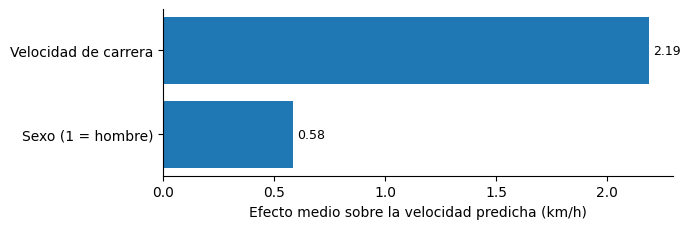

In [29]:
# Importancia de cada variable con valores SHAP
NOMBRE_VAR = {'running_speed_kmh': 'Velocidad de carrera', 'pace_cycling_kmh': 'Velocidad en ciclismo',
              'sexo_M': 'Sexo (1 = hombre)'}
shap_values = shap.TreeExplainer(model_xgb).shap_values(X)
imp_shap = pd.Series(np.abs(shap_values).mean(axis=0),
                     index=[NOMBRE_VAR[f] for f in FEATURE_COLS]).sort_values()
print("Efecto medio de cada variable sobre la predicción (media de |SHAP|, km/h):")
print(imp_shap.sort_values(ascending=False).round(2).to_string())

fig, ax = plt.subplots(figsize=(7, 2.4))
ax.barh(imp_shap.index, imp_shap.values, color='#1f77b4')
for i, v in enumerate(imp_shap.values):
    ax.text(v + 0.02, i, f'{v:.2f}', va='center', fontsize=9)
ax.set_xlabel('Efecto medio sobre la velocidad predicha (km/h)')
ax.spines[['top', 'right']].set_visible(False)
plt.tight_layout(); plt.savefig('salidas/figuras/shap_modelo_directo.png', dpi=200); plt.show()

In [30]:
# Predicción de la velocidad en ciclismo de cada deportista.
# Entrada: su velocidad sostenida de carrera, con sesiones válidas. La predicción se comunica con un
# margen conservador (x 0,85) porque el modelo aprende de velocidades de competición.
HISTORIAL_EVAL = 25   # sesiones válidas de ciclismo necesarias para comparar con la velocidad real

filas = []
for letra, d in garmin_data.items():
    acts = d.get('activities', pd.DataFrame())
    run = sesiones_validas(acts[acts['sport'] == 'RUNNING'], 'RUNNING')
    cyc_todas = acts[acts['sport'] == 'CYCLING']
    cyc = sesiones_validas(cyc_todas, 'CYCLING')
    if run.empty:
        continue
    x = {'running_speed_kmh': ritmo_sostenido(run),
         'sexo_M': 1.0 if sexo_por_atleta.get(letra, 'M') == 'M' else 0.0}
    pred = float(model_xgb.predict(np.array([[x[f] for f in FEATURE_COLS]]))[0])
    filas.append({'athlete': letra, 'sesiones_bici': len(cyc_todas), 'sesiones_bici_validas': len(cyc),
                  'carrera_p80': x['running_speed_kmh'], 'bici_real_p80': ritmo_sostenido(cyc),
                  'pred_kmh': pred, 'pred_conservador_kmh': pred * 0.85})
pred_cyc = pd.DataFrame(filas).set_index('athlete')
pred_cyc['dif_sin_margen'] = pred_cyc['pred_kmh'] - pred_cyc['bici_real_p80']
pred_cyc['dif_con_margen'] = pred_cyc['pred_conservador_kmh'] - pred_cyc['bici_real_p80']
evaluables = pred_cyc[pred_cyc['sesiones_bici_validas'] >= HISTORIAL_EVAL]
print(pred_cyc.round(1).to_string())
print(f"\nDeportistas con al menos {HISTORIAL_EVAL} sesiones válidas de ciclismo: {', '.join(evaluables.index)}")
print(f"  Sin margen, la predicción supera la velocidad real entre "
      f"{evaluables['dif_sin_margen'].min():.1f} y {evaluables['dif_sin_margen'].max():.1f} km/h")
print(f"  Con margen, error medio absoluto: {evaluables['dif_con_margen'].abs().mean():.1f} km/h")
razon = evaluables['bici_real_p80'] / evaluables['pred_kmh']
print(f"  Razón real / predicha: media {razon.mean():.2f} (de {razon.min():.2f} a {razon.max():.2f})")

         sesiones_bici  sesiones_bici_validas  carrera_p80  bici_real_p80  pred_kmh  pred_conservador_kmh  dif_sin_margen  dif_con_margen
athlete                                                                                                                                  
A                   15                      0         9.00            NaN     27.40                 23.30             NaN             NaN
B                  267                    236        11.30          28.60     32.00                 27.20            3.40           -1.40
C                  919                    538        10.00          29.50     30.20                 25.70            0.70           -3.80
D                  405                    368        12.20          23.30     33.10                 28.10            9.70            4.80

Deportistas con al menos 25 sesiones válidas de ciclismo: B, C, D
  Sin margen, la predicción supera la velocidad real entre 0.7 y 9.7 km/h
  Con margen, error medio absol

In [31]:
# Modelo inverso: ciclismo y sexo para estimar la carrera
cv_r2_r, cv_mae_r, cv_r2_tr_r = validar(FEAT_CYC2RUN, 'running_speed_kmh', df_inv, PARAMS_INV)
print("Modelo inverso, validación cruzada de cinco particiones:")
print(f"  R²  = {cv_r2_r.mean():.3f} ± {cv_r2_r.std():.3f} (entrenamiento {cv_r2_tr_r.mean():.3f})")
print(f"  MAE = {cv_mae_r.mean():.2f} ± {cv_mae_r.std():.2f} km/h")
model_xgb_run = xgb.XGBRegressor(**PARAMS_INV).fit(df_inv[FEAT_CYC2RUN].values,
                                                   df_inv['running_speed_kmh'].values)

def apply_brick_factor(pace_kmh):
    """Tiempo de los 21,1 km con el factor de transición: 5 km al 90 %,
    10 km a la velocidad prevista y 6,1 km al 95 %."""
    v1, v2, v3 = pace_kmh * 0.90, pace_kmh, pace_kmh * 0.95
    return round((5 / v1 + 10 / v2 + 6.1 / v3) * 60, 1)

# Predicción para cada deportista con historial de ciclismo. La entrada es su velocidad sostenida en
# sesiones válidas; con menos de tres se usan todas sus salidas (caso de A). Se comunica con un margen
# conservador de 0,5 km/h menos. El tiempo previsto se calcula en la sección 6g.
filas = []
for letra, d in garmin_data.items():
    acts = d.get('activities', pd.DataFrame())
    cyc_todas = acts[acts['sport'] == 'CYCLING'].dropna(subset=['avg_speed_kmh'])
    cyc = sesiones_validas(cyc_todas, 'CYCLING')
    run = sesiones_validas(acts[acts['sport'] == 'RUNNING'], 'RUNNING')
    if len(cyc_todas) < 2:
        continue
    x = {'pace_cycling_kmh': ritmo_sostenido(cyc if len(cyc) >= 3 else cyc_todas),
         'sexo_M': 1.0 if sexo_por_atleta.get(letra, 'M') == 'M' else 0.0}
    pred = float(model_xgb_run.predict(np.array([[x[f] for f in FEAT_CYC2RUN]]))[0])
    pace = max(pred - 0.5, 5.0)
    filas.append({'athlete': letra, 'bici_p80': x['pace_cycling_kmh'], 'sesiones_carrera_validas': len(run),
                  'carrera_real_p80': ritmo_sostenido(run), 'pred_kmh': pred, 'pace_kmh': pace})
pred_run = pd.DataFrame(filas).set_index('athlete')
pred_run['comunicada_menos_real'] = pred_run['pace_kmh'] - pred_run['carrera_real_p80']
print()
print(pred_run.round(1).to_string())

Modelo inverso, validación cruzada de cinco particiones:
  R²  = 0.458 ± 0.005 (entrenamiento 0.460)
  MAE = 1.25 ± 0.01 km/h

         bici_p80  sesiones_carrera_validas  carrera_real_p80  pred_kmh  pace_kmh  comunicada_menos_real
athlete                                                                                                 
A           10.30                       131              9.00      7.60      7.10                  -1.90
B           28.60                       758             11.30      9.50      9.00                  -2.30
C           29.50                       250             10.00      9.80      9.30                  -0.80
D           23.30                       170             12.20      8.20      7.70                  -4.50


### 6e. Comprobación: ¿cuánto aportaría la natación?

Los modelos no usan la velocidad de natación: es el segmento que menos se relaciona con el tiempo final y
quien llega al triatlón desde la carrera o el ciclismo puede no tener ese dato. Aquí se mide lo que se pierde
al dejarla fuera: se repite la validación añadiéndola, con las mismas filas, los mismos hiperparámetros y las
mismas particiones; solo cambia la lista de variables.

In [32]:
comparacion = []
for nombre, datos, objetivo, base, r2_sin, mae_sin, params in [
        ('Directo (carrera → ciclismo)', df_dir, 'pace_cycling_kmh', FEATURE_COLS, cv_r2, cv_mae, PARAMS_DIR),
        ('Inverso (ciclismo → carrera)', df_inv, 'running_speed_kmh', FEAT_CYC2RUN, cv_r2_r, cv_mae_r, PARAMS_INV)]:
    r2_con, mae_con, _ = validar(base + ['swim_speed_kmh'], objetivo, datos, params)
    comparacion.append({'Modelo': nombre,
                        'R² sin natación': f'{r2_sin.mean():.3f} ± {r2_sin.std():.3f}',
                        'R² con natación': f'{r2_con.mean():.3f} ± {r2_con.std():.3f}',
                        'Diferencia de R²': round(r2_con.mean() - r2_sin.mean(), 3),
                        'MAE sin natación (km/h)': f'{mae_sin.mean():.2f}',
                        'MAE con natación (km/h)': f'{mae_con.mean():.2f}'})
comparacion = pd.DataFrame(comparacion).set_index('Modelo')
comparacion

,R² sin natación,R² con natación,Diferencia de R²,MAE sin natación (km/h),MAE con natación (km/h)
Modelo,,,,,
Directo (carrera → ciclismo),0.469 ± 0.008,0.509 ± 0.007,0.04,2.37,2.28
Inverso (ciclismo → carrera),0.458 ± 0.005,0.501 ± 0.005,0.04,1.25,1.20


**Hallazgo.** Añadir la natación sube el R² unas cuatro centésimas en los dos modelos (de 0,469 a 0,509 en el
directo y de 0,458 a 0,501 en el inverso), pero el error medio apenas cambia: de 2,37 a 2,28 km/h en ciclismo y
de 1,25 a 1,20 km/h en carrera, menos de un minuto sobre cada segmento. La mejora no compensa exigir un dato
que muchos deportistas no tienen.

### 6f. ¿Bastan 80.000 registros? Curva de aprendizaje

Si el error deja de bajar mucho antes de los 80.000 registros, la muestra es suficiente y usar el millón y medio
de resultados solo alargaría los cálculos.

Directo 640: 2.449, 1,920: 2.402, 3,840: 2.387, 8,000: 2.381, 16,000: 2.378, 32,000: 2.375, 64,000: 2.375
Inverso 640: 1.274, 1,920: 1.262, 3,840: 1.257, 8,000: 1.254, 16,000: 1.252, 32,000: 1.251, 64,000: 1.250


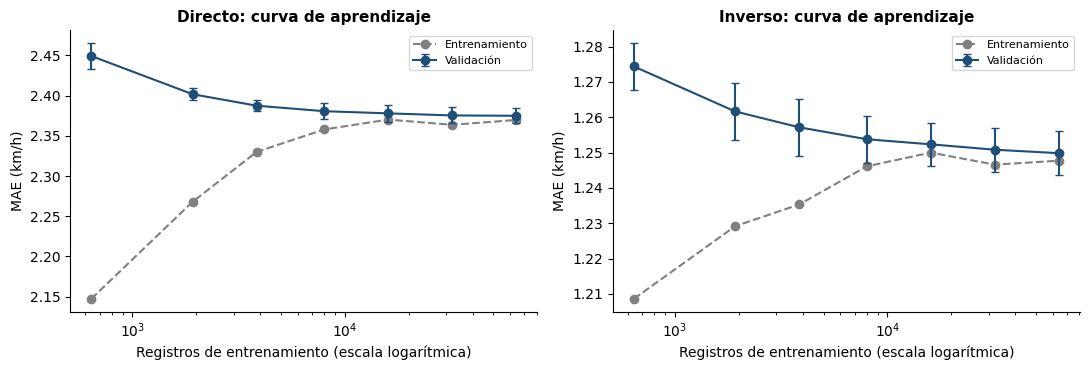

In [33]:
from sklearn.model_selection import learning_curve
fig, axes = plt.subplots(1, 2, figsize=(11, 3.8), sharey=False)
for ax, (titulo, datos, X, y, params) in zip(axes, [
        ('Directo', df_dir, FEATURE_COLS, 'pace_cycling_kmh', PARAMS_DIR),
        ('Inverso', df_inv, FEAT_CYC2RUN, 'running_speed_kmh', PARAMS_INV)]):
    tam, tr, va = learning_curve(xgb.XGBRegressor(**params), datos[X].values, datos[y].values, cv=kf,
                                 train_sizes=[0.01, 0.03, 0.06, 0.125, 0.25, 0.5, 1.0],
                                 scoring='neg_mean_absolute_error', shuffle=True, random_state=42)
    ax.plot(tam, -tr.mean(1), 'o--', color='grey', label='Entrenamiento')
    ax.errorbar(tam, -va.mean(1), yerr=va.std(1), fmt='o-', color='#1f4e79', capsize=3, label='Validación')
    ax.set_xscale('log'); ax.set_title(f'{titulo}: curva de aprendizaje')
    ax.set_xlabel('Registros de entrenamiento (escala logarítmica)'); ax.set_ylabel('MAE (km/h)')
    ax.legend(fontsize=8); ax.spines[['top', 'right']].set_visible(False)
    print(titulo, ', '.join(f'{int(n):,}: {m:.3f}' for n, m in zip(tam, -va.mean(1))))
plt.tight_layout(); plt.savefig('salidas/figuras/curva_aprendizaje_ambos.png', dpi=200); plt.show()

**Hallazgo.** El error de validación baja deprisa al principio (2,449 km/h con 640 registros, 2,387 con 3.840) y
a partir de unos 16.000 registros prácticamente se estabiliza (2,378 con 16.000; 2,375 con 32.000 y con
64.000). Los 80.000 resultados de cada muestra bastan; usar el millón y medio solo alargaría los cálculos.

### 6g. Combinación del modelo con las sesiones propias

El modelo da una velocidad de partida a quien no tiene historial en una disciplina. En cuanto el deportista
registra sesiones válidas en ella, su propio historial es mejor información, y la estimación combina las dos
fuentes:

v = w · propia + (1 − w) · base, con w = n / (n + k0)

donde *propia* es su velocidad sostenida en sesiones válidas, *n* el número de esas sesiones (máximo 25) y
*base* la predicción del modelo llevada a condiciones de entrenamiento. Con pocas sesiones manda el modelo y
con muchas, el historial. Con menos de tres sesiones válidas se usa solo el modelo con su margen conservador.

El valor de k0 y el factor que lleva la predicción a condiciones de entrenamiento se calibran con
GoldenCheetah, que reúne a miles de deportistas con historial de bici y de carrera. Se toma a cada deportista
con al menos 50 sesiones válidas en la disciplina que se estima y 10 en la otra, se simula que solo conoce sus
primeras k sesiones (k = 3, 6, 10, 15 y 25) y se mide el error al predecir el percentil 80 de las 25
siguientes. La validación es por deportistas: los de prueba no intervienen en la elección de k0 ni del factor.

In [34]:
# Calibración con GoldenCheetah: sesiones válidas y validación por deportistas
from sklearn.model_selection import GroupKFold
K_LIST = [3, 6, 10, 15, 25]
K0_CANDIDATOS = [1, 2, 5, 10, 20, 40, 80]


def preparar_gc(df):
    cols = ['id', 'date', 'gender', 'sport', 'workout_time', 'total_distance']
    act = df[cols]
    act = act[act['sport'].isin(['Bike', 'Run'])].dropna(subset=['date', 'workout_time', 'total_distance']).copy()
    act['date'] = pd.to_datetime(act['date'], errors='coerce')
    act = act.dropna(subset=['date'])
    act['horas'] = act['workout_time'] / 3600                 # workout_time en segundos
    act['vel'] = act['total_distance'] / act['horas']         # total_distance en km
    bici = (act.sport == 'Bike') & act.vel.between(12, 50) & (act.total_distance >= 10) & (act.horas >= 0.5)
    carr = (act.sport == 'Run') & act.vel.between(5, 20) & (act.total_distance >= 3) & (act.horas >= 0.25)
    return act[bici | carr].sort_values(['id', 'date'])


def calibrar(act, dep_obj, dep_ent, modelo, aditivo, margen):
    """Una fila por deportista: entrada del modelo, objetivo (p80 de las sesiones 26 a 50) y p80 de sus
    primeras k sesiones. Devuelve el número de deportistas y el error medio entre particiones."""
    filas = []
    for aid, g in act.groupby('id'):
        o = g[g.sport == dep_obj].reset_index(drop=True)
        e = g[g.sport == dep_ent]
        if len(o) < 50 or g['gender'].iloc[0] not in ('M', 'F'):
            continue
        e_prev = e[e.date < o.loc[24, 'date']].tail(25)       # la entrada se fija antes de la sesión 25
        if len(e_prev) < 10:
            continue
        fila = dict(id=aid, sexo_M=float(g['gender'].iloc[0] == 'M'), entrada=e_prev.vel.quantile(0.8),
                    objetivo=o.loc[25:49, 'vel'].quantile(0.8))
        for k in K_LIST:
            fila[f'own_{k}'] = o.loc[:k - 1, 'vel'].quantile(0.8)
        filas.append(fila)
    D = pd.DataFrame(filas)
    D['modelo'] = modelo.predict(D[['entrada', 'sexo_M']].values)
    base = (lambda df, c: df.modelo + c) if aditivo else (lambda df, c: c * df.modelo)
    mae = lambda a, b: float(np.mean(np.abs(a - b)))
    res = []
    for tr, te in GroupKFold(n_splits=5).split(D, groups=D['id']):
        A, B = D.iloc[tr], D.iloc[te]
        c = float((A.objetivo - A.modelo).median()) if aditivo else float((A.objetivo / A.modelo).median())

        def mae_medio(k0):
            return np.mean([mae(k / (k + k0) * A[f'own_{k}'] + k0 / (k + k0) * base(A, c), A.objetivo)
                            for k in K_LIST])

        k0 = min(K0_CANDIDATOS, key=mae_medio)
        fila = {'k0': k0, 'factor': c, 'solo modelo con margen': mae(margen(B.modelo), B.objetivo),
                'modelo recalibrado': mae(base(B, c), B.objetivo)}
        for k in K_LIST:
            w = k / (k + k0)
            fila[f'combinado, {k} sesiones'] = mae(w * B[f'own_{k}'] + (1 - w) * base(B, c), B.objetivo)
            fila[f'solo propio, {k} sesiones'] = mae(B[f'own_{k}'], B.objetivo)
        res.append(fila)
    R = pd.DataFrame(res)
    return len(D), pd.DataFrame({'media': R.mean(), 'desv': R.std()})


GC_COLS = {'id', 'date', 'gender', 'sport', 'workout_time', 'total_distance'}
if df_gc.empty or not GC_COLS <= set(df_gc.columns):
    print('GoldenCheetah no disponible: se usan los valores de la calibración original.')
    K0, FACTOR = {'CYCLING': 10, 'RUNNING': 2}, {'CYCLING': 0.86, 'RUNNING': 2.12}
else:
    act_gc = preparar_gc(df_gc)
    n_b, cal_b = calibrar(act_gc, 'Bike', 'Run', model_xgb, False, lambda m: 0.85 * m)
    n_r, cal_r = calibrar(act_gc, 'Run', 'Bike', model_xgb_run, True, lambda m: m - 0.5)
    print(f'Ciclismo a partir de la carrera ({n_b} deportistas), error en km/h:')
    print(cal_b.round(2).to_string())
    print(f'\nCarrera a partir del ciclismo ({n_r} deportistas), error en km/h:')
    print(cal_r.round(2).to_string())
    K0 = {'CYCLING': int(round(cal_b.loc['k0', 'media'])), 'RUNNING': int(round(cal_r.loc['k0', 'media']))}
    FACTOR = {'CYCLING': round(cal_b.loc['factor', 'media'], 2), 'RUNNING': round(cal_r.loc['factor', 'media'], 2)}
print('\nk0:', K0, '| factor a condiciones de entrenamiento:', FACTOR)

Ciclismo a partir de la carrera (480 deportistas), error en km/h:
                          media  desv
k0                        10.00  0.00
factor                     0.86  0.00
solo modelo con margen     3.11  0.24
modelo recalibrado         3.11  0.24
combinado, 3 sesiones      2.82  0.22
solo propio, 3 sesiones    3.98  0.24
combinado, 6 sesiones      2.73  0.20
solo propio, 6 sesiones    3.45  0.15
combinado, 10 sesiones     2.58  0.16
solo propio, 10 sesiones   3.01  0.17
combinado, 15 sesiones     2.42  0.13
solo propio, 15 sesiones   2.69  0.14
combinado, 25 sesiones     2.16  0.13
solo propio, 25 sesiones   2.26  0.16

Carrera a partir del ciclismo (530 deportistas), error en km/h:
                          media  desv
k0                         2.00  0.00
factor                     2.13  0.03
solo modelo con margen     2.67  0.14
modelo recalibrado         1.24  0.09
combinado, 3 sesiones      0.91  0.05
solo propio, 3 sesiones    1.08  0.09
combinado, 6 sesiones      0.81  

         bici_combinada  peso_bici  carrera_combinada  peso_carrera  tiempo_90km_min  tiempo_21km_min
athlete                                                                                              
A                 23.30       0.00               9.04          0.93           231.78           145.90
B                 28.32       0.71              11.33          0.93           190.69           116.30
C                 28.45       0.71              10.17          0.93           189.79           129.70
D                 24.79       0.71              12.07          0.93           217.85           109.20


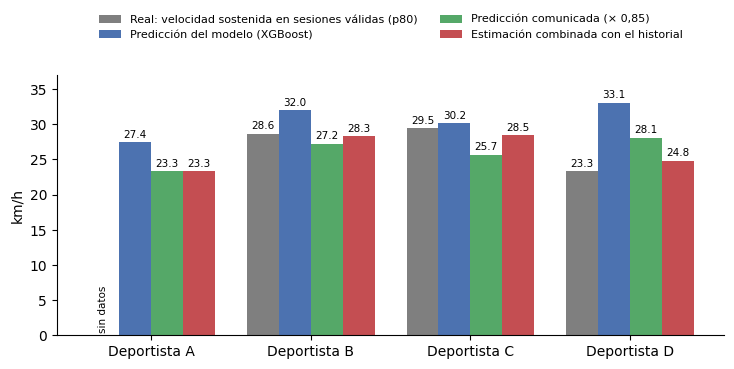

In [35]:
# Estimación combinada de los cuatro deportistas: es la que reciben el plan y el tiempo previsto
MIN_SESIONES = 3


def combinar(base, propia, n, k0):
    if n < MIN_SESIONES or pd.isna(propia):
        return np.nan, 0.0
    w = n / (n + k0)
    return w * propia + (1 - w) * base, w


filas = []
for letra in sorted(set(pred_cyc.index) | set(pred_run.index)):
    fila = {'athlete': letra}
    if letra in pred_cyc.index:
        r = pred_cyc.loc[letra]
        v, w = combinar(FACTOR['CYCLING'] * r['pred_kmh'], r['bici_real_p80'],
                        int(min(r['sesiones_bici_validas'], 25)), K0['CYCLING'])
        fila.update(bici_combinada=r['pred_conservador_kmh'] if pd.isna(v) else v, peso_bici=w)
    if letra in pred_run.index:
        r = pred_run.loc[letra]
        v, w = combinar(r['pred_kmh'] + FACTOR['RUNNING'], r['carrera_real_p80'],
                        int(min(r['sesiones_carrera_validas'], 25)), K0['RUNNING'])
        fila.update(carrera_combinada=r['pace_kmh'] if pd.isna(v) else v, peso_carrera=w)
    filas.append(fila)
comb = pd.DataFrame(filas).set_index('athlete')

# Tiempo previsto. El factor de transición se aplica a velocidades de entrenamiento (estimación combinada);
# si solo hay modelo, su predicción ya procede de carreras corridas tras el ciclismo y no se aplica otra vez.
comb['tiempo_90km_min'] = 90 / comb['bici_combinada'] * 60
comb['tiempo_21km_min'] = [apply_brick_factor(v) if w > 0 else round(21.1 / v * 60, 1)
                           for v, w in zip(comb['carrera_combinada'], comb['peso_carrera'])]
print(comb.round(2).to_string())

# Listas que usan el motor de planificación (sección 7) y el almacenamiento (sección 9)
predicciones_cyc = [{'athlete': l, 'pred_kmh': round(pred_cyc.loc[l, 'pred_kmh'], 1),
                     'pred_conservador_kmh': round(pred_cyc.loc[l, 'pred_conservador_kmh'], 1),
                     'v_plan_kmh': round(comb.loc[l, 'bici_combinada'], 1),
                     'tiempo_90km_min': round(comb.loc[l, 'tiempo_90km_min'], 1)} for l in pred_cyc.index]
predicciones_run = [{'athlete': l, 'pace_kmh': round(pred_run.loc[l, 'pace_kmh'], 1),
                     'v_plan_kmh': round(comb.loc[l, 'carrera_combinada'], 1),
                     'tiempo_21km_min': comb.loc[l, 'tiempo_21km_min']} for l in pred_run.index]

# Velocidad real, predicha, comunicada y combinada en ciclismo
fig, ax = plt.subplots(figsize=(7.5, 3.9))
xs = np.arange(len(pred_cyc))
w = 0.2
series = [(pred_cyc['bici_real_p80'], '#7f7f7f', 'Real: velocidad sostenida en sesiones válidas (p80)'),
          (pred_cyc['pred_kmh'], '#4C72B0', 'Predicción del modelo (XGBoost)'),
          (pred_cyc['pred_conservador_kmh'], '#55A868', 'Predicción comunicada (× 0,85)'),
          (comb.loc[pred_cyc.index, 'bici_combinada'], '#C44E52', 'Estimación combinada con el historial')]
for k, (vals, col, lab) in enumerate(series):
    barras = ax.bar(xs + (k - 1.5) * w, vals.fillna(0).values, w, color=col, label=lab)
    for b, val in zip(barras, vals.values):
        txt = 'sin datos' if pd.isna(val) else f'{val:.1f}'
        ax.text(b.get_x() + b.get_width() / 2, (0 if pd.isna(val) else val) + 0.4, txt, ha='center',
                fontsize=7.5, rotation=90 if pd.isna(val) else 0, va='bottom')
ax.set_xticks(xs)
ax.set_xticklabels([f'Deportista {l}' for l in pred_cyc.index])
ax.set_ylabel('km/h')
ax.set_ylim(0, max(36, pred_cyc['pred_kmh'].max() + 4))
ax.legend(fontsize=8, frameon=False, loc='upper center', bbox_to_anchor=(0.5, 1.27), ncol=2)
ax.spines[['top', 'right']].set_visible(False)
plt.tight_layout()
plt.savefig('salidas/figuras/ciclismo_real_vs_predicho.png', dpi=200)
plt.show()

In [36]:
# Comprobación con los propios deportistas: se repite el ensayo de GoldenCheetah con su historial.
# De sus últimas 50 sesiones válidas, las k primeras se usan para estimar el p80 de las 25 últimas.
def retrospectiva(deporte, otro, modelo, base, margen, k0):
    filas = []
    for letra, d in garmin_data.items():
        acts = d.get('activities', pd.DataFrame())
        o = sesiones_validas(acts[acts['sport'] == deporte], deporte).tail(50).reset_index(drop=True)
        if len(o) < 50:
            continue
        e = sesiones_validas(acts[acts['sport'] == otro], otro)
        e = e[e['date'] < o.loc[24, 'date']].tail(25)
        if len(e) < 10:
            continue
        sexo = 1.0 if sexo_por_atleta.get(letra, 'M') == 'M' else 0.0
        pred = float(modelo.predict(np.array([[e['avg_speed_kmh'].quantile(0.8), sexo]]))[0])
        obj = o.loc[25:49, 'avg_speed_kmh'].quantile(0.8)
        fila = {'deportista': letra, 'real (p80)': obj, 'solo modelo': margen(pred) - obj}
        for k in (3, 6, 10, 25):
            wk = k / (k + k0)
            fila[f'{k} sesiones'] = wk * o.loc[:k - 1, 'avg_speed_kmh'].quantile(0.8) + (1 - wk) * base(pred) - obj
        filas.append(fila)
    t = pd.DataFrame(filas).set_index('deportista')
    return t, t.drop(columns='real (p80)').abs().mean()


t_b, e_b = retrospectiva('CYCLING', 'RUNNING', model_xgb, lambda p: FACTOR['CYCLING'] * p,
                         lambda p: 0.85 * p, K0['CYCLING'])
t_r, e_r = retrospectiva('RUNNING', 'CYCLING', model_xgb_run, lambda p: p + FACTOR['RUNNING'],
                         lambda p: max(p - 0.5, 5.0), K0['RUNNING'])
print('Ciclismo: diferencia con la velocidad real (km/h)')
print(t_b.round(1).to_string())
print('Error medio:', e_b.round(1).to_dict())
print('\nCarrera: diferencia con la velocidad real (km/h)')
print(t_r.round(1).to_string())
print('Error medio:', e_r.round(1).to_dict())

Ciclismo: diferencia con la velocidad real (km/h)
            real (p80)  solo modelo  3 sesiones  6 sesiones  10 sesiones  25 sesiones
deportista                                                                           
B                28.60        -0.80        0.10       -0.10         0.10         0.20
C                29.50        -3.70       -2.30       -1.60        -1.00        -0.30
D                23.30         4.80        2.80        4.00         3.70         3.10
Error medio: {'solo modelo': 3.1, '3 sesiones': 1.7, '6 sesiones': 1.9, '10 sesiones': 1.6, '25 sesiones': 1.2}

Carrera: diferencia con la velocidad real (km/h)
            real (p80)  solo modelo  3 sesiones  6 sesiones  10 sesiones  25 sesiones
deportista                                                                           
B                11.30        -2.30        0.10        0.10         0.10         0.10
C                10.00        -0.60        0.90        0.60         0.40         0.10
D             

**Hallazgo.** En GoldenCheetah la combinación es mejor que cada fuente por separado con cualquier número de
sesiones. En ciclismo (480 deportistas, k0 = 10) el error pasa de 3,11 km/h con el modelo y su margen a 2,73
con seis sesiones propias y 2,16 con 25; usar solo las sesiones propias da 3,45 y 2,26. En carrera (530
deportistas, k0 = 2) pasa de 2,67 km/h a 0,81 con seis sesiones y 0,53 con 25. La razón mediana entre la
velocidad de entrenamiento y la predicha en ciclismo es 0,86, casi el margen de 0,85 que se fijó a priori; en
carrera la velocidad de entrenamiento supera a la predicha en 2,13 km/h, porque el modelo inverso aprende de
carreras corridas tras 90 km de bici.

Con los propios deportistas (B, C y D, los que tienen 50 sesiones válidas en las dos disciplinas) el error
medio en ciclismo baja de 3,1 km/h con el modelo a 1,9 con seis sesiones y 1,2 con 25, y en carrera de 2,1 a
0,3 y 0,2. A no tiene ninguna salida de bici válida (son desplazamientos cortos y lentos), así que su
estimación sigue siendo la del modelo con margen, 23,3 km/h.

### 6h. Resumen de la fase 1

Reúne las cifras de la validación, la importancia de las variables, la comprobación de la natación, las
predicciones para cada deportista y la estimación combinada que usan el plan y la aplicación.

In [37]:
def minutos(dist, v):
    return dist / v * 60

v_bici, v_run = df_dir['pace_cycling_kmh'].mean(), df_inv['running_speed_kmh'].mean()
mae_b, mae_r = cv_mae.mean(), cv_mae_r.mean()
print("Validación cruzada de los modelos finales")
print(f"  Directo: R² {cv_r2.mean():.3f} ± {cv_r2.std():.3f} | MAE {mae_b:.2f} ± {cv_mae.std():.2f} km/h | "
      f"≈ {minutos(90, v_bici - mae_b) - minutos(90, v_bici):.0f} min en 90 km")
print(f"  Inverso: R² {cv_r2_r.mean():.3f} ± {cv_r2_r.std():.3f} | MAE {mae_r:.2f} ± {cv_mae_r.std():.2f} km/h | "
      f"{minutos(21.1, v_run) - minutos(21.1, v_run + mae_r):.0f}-"
      f"{minutos(21.1, v_run - mae_r) - minutos(21.1, v_run):.0f} min en 21,1 km")
print(f"  MAE en % de la velocidad media: ciclismo {mae_b / v_bici * 100:.1f} % (media {v_bici:.1f} km/h), "
      f"carrera {mae_r / v_run * 100:.1f} % (media {v_run:.1f} km/h)")
print("\nSHAP:", ', '.join(f'{k} {v:.2f} km/h' for k, v in imp_shap.sort_values(ascending=False).items()))
print("\nHiperparámetros de los modelos finales")
print("  Directo:", {k: v for k, v in PARAMS_DIR.items() if k not in ('missing', 'n_jobs', 'random_state')})
print("  Inverso:", {k: v for k, v in PARAMS_INV.items() if k not in ('missing', 'n_jobs', 'random_state')})
print("\nComprobación de la natación")
print(comparacion[['R² sin natación', 'R² con natación', 'Diferencia de R²']].to_string())
print("\nPredicciones frente a la velocidad real")
tabla_predicciones = pd.DataFrame({
    'Ciclismo real (p80)': pred_cyc['bici_real_p80'].round(1),
    'Ciclismo predicho / comunicado': pred_cyc['pred_kmh'].round(1).astype(str) + ' / ' + pred_cyc['pred_conservador_kmh'].round(1).astype(str),
    'Ciclismo combinado': comb['bici_combinada'].round(1),
    'Carrera real (p80)': pred_run['carrera_real_p80'].round(1),
    'Carrera comunicada': pred_run['pace_kmh'].round(1),
    'Carrera combinada': comb['carrera_combinada'].round(1),
    'Tiempo previsto 90 km': comb['tiempo_90km_min'].apply(lambda m: f'{int(m // 60)} h {int(round(m % 60)):02d} min'),
    'Tiempo previsto 21,1 km': comb['tiempo_21km_min'].apply(lambda m: f'{int(m // 60)} h {int(round(m % 60)):02d} min')})
print(tabla_predicciones.to_string())
print(f"\nCiclismo, deportistas con historial ({', '.join(evaluables.index)}): sin margen +{evaluables['dif_sin_margen'].min():.1f} a "
      f"+{evaluables['dif_sin_margen'].max():.1f} km/h; con margen "
      + ', '.join(f"{l} {v:+.1f}" for l, v in evaluables['dif_con_margen'].items())
      + f" km/h; error medio {evaluables['dif_con_margen'].abs().mean():.1f} km/h")
print(f"Carrera: la velocidad comunicada queda entre {pred_run['comunicada_menos_real'].min():+.1f} y "
      f"{pred_run['comunicada_menos_real'].max():+.1f} km/h respecto a la real")

Validación cruzada de los modelos finales
  Directo: R² 0.469 ± 0.008 | MAE 2.37 ± 0.01 km/h | ≈ 15 min en 90 km
  Inverso: R² 0.458 ± 0.005 | MAE 1.25 ± 0.01 km/h | 13-17 min en 21,1 km
  MAE en % de la velocidad media: ciclismo 7.8 % (media 30.3 km/h), carrera 12.2 % (media 10.3 km/h)

SHAP: Velocidad de carrera 2.19 km/h, Sexo (1 = hombre) 0.58 km/h

Hiperparámetros de los modelos finales
  Directo: {'n_estimators': 1050, 'max_depth': 3, 'learning_rate': 0.0074, 'subsample': 0.7312610669898928, 'colsample_bytree': 1.0, 'gamma': 0.8866171489506599, 'min_child_weight': 2, 'reg_lambda': 2.2082704989025084}
  Inverso: {'n_estimators': 500, 'max_depth': 2, 'learning_rate': 0.0208, 'subsample': 0.6550083776583973, 'colsample_bytree': 1.0, 'gamma': 0.3486659872917294, 'min_child_weight': 33, 'reg_lambda': 7.472397689332939}

Comprobación de la natación
                             R² sin natación R² con natación  Diferencia de R²
Modelo                                                      

**Prueba: ¿mejora el modelo si se añaden grupos de perfil?** Como última comprobación del agrupamiento de la
sección 5, se repite con los resultados de los finishers de 70.3. Se agrupa a los deportistas con K-means usando
solo las entradas que conoce la aplicación (velocidad de carrera, sexo y natación), sin la velocidad de bici, y
se añade el grupo como variable al modelo directo. Los grupos se ajustan dentro de cada partición de
entrenamiento para no filtrar información de validación.

In [38]:
import numpy as np
from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import silhouette_score
from xgboost import XGBRegressor

datos = df_dir.dropna(subset=['running_speed_kmh', 'sexo_M', 'swim_speed_kmh', 'pace_cycling_kmh']).copy()
print("filas usadas:", len(datos), "| eliminadas:", len(df_dir) - len(datos))
BASE = ['running_speed_kmh', 'sexo_M']
ENTRADAS_GRUPO = ['running_speed_kmh', 'sexo_M', 'swim_speed_kmh']
OBJ = 'pace_cycling_kmh'
K = 4

res_base, res_cl, sil = [], [], []
for i, (tr, va) in enumerate(kf.split(datos)):
    d_tr, d_va = datos.iloc[tr], datos.iloc[va]
    sc = StandardScaler().fit(d_tr[ENTRADAS_GRUPO])
    Z_tr = sc.transform(d_tr[ENTRADAS_GRUPO])
    Z_va = sc.transform(d_va[ENTRADAS_GRUPO])
    km = KMeans(n_clusters=K, random_state=42, n_init=10).fit(Z_tr)
    g_tr, g_va = km.predict(Z_tr), km.predict(Z_va)
    if i == 0:
        idx = np.random.RandomState(0).choice(len(Z_tr), 5000, replace=False)
        sil.append(silhouette_score(Z_tr[idx], g_tr[idx]))
    X_tr = np.column_stack([d_tr[BASE].values, np.eye(K)[g_tr][:, 1:]])
    X_va = np.column_stack([d_va[BASE].values, np.eye(K)[g_va][:, 1:]])
    m0 = XGBRegressor(**PARAMS_DIR).fit(d_tr[BASE], d_tr[OBJ])
    m1 = XGBRegressor(**PARAMS_DIR).fit(X_tr, d_tr[OBJ])
    res_base.append(np.mean(np.abs(d_va[OBJ] - m0.predict(d_va[BASE]))))
    res_cl.append(np.mean(np.abs(d_va[OBJ] - m1.predict(X_va))))
    print(f"partición {i+1}: base {res_base[-1]:.3f} | con grupo {res_cl[-1]:.3f}")

base, cl = np.array(res_base), np.array(res_cl)
print("silueta (partición 1):", round(sil[0], 3))
print("MAE base:", base.mean().round(3), "±", base.std(ddof=1).round(3))
print("MAE con grupo:", cl.mean().round(3), "±", cl.std(ddof=1).round(3))
print("mejora media:", (base - cl).mean().round(3), "| regla (1 DE base):", base.std(ddof=1).round(3))

filas usadas: 77943 | eliminadas: 2057
partición 1: base 2.370 | con grupo 2.370
partición 2: base 2.369 | con grupo 2.369
partición 3: base 2.360 | con grupo 2.359
partición 4: base 2.360 | con grupo 2.360
partición 5: base 2.372 | con grupo 2.372
silueta (partición 1): 0.544
MAE base: 2.366 ± 0.006
MAE con grupo: 2.366 ± 0.006
mejora media: 0.0 | regla (1 DE base): 0.006


**Resultado.** Los grupos se separan bien (silueta de 0,54 con k = 4), pero no mejoran el error: 2,366 ± 0,006
km/h sin grupo y con grupo, con las mismas 77.943 filas (se quitan 2.057 sin tiempo de natación). Los grupos se
construyen sobre la velocidad de carrera, que el modelo ya recibe, y no aportan información nueva, así que el
agrupamiento no se incorpora.

**Hallazgos de la fase 1.**

- Con la velocidad de carrera y el sexo, el modelo directo explica casi la mitad de la variabilidad de la
  velocidad en ciclismo (R² = 0,469) con un error medio de 2,37 km/h, unos 15 minutos sobre los 90 km. El
  inverso alcanza un R² de 0,458 con un error de 1,25 km/h. La variación entre particiones es muy pequeña y el
  R² de entrenamiento casi igual al de validación (0,472 y 0,460): no hay sobreajuste.
- Siete algoritmos dan errores muy parecidos; XGBoost se elige por funcionar bien en las dos direcciones, dar
  predicciones graduales y ser rápido. La optimización mejora el error en milésimas.
- La velocidad de carrera es la variable que más pesa (efecto medio de 2,19 km/h frente a 0,58 km/h del sexo),
  coherente con la idea de que lo que se transfiere es la capacidad aeróbica.
- Con sesiones válidas, el modelo directo sin margen supera la velocidad real de entrenamiento de B, C y D
  entre 0,7 y 9,7 km/h, porque aprende de velocidades de competición. Con el margen de 0,85 el error medio es
  de 3,3 km/h. A no tiene salidas de bici válidas y recibe la predicción conservadora (23,3 km/h) como
  estimación de partida.
- El modelo inverso con su margen queda por debajo de la velocidad real de los cuatro deportistas, entre 0,8 y
  4,5 km/h: aprende de carreras corridas al final de un 70.3, con la fatiga acumulada.
- Combinar el modelo con las sesiones propias corrige los dos sesgos a medida que el deportista entrena: con
  seis sesiones, el error baja a 2,7 km/h en ciclismo y a 0,8 km/h en carrera en GoldenCheetah.
- Agrupar a los deportistas por perfil no mejora el modelo (2,366 km/h con y sin grupo).

## 7. Fase 2 — Motor de planificación semanal

El plan se decide en capas:

1. **Tipo de semana** con reglas en cascada sobre el TSB, el Body Battery y el estrés; la salud manda sobre la
   forma.
2. **Fase del macrociclo** a partir de la fecha de la prueba o de la duración mínima del plan según la
   experiencia (24 semanas para un deportista nuevo y 12 para uno experimentado).
3. **Zonas y ritmos** con el historial del deportista. El ritmo de rodaje se valida con carreras hechas en
   zona 2; si no las hay, se corrige con la FC de reserva, porque el ritmo medio de un corredor aficionado
   suele ser de zona 3 o 4.

En el cuaderno cada tipo de semana tiene sesiones fijas y las zonas se calculan con la FC de reserva. La
aplicación usa las mismas reglas, pero con el TSB medio de siete días (sección 7b), zonas por porcentaje de la
FC máxima y sesiones generadas con las fórmulas de progresión de la sección 7c.

In [39]:
# --- Utilidades de formato: de km/h a ritmos legibles ---
def _pace_run(v_kmh):
    # De km/h a 'm:ss min/km'
    if pd.isna(v_kmh) or v_kmh <= 0: return 'N/D'
    m = 60.0 / v_kmh
    s = int(round((m - int(m)) * 60))
    if s == 60: m, s = m + 1, 0
    return f"{int(m)}:{s:02d} min/km"

def _pace_swim(v_kmh):
    # De km/h a 'm:ss por 100 m'
    if pd.isna(v_kmh) or v_kmh <= 0: return 'N/D'
    s = 360.0 / v_kmh
    return f"{int(s // 60)}:{int(s % 60):02d}/100 m"

# --- Macrociclo: ¿cuándo es la competencia? ---
# En la aplicación este valor lo introduce el deportista con un
# st.date_input ("¿Cuándo es tu 70.3?") o, si aún no tiene dorsal, con un
# selector de meses de entrenamiento. Aquí se configura por diccionario.
FECHA_COMPETENCIA = {}            # ej.: {'A': '2026-09-20'}
SEMANAS_PLAN_DEFAULT = 16         # macrociclo tipo si no hay fecha
SEMANA_ACTUAL_DEFAULT = 6         # semana del plan en la que está el atleta
CTL_OBJETIVO_70_3 = 70            # forma (CTL) para terminar un 70.3 con solvencia
PERFIL_ATLETA = {'A': 'nuevo'}     # 'nuevo' o 'experimentado' (en la aplicación lo elige el deportista)
SEMANAS_MINIMAS = {'nuevo': 24, 'experimentado': 12}   # 6 meses / 3 meses de plan mínimo
OBJETIVOS_70_3 = {}   # deportista experimentado con marca previa. Ejemplo (tiempos ficticios):
# OBJETIVOS_70_3['B'] = {'anterior': {'nat': '0:42', 'bici': '2:58',
#                                     'run': '2:05', 'total': '5:55'},
#                        'objetivo_total': '5:35'}

def calcular_fase(name):
    """Semanas hasta la competencia, fase del macrociclo y viabilidad.
    El perfil marca la duración mínima del plan: un atleta nuevo necesita
    al menos 24 semanas (6 meses); con experiencia, 12 (3 meses)."""
    perfil = PERFIL_ATLETA.get(name, 'experimentado')
    sem_min = SEMANAS_MINIMAS[perfil]
    f = FECHA_COMPETENCIA.get(name)
    if f:
        sem_rest = max(int(np.ceil((pd.Timestamp(f) - pd.Timestamp.today()).days / 7)), 0)
        sem_tot = sem_rest + SEMANA_ACTUAL_DEFAULT
    else:
        sem_tot = sem_min
        sem_rest = sem_tot - SEMANA_ACTUAL_DEFAULT
    viable = sem_tot >= sem_min
    aviso = ('' if viable else
             f"para un atleta {perfil} se recomiendan al menos {sem_min} semanas de "
             f"preparación y este plan solo tiene {sem_tot}; considera una carrera más "
             f"lejana o ajusta el objetivo (terminar bien, no competir)")
    if sem_rest <= 1:    fase = 'COMPETENCIA'
    elif sem_rest <= 3:  fase = 'TAPERING'
    elif sem_rest <= 6:  fase = 'PICO'
    elif sem_rest <= 12: fase = 'CONSTRUCCION'
    else:                fase = 'BASE'
    return {'fase': fase, 'semanas_restantes': sem_rest, 'semanas_totales': sem_tot,
            'perfil': perfil, 'semanas_minimas': sem_min,
            'plan_viable': viable, 'aviso': aviso,
            'fecha_competencia': f if f else
            f'sin fecha (plan de {sem_min} semanas por perfil {perfil})'}

def _hm2min(txt):
    """Convierte 'h:mm' en minutos."""
    p = [int(v) for v in str(txt).split(':')]
    return p[0] * 60 + p[1]

def _min2t(m):
    h, mm = divmod(int(round(m)), 60)
    return f"{h}:{mm:02d}"

def analizar_objetivo(name, sem_prep=12):
    """Perfil experimentado orientado a marca: de los tiempos del último
    70.3 y del objetivo se derivan los splits y ritmos objetivo por
    disciplina. El reparto de la mejora pondera dónde hay más margen en un
    70.3: bici 50%, carrera 35%, natación 15%. Viabilidad: ~0.5% de mejora
    por semana de preparación disponible."""
    obj = OBJETIVOS_70_3.get(name)
    if not obj or PERFIL_ATLETA.get(name, 'experimentado') == 'nuevo':
        return None
    ant = {k: _hm2min(v) for k, v in obj['anterior'].items()}
    t_obj = _hm2min(obj['objetivo_total'])
    transiciones = max(ant['total'] - (ant['nat'] + ant['bici'] + ant['run']), 4)
    mejora = ant['total'] - t_obj
    if mejora <= 0:
        return None
    reparto = {'nat': 0.15, 'bici': 0.50, 'run': 0.35}
    splits = {k: ant[k] - mejora * w for k, w in reparto.items()}
    mejora_pct = mejora / ant['total'] * 100
    return {
        'anterior_total': _min2t(ant['total']), 'objetivo_total': obj['objetivo_total'],
        'mejora_min': round(mejora, 1), 'mejora_pct': round(mejora_pct, 1),
        'viable': mejora_pct <= max(sem_prep, 1) * 0.5,
        'transiciones_min': round(transiciones, 1),
        'splits_obj': {k: _min2t(v) for k, v in splits.items()},
        'v_nat_obj': 1.9 / (splits['nat'] / 60),
        'v_bici_obj': 90 / (splits['bici'] / 60),
        'v_run_obj': 21.1 / (splits['run'] / 60),
    }

def calcular_zonas(name):
    """Zonas personalizadas. FC por Karvonen con la FC máxima observada y
    la FC en reposo reales; ritmos a partir de los últimos 90 días y de la
    predicción XGBoost de ciclismo. Si falta un dato se usa un valor por
    defecto razonable para un triatleta novato."""
    p = df_profiles.loc[name] if name in df_profiles.index else pd.Series(dtype=float)
    acts = df_act[df_act['athlete'] == name]

    # FC máxima: percentil 98 de las máximas registradas (filtra lecturas erróneas)
    fc_max = np.nan
    if not acts.empty and 'max_hr' in acts.columns:
        fc_max = acts['max_hr'].dropna().quantile(0.98)
    if pd.isna(fc_max): fc_max = 185.0
    fc_rep = p.get('resting_hr', np.nan)
    if pd.isna(fc_rep): fc_rep = 55.0
    fcr = fc_max - fc_rep                              # reserva cardiaca

    def _hr(lo, hi): return (int(fc_rep + fcr * lo), int(fc_rep + fcr * hi))
    hr = {'Z1': _hr(.50, .60), 'Z2': _hr(.60, .70), 'Z3': _hr(.70, .80),
          'Z4': _hr(.80, .90), 'Z5': _hr(.90, 1.0)}

    # Ritmo de carrera: la media reciente se toma como referencia de Z3.
    # La media del historial no es el ritmo de rodaje: en un deportista nuevo
    # suele corresponder a Z3-Z4. Por eso el ritmo de Z2 se valida con el
    # historial: si hay al menos tres carreras hechas con FC de Z2, se usa su
    # ritmo real; si no, se corrige con la fracción de la FC de reserva que
    # usa de media (Karvonen inverso), porque rodar en Z2 es más lento.
    v_run = p.get('pace_running_kmh', np.nan)
    if pd.isna(v_run): v_run = 9.2                     # ~6:31 min/km
    v_run_z2, fuente_z2 = np.nan, 'estimado (sin historial suficiente)'
    if not acts.empty and {'sport', 'avg_hr', 'avg_speed_kmh'} <= set(acts.columns):
        runs = acts[acts['sport'] == 'RUNNING'].dropna(subset=['avg_hr', 'avg_speed_kmh'])
        en_z2 = runs[runs['avg_hr'].between(hr['Z2'][0], hr['Z2'][1])]
        if len(en_z2) >= 3:
            v_run_z2 = en_z2['avg_speed_kmh'].median()
            fuente_z2 = f'validado con {len(en_z2)} carreras reales en Z2 de tu historial'
        elif not runs.empty:
            f_obs = (runs['avg_hr'].mean() - fc_rep) / fcr
            if f_obs > 0:
                corr = float(np.clip(0.65 / f_obs, 0.72, 1.0))
                v_run_z2 = v_run * corr
                fuente_z2 = (f'corregido por FC: tu historial va al {f_obs*100:.0f}% de '
                             f'reserva cardiaca (Z3-Z4), no a ritmo de rodaje')
    if pd.isna(v_run_z2):
        v_run_z2 = v_run * 0.93
    perfil = PERFIL_ATLETA.get(name, 'experimentado')
    if perfil == 'nuevo':                               # margen de prudencia
        v_run_z2 *= 0.95
        fuente_z2 += ' · margen -5% por perfil nuevo'
    # Velocidad de bici sostenible: estimación de la fase 1 combinada con el historial (sección 6g)
    v_bici = next((pr.get('v_plan_kmh', pr['pred_conservador_kmh']) for pr in predicciones_cyc
                   if pr['athlete'] == name), np.nan)
    if pd.isna(v_bici): v_bici = p.get('pace_cycling_kmh', np.nan)
    if pd.isna(v_bici): v_bici = 25.0
    v_nat = p.get('pace_swimming_kmh', np.nan)
    if pd.isna(v_nat): v_nat = 2.6                     # ~2:18/100 m

    return {'fc_max': int(fc_max), 'fc_rep': int(fc_rep), 'hr': hr,
            'fuente_z2': fuente_z2, 'perfil': perfil,
            'run_z2': v_run_z2, 'run_z3': v_run, 'run_z4': v_run * 1.10,
            'run_obj': v_run, 'bici_obj': v_bici, 'nat_obj': v_nat,
            'bici_z2': v_bici * 0.82, 'bici_z4': v_bici,
            'nat_z2': v_nat, 'nat_z4': v_nat * 1.08}


def construir_sesiones(plan_tipo, z, is_subject, fase='CONSTRUCCION', perfil='experimentado'):
    """Microciclo de 7 días con prescripción completa por sesión."""
    hr = z['hr']
    def fz(zo): return f"{hr[zo][0]}-{hr[zo][1]} ppm"
    def kmb(mins, v): return int(round(mins / 60 * v))      # km de bici
    def kmr(mins, v): return round(mins / 60 * v, 1)        # km de carrera
    ses = []
    def A(dia, dep, tipo, mins, km, det):
        ses.append({'dia': dia, 'deporte': dep, 'tipo': tipo,
                    'dur_min': mins, 'km': km, 'detalle': det})

    if plan_tipo == 'DESCANSO':
        A('Lunes a Domingo', 'Descanso', 'recuperación', 0, 0,
          f"Sin entrenamientos estructurados. Caminatas de 30-40 min si apetece, "
          f"siempre por debajo de {hr['Z1'][1]} ppm.")
        A('2-3 días de la semana', 'Movilidad', 'recuperación', 20, 0,
          "15-20 min de estiramientos y movilidad de cadera y hombros. "
          "Prioriza dormir 8 h o más: el descanso también es entrenamiento.")
        return ses

    if plan_tipo == 'REGENERATIVO':
        A('Martes', 'Natación', 'técnica', 30, 1.2,
          f"1.200 m muy suaves: 200 m de calentamiento; 8x50 m de técnica (punto "
          f"muerto, patada lateral) con 20 s de descanso; 400 m continuos a "
          f"{_pace_swim(z['nat_z2'])} o más lento; 200 m de vuelta a la calma.")
        A('Jueves', 'Ciclismo', 'rodaje suave', 60, kmb(60, z['bici_z2'] * 0.9),
          f"60 min en llano (desnivel < 150 m), unos {kmb(60, z['bici_z2'] * 0.9)} km a "
          f"{z['bici_z2'] * 0.9:.0f} km/h. FC en Z1-Z2 ({hr['Z1'][0]}-{hr['Z2'][1]} ppm), "
          f"cadencia alta (90-95 rpm), sin apretar en ningún momento.")
        A('Sábado', 'Carrera', 'trote regenerativo', 30, kmr(30, z['run_z2'] * 0.95),
          f"30 min de trote muy suave (~{kmr(30, z['run_z2'] * 0.95)} km) a "
          f"{_pace_run(z['run_z2'] * 0.95)} o más lento, FC por debajo de {hr['Z2'][0]} ppm. "
          f"Termina con 10 min de estiramientos.")
        return ses

    if plan_tipo == 'TAPER':
        A('Lunes', 'Descanso', 'recuperación', 0, 0,
          'Descanso completo. En el taper la forma ya está hecha: ahora se guarda.')
        A('Martes', 'Carrera', 'activación', 40, kmr(40, z['run_z2']),
          f"40 min (~{kmr(40, z['run_z2'])} km) en Z2 a {_pace_run(z['run_z2'])} con "
          f"4x90 s a ritmo de competencia ({_pace_run(z['run_obj'])}), recuperando 2 min al trote.")
        A('Miércoles', 'Natación', 'técnica', 35, 1.5,
          f"1.500 m suaves: 300 m de calentamiento; 6x50 m de técnica; 4x100 m a "
          f"{_pace_swim(z['nat_z2'])} con 20 s de descanso; 200 m de vuelta a la calma.")
        A('Jueves', 'Ciclismo', 'activación', 60, kmb(60, z['bici_z2']),
          f"60 min en llano: 3x3 min a ritmo de competencia ({z['bici_obj']:.0f} km/h, "
          f"FC máx {hr['Z3'][1]} ppm) con 5 min suaves entre bloques; el resto en Z1-Z2 "
          f"({hr['Z1'][0]}-{hr['Z2'][1]} ppm).")
        A('Viernes', 'Descanso', 'recuperación', 0, 0,
          'Descanso. Hidrátate bien y revisa el material de carrera.')
        A('Sábado', 'Ciclismo', 'activación corta', 40, kmb(40, z['bici_z2'])," ".join((
          f"40 min suaves con 3 aceleraciones de 1 min, y 10 min de trote al bajar.",
          "Piernas despiertas, no cansadas.")))
        A('Domingo', 'Carrera', 'rodaje corto', 35, kmr(35, z['run_z2']),
          f"35 min en Z2 a {_pace_run(z['run_z2'])}. Volumen semanal ~50% del habitual; "
          f"la intensidad, solo en toques cortos.")
        return ses

    if plan_tipo == 'COMPETENCIA':
        t_bici = 90 / z['bici_obj'] * 60
        A('Lunes', 'Descanso', 'recuperación', 0, 0, 'Descanso o 20 min de movilidad suave.')
        A('Martes', 'Natación', 'activación', 25, 1.0,
          f"1.000 m suaves con 4x50 m a ritmo de prueba ({_pace_swim(z['nat_z2'])}).")
        A('Miércoles', 'Carrera', 'activación', 30, kmr(30, z['run_z2']),
          f"30 min en Z2 con 4x60 s a {_pace_run(z['run_obj'])}.")
        A('Jueves', 'Ciclismo', 'activación', 40, kmb(40, z['bici_z2']),
          '40 min suaves con 3x90 s a ritmo de carrera. Revisión completa de la bici.')
        A('Viernes', 'Descanso', 'recuperación', 0, 0,
          'Descanso total. Prepara material, dorsales y nutrición de carrera.')
        A('Sábado', 'Ciclismo', 'activación pre-carrera', 25, kmb(15, z['bici_z2']),
          '15 min de bici suave + 8 min de trote con 3 rectas. Cena conocida y dormir temprano.')
        A('Domingo', 'Competencia', '70.3', 0, 113,
          f"Día de carrera. Natación 1,9 km a {_pace_swim(z['nat_z2'])} sin esprintar la salida; "
          f"bici 90 km a {z['bici_obj']:.0f} km/h (~{int(t_bici // 60)}h {int(t_bici % 60):02d}, "
          f"FC {hr['Z3'][0]}-{hr['Z3'][1]} ppm, come cada 30-40 min); carrera 21,1 km saliendo a "
          f"{_pace_run(z['run_z2'])} los primeros 5 km (brick effect) y cerrando a "
          f"{_pace_run(z['run_obj'])} si las sensaciones acompañan.")
        return ses

    if plan_tipo == 'MANTENIMIENTO':
        A('Lunes', 'Descanso', 'recuperación', 0, 0,
          'Descanso completo o 20 min de movilidad suave.')
        A('Martes', 'Natación', 'técnica + aeróbico', 45, 1.6,
          f"1.600 m: 300 m de calentamiento; 6x50 m de técnica con 15 s de descanso; "
          f"8x100 m a {_pace_swim(z['nat_z2'])} con 20 s de descanso entre cada 100; "
          f"200 m suaves de vuelta a la calma.")
        A('Miércoles', 'Ciclismo', 'rodaje Z2', 90, kmb(90, z['bici_z2']),
          f"90 min en terreno llano o rodillo (desnivel < 300 m), unos "
          f"{kmb(90, z['bici_z2'])} km a {z['bici_z2']:.0f} km/h de media. FC en Z2 "
          f"({fz('Z2')}), cadencia 85-95 rpm. Si la FC pasa de {hr['Z2'][1]} ppm, "
          f"baja el ritmo: el objetivo es construir base aeróbica, no ir rápido.")
        A('Jueves', 'Carrera', 'rodaje Z2 + rectas', 50, kmr(50, z['run_z2']),
          f"50 min (~{kmr(50, z['run_z2'])} km) a {_pace_run(z['run_z2'])}, FC en Z2 "
          f"({fz('Z2')}). Termina con 4 rectas de 80 m progresivas (acelerando sin "
          f"llegar a esprintar), recuperando al trote entre ellas.")
        A('Viernes', 'Natación', 'continuo', 50, 2.0,
          f"2.000 m continuos a {_pace_swim(z['nat_z2'])}, respirando cada 3 brazadas. "
          f"Cada 400 m intercala 50 m de técnica para resetear la postura.")
        A('Sábado', 'Ciclismo', 'salida larga', 135, kmb(135, z['bici_z2']),
          f"2 h 15 min (~{kmb(135, z['bici_z2'])} km) con 400-600 m de desnivel "
          f"acumulado. FC en Z2 ({fz('Z2')}); en las subidas, sentado y sin pasar de "
          f"{hr['Z3'][0]} ppm. Come algo cada 45 min: la nutrición también se entrena.")
        A('Sábado (al bajar de la bici)', 'Carrera', 'brick', 15, kmr(15, z['run_z2']),
          f"Transición: 15 min de trote (~{kmr(15, z['run_z2'])} km) a "
          f"{_pace_run(z['run_z2'])} nada más bajar de la bici. Las piernas pesarán "
          f"los primeros 5 min: es normal y es exactamente lo que pasa en el 70.3.")
        A('Domingo', 'Carrera', 'tirada larga progresiva', 70, kmr(70, z['run_z2']),
          f"70 min (~{kmr(70, z['run_z2'])} km): 55 min en Z2 a {_pace_run(z['run_z2'])} "
          f"y los últimos 15 min en Z3 ({fz('Z3')}) a {_pace_run(z['run_z3'])}.")

    if plan_tipo == 'CARGA':
        reps = 4 if perfil == 'nuevo' else 6        # menos repeticiones para el nuevo
        bloq = 3 if perfil == 'nuevo' else 4
        km_series = round(kmr(25, z['run_z2']) + reps * 1.2, 1)
        A('Lunes', 'Descanso', 'recuperación', 0, 0,
          'Descanso completo: la semana es exigente y empieza con series.')
        if fase == 'BASE':
            A('Martes', 'Carrera', 'fartlek Z3', 50, kmr(50, z['run_z2']),
              f"50 min (~{kmr(50, z['run_z2'])} km): 15 min en Z2; 8x1 min a "
              f"{_pace_run(z['run_z3'])} (FC máx {hr['Z3'][1]} ppm) con 2 min suaves "
              f"entre cambios; 10 min de vuelta a la calma. Aún sin Zona 4: en fase "
              f"de base primero se construyen los cimientos.")
        else:
            A('Martes', 'Carrera', 'series Z4', 55, km_series,
              f"~{km_series} km en total: 15 min de calentamiento en Z2; {reps}x800 m a "
              f"{_pace_run(z['run_z4'])} llegando a Z4 ({fz('Z4')}) al final de cada "
              f"repetición, recuperando 400 m al trote (2-3 min); 10 min suaves para cerrar.")
        A('Miércoles', 'Natación', 'series', 55, 2.2,
          f"2.200 m: 400 m de calentamiento; 10x100 m a {_pace_swim(z['nat_z4'])} con "
          f"30 s de descanso; 200 m de técnica; 200 m suaves. El objetivo es sostener "
          f"el mismo ritmo del primer al último 100.")
        if fase == 'BASE':
            A('Jueves', 'Ciclismo', 'fuerza en baja cadencia', 75, kmb(75, z['bici_z2']),
              f"75 min: 15 min de calentamiento; 5x5 min a 60-65 rpm en Z3 ({fz('Z3')}) "
              f"sentado (fuerza específica sin impacto), recuperando 3 min a 90 rpm; "
              f"15 min suaves.")
        else:
            A('Jueves', 'Ciclismo', 'potencia Z4', 80, kmb(80, z['bici_z2'] * 1.05),
              f"80 min: 15 min de calentamiento; {bloq}x8 min a {z['bici_z4']:.0f} km/h en llano "
              f"(FC en Z4, {fz('Z4')}; con potenciómetro, 90-100 % de tu FTP), cadencia "
              f"80-85 rpm, recuperando 4 min de pedaleo suave entre bloques; 15 min de "
              f"vuelta a la calma.")
        A('Viernes', 'Natación', 'continuo', 55, 2.4,
          f"2.400 m continuos a {_pace_swim(z['nat_z2'])} + 6x50 m de técnica al final.")
        A('Sábado', 'Ciclismo', 'salida larga con desnivel', 165, kmb(165, z['bici_z2']),
          f"2 h 45 min (~{kmb(165, z['bici_z2'])} km) con 600-900 m de desnivel. FC en "
          f"Z2-Z3 ({hr['Z2'][0]}-{hr['Z3'][1]} ppm); las subidas largas, sentado a "
          f"70-75 rpm, simulando el esfuerzo del día de la carrera. Practica comer y "
          f"beber sobre la bici."
          + (f" Últimos 40 min a ritmo de competencia ({z['bici_obj']:.0f} km/h)."
             if fase == 'PICO' else ""))
        A('Sábado (al bajar de la bici)', 'Carrera', 'brick', 20, kmr(20, z['run_z2']),
          f"20 min de trote (~{kmr(20, z['run_z2'])} km) a {_pace_run(z['run_z2'])} nada "
          f"más guardar la bici, controlando el ritmo aunque las piernas no respondan.")
        A('Domingo', 'Carrera', 'tirada larga con ritmo', 90, kmr(90, z['run_z2']),
          f"90 min (~{kmr(90, z['run_z2'])} km) en Z2 con 3 bloques de 10 min a tu ritmo "
          f"objetivo de 70.3 ({_pace_run(z['run_obj'])}, FC máx {hr['Z3'][1]} ppm), "
          f"recuperando 5 min suaves entre bloques.")

    # Sesión extra de bici para el caso de evaluación (su disciplina débil),
    # insertada en orden cronológico (tras la sesión del viernes)
    if is_subject and plan_tipo in ('MANTENIMIENTO', 'CARGA'):
        idx = max(i for i, s in enumerate(ses) if s['dia'].startswith('Viernes')) + 1
        extra = {'dia': 'Viernes (sesión extra)', 'deporte': 'Ciclismo',
                 'tipo': 'rodillo cadencia', 'dur_min': 45,
                 'km': kmb(45, z['bici_z2'] * 0.9),
                 'detalle': (
                     f"45 min de rodillo o llano: 10 min suaves; 6x(2 min a 100-105 rpm "
                     f"+ 2 min a 90 rpm) en Z2 ({fz('Z2')}); 10 min suaves. Trabajo de "
                     f"cadencia para ganar eficiencia de pedaleo, tu punto de mayor "
                     f"margen de mejora.")}
        ses.insert(idx, extra)
    return ses


def generar_plan_semanal(name):
    fd  = fitness_data.get(name, pd.DataFrame())
    d   = garmin_data.get(name, {})
    uds = d.get('uds', pd.DataFrame())
    rd  = d.get('readiness', pd.DataFrame())

    CTL = fd['CTL'].iloc[-1] if not fd.empty else np.nan
    ATL = fd['ATL'].iloc[-1] if not fd.empty else np.nan
    TSB = fd['TSB'].iloc[-1] if not fd.empty else np.nan
    bb  = uds['body_battery'].dropna().iloc[-1] if not uds.empty and not uds['body_battery'].dropna().empty else np.nan
    hrv = rd['hrv_weekly_avg'].dropna().iloc[-1] if not rd.empty and not rd['hrv_weekly_avg'].dropna().empty else np.nan
    stress = uds['stress_avg'].dropna().mean() if not uds.empty else np.nan
    is_subject = (name == SUJETO_PRUEBA)

    # Reglas de decisión en cascada: TSB, Body Battery y estrés
    if not pd.isna(TSB) and TSB < -25:
        plan_tipo = 'DESCANSO'
    elif not pd.isna(bb) and bb < 20:
        plan_tipo = 'REGENERATIVO'
    elif not pd.isna(TSB) and TSB < -10:
        plan_tipo = 'MANTENIMIENTO'
    elif not pd.isna(TSB) and TSB > 10 and (pd.isna(stress) or stress < 70):
        plan_tipo = 'CARGA'
    else:
        plan_tipo = 'MANTENIMIENTO'

    # Macrociclo: la fase modula el tipo de semana. La salud manda:
    # DESCANSO y REGENERATIVO nunca se anulan.
    per = calcular_fase(name)
    if plan_tipo in ('MANTENIMIENTO', 'CARGA'):
        if per['fase'] == 'COMPETENCIA':
            plan_tipo = 'COMPETENCIA'
        elif per['fase'] == 'TAPERING':
            plan_tipo = 'TAPER'

    zonas = calcular_zonas(name)
    # Perfil experimentado con objetivo de marca: los ritmos objetivo de
    # las sesiones de calidad y del plan de carrera salen de sus splits
    objetivo = analizar_objetivo(name, per['semanas_totales'] - SEMANA_ACTUAL_DEFAULT)
    if objetivo:
        zonas['run_obj']  = objetivo['v_run_obj']
        zonas['bici_obj'] = objetivo['v_bici_obj']
        zonas['nat_obj']  = objetivo['v_nat_obj']
    sesiones = construir_sesiones(plan_tipo, zonas, is_subject, per['fase'], per['perfil'])

    # Evaluación de progresión: rampa de CTL necesaria para llegar al objetivo
    if pd.isna(CTL):
        ramp, progreso = np.nan, 'N/D'
    elif per['fase'] in ('TAPERING', 'COMPETENCIA'):
        # En la fase final ya no se construye forma: la rampa no aplica
        ramp, progreso = 0.0, 'fase final: mantener, no construir'
    else:
        ramp = (CTL_OBJETIVO_70_3 - CTL) / max(per['semanas_restantes'], 1)
        if ramp <= 0:    progreso = 'objetivo de forma alcanzado'
        elif ramp <= 3:  progreso = 'en ruta'
        elif ramp <= 6:  progreso = 'justo: evitar semanas perdidas'
        else:            progreso = 'riesgo: forma lejos del objetivo'

    tot = {'Natación': 0, 'Ciclismo': 0, 'Carrera': 0}
    km  = {'Natación': 0.0, 'Ciclismo': 0.0, 'Carrera': 0.0}
    for s in sesiones:
        if s['deporte'] in tot:
            tot[s['deporte']] += s['dur_min']
            km[s['deporte']]  += s['km']

    return {
        'athlete': name, 'CTL': CTL, 'ATL': ATL, 'TSB': TSB,
        'body_battery': bb, 'hrv': hrv, 'stress': stress,
        'plan_tipo': plan_tipo,
        'fase': per['fase'], 'semanas_restantes': per['semanas_restantes'],
        'fecha_competencia': per['fecha_competencia'],
        'perfil': per['perfil'], 'plan_viable': per['plan_viable'], 'aviso': per['aviso'],
        'ctl_objetivo': CTL_OBJETIVO_70_3,
        'ramp_ctl_semana': round(float(ramp), 1) if not pd.isna(ramp) else np.nan,
        'progreso': progreso,
        'natacion_min': tot['Natación'], 'ciclismo_min': tot['Ciclismo'],
        'carrera_min': tot['Carrera'],
        'natacion_km': round(km['Natación'], 1), 'ciclismo_km': round(km['Ciclismo']),
        'carrera_km': round(km['Carrera'], 1),
        'sesiones_semana': sum(1 for s in sesiones if s['deporte'] in tot),
        'sujeto_prueba': is_subject,
        'zonas': zonas, 'sesiones': sesiones, 'objetivo': objetivo,
    }

planes = [generar_plan_semanal(n) for n in garmin_data]

# df_planes: solo columnas escalares (las anidadas van a df_sesiones)
df_planes = pd.DataFrame([{k: v for k, v in p.items()
                           if k not in ('zonas', 'sesiones', 'objetivo')} for p in planes])

# Tabla plana de sesiones (una fila por sesión) para persistencia y dashboard
df_sesiones = pd.DataFrame([{'athlete': p['athlete'], 'plan_tipo': p['plan_tipo'], **s}
                            for p in planes for s in p['sesiones']])

print("Planes semanales (resumen):\n")
print(df_planes[['athlete', 'TSB', 'fase', 'semanas_restantes', 'plan_tipo',
                 'progreso', 'sesiones_semana', 'natacion_km', 'ciclismo_km',
                 'carrera_km']].to_string(index=False))
print(f"\nSesiones individuales generadas: {len(df_sesiones)}")

Planes semanales (resumen):

athlete    TSB fase  semanas_restantes     plan_tipo                         progreso  sesiones_semana  natacion_km  ciclismo_km  carrera_km
      A -14.60 BASE                 18 MANTENIMIENTO                          en ruta                8         3.60           85       16.80
      B -16.80 PICO                  6 MANTENIMIENTO                          en ruta                7         3.60           87       24.90
      C   3.40 PICO                  6  REGENERATIVO      objetivo de forma alcanzado                3         1.20           21        4.60
      D   0.50 PICO                  6 MANTENIMIENTO riesgo: forma lejos del objetivo                7         3.60           77       11.00

Sesiones individuales generadas: 28


In [40]:
# Estado de carga y plan generado para cada deportista
NOMBRE_FASE = {'BASE': 'Base', 'CONSTRUCCION': 'Construcción', 'PICO': 'Pico',
               'TAPERING': 'Tapering', 'COMPETENCIA': 'Competición'}
NOMBRE_TIPO = {'DESCANSO': 'Descanso', 'REGENERATIVO': 'Regenerativa', 'MANTENIMIENTO': 'Mantenimiento',
               'CARGA': 'Carga', 'TAPER': 'Taper', 'COMPETENCIA': 'Competición'}
tabla_planes = pd.DataFrame([{
    'Deportista': p['athlete'], 'CTL': round(p['CTL'], 1), 'ATL': round(p['ATL'], 1), 'TSB': round(p['TSB'], 1),
    'Fase': f"{NOMBRE_FASE[p['fase']]} ({p['semanas_restantes']} semanas)",
    'Tipo de semana': NOMBRE_TIPO[p['plan_tipo']], 'Sesiones': p['sesiones_semana'],
    'Natación / ciclismo / carrera (km)': f"{p['natacion_km']} / {p['ciclismo_km']} / {p['carrera_km']}"}
    for p in planes]).set_index('Deportista')
tabla_planes

,CTL,ATL,TSB,Fase,Tipo de semana,Sesiones,Natación / ciclismo / carrera (km)
Deportista,,,,,,,
A,44.50,59.10,-14.60,Base (18 semanas),Mantenimiento,8,3.6 / 85 / 16.8
B,63.70,80.50,-16.80,Pico (6 semanas),Mantenimiento,7,3.6 / 87 / 24.9
C,74.10,70.70,3.40,Pico (6 semanas),Regenerativa,3,1.2 / 21 / 4.6
D,0.50,0.00,0.50,Pico (6 semanas),Mantenimiento,7,3.6 / 77 / 11.0


### 7b. Simulación retrospectiva de las reglas

Las reglas de tipo de semana se aplican a las últimas 16 semanas de cada deportista, evaluando cada lunes el
estado del día anterior, igual que haría el motor. Se comparan tres versiones:

- **TSB del día anterior:** la regla tal como se diseñó.
- **TSB medio de 7 días:** misma regla con la media de la última semana.
- **Umbrales proporcionales a la CTL:** −25, −10 y +10 pasan a −0,36, −0,14 y +0,14 veces la CTL, con el TSB
  medio de 7 días.

El Body Battery es el último valor disponible y el estrés, la media del historial hasta ese día, como en el
motor.

In [41]:
def tipo_semana(tsb, bb, estres, ctl, proporcional=False):
    """Reglas de tipo de semana en cascada. Devuelve 0 descanso, 1 regenerativa, 2 mantenimiento, 3 carga."""
    u1, u2, u3 = (-0.36 * ctl, -0.14 * ctl, 0.14 * ctl) if proporcional else (-25, -10, 10)
    if not pd.isna(tsb) and tsb < u1: return 0
    if not pd.isna(bb) and bb < 20: return 1
    if not pd.isna(tsb) and tsb < u2: return 2
    if not pd.isna(tsb) and tsb > u3 and (pd.isna(estres) or estres < 70): return 3
    return 2

def simular(letra, semanas=16):
    fd = fitness_data[letra].set_index('date')
    uds = garmin_data[letra].get('uds', pd.DataFrame())
    uds = uds.set_index('date') if not uds.empty else pd.DataFrame()
    fin = fd.index.max()
    lunes = pd.date_range(fin - pd.Timedelta(days=7 * semanas), fin, freq='W-MON')[-semanas:]
    cuenta = {v: [0, 0, 0, 0] for v in ('dia', 'media7', 'proporcional')}
    for l in lunes:
        d = l - pd.Timedelta(days=1)
        if d not in fd.index:
            continue
        tsb, ctl = fd.loc[d, 'TSB'], fd.loc[d, 'CTL']
        tsb7 = fd.loc[d - pd.Timedelta(days=6):d, 'TSB'].mean()
        bb = estres = np.nan
        if not uds.empty:
            serie_bb = uds.loc[:d, 'body_battery'].dropna()
            bb = serie_bb.iloc[-1] if not serie_bb.empty else np.nan
            estres = uds.loc[:d, 'stress_avg'].mean()
        cuenta['dia'][tipo_semana(tsb, bb, estres, ctl)] += 1
        cuenta['media7'][tipo_semana(tsb7, bb, estres, ctl)] += 1
        cuenta['proporcional'][tipo_semana(tsb7, bb, estres, ctl, proporcional=True)] += 1
    ultimo_anio = fitness_data[letra].tail(365)
    fmt = lambda c: ' / '.join(map(str, c))
    return {'Deportista': letra,
            'TSB del día anterior': fmt(cuenta['dia']),
            'Variante: TSB medio de 7 días': fmt(cuenta['media7']),
            'Variante: umbrales proporcionales a la CTL': fmt(cuenta['proporcional']),
            'Días con TSB < −10 en el último año (%)': round((ultimo_anio['TSB'] < -10).mean() * 100, 1)}

tabla_simulacion = pd.DataFrame([simular(l) for l in fitness_data]).set_index('Deportista')
print("Semanas de descanso / regenerativa / mantenimiento / carga en las últimas 16 semanas")
tabla_simulacion

Semanas de descanso / regenerativa / mantenimiento / carga en las últimas 16 semanas


,TSB del día anterior,Variante: TSB medio de 7 días,Variante: umbrales proporcionales a la CTL,Días con TSB < −10 en el último año (%)
Deportista,,,,
A,5 / 1 / 4 / 6,0 / 1 / 11 / 4,2 / 1 / 9 / 4,26.00
B,4 / 4 / 6 / 2,2 / 6 / 8 / 0,2 / 6 / 6 / 2,27.10
C,7 / 3 / 6 / 0,0 / 8 / 6 / 2,0 / 8 / 7 / 1,29.30
D,2 / 0 / 10 / 4,1 / 0 / 12 / 3,4 / 0 / 0 / 12,3.60


**Hallazgo.** Con el TSB de un solo día, el motor prescribe descanso entre cuatro y siete semanas de cada
dieciséis en A, B y C, demasiado a menudo: su TSB diario oscila con brusquedad y un umbral de −25 se cruza con
facilidad. Con la media de siete días, las semanas de descanso bajan a entre cero y dos sin cambiar los
umbrales; los umbrales proporcionales a la CTL no mejoran más. El problema es la volatilidad del TSB diario,
así que la aplicación evalúa el TSB como media de siete días.

### 7c. Progresión del plan con las fórmulas de la aplicación

La aplicación calcula el volumen relativo de cada semana como el producto de la rampa, el factor de fase, el
nivel y la descarga, y escala con él las duraciones de referencia de cada sesión. Esta celda reproduce esas
fórmulas para un deportista experimentado con un plan de 12 semanas, semanas de tipo carga y una velocidad de
zona 2 en bicicleta de 24 km/h. Los ritmos mejoran un 5 % a lo largo del plan (un 10 % para un deportista
nuevo).

In [42]:
FACTOR_FASE = {'BASE': 0.80, 'CONSTRUCCION': 1.0, 'PICO': 1.0, 'TAPERING': 0.55, 'COMPETENCIA': 0.35}

def fase_de(semanas_restantes):
    if semanas_restantes <= 1: return 'COMPETENCIA'
    if semanas_restantes <= 3: return 'TAPERING'
    if semanas_restantes <= 6: return 'PICO'
    if semanas_restantes <= 12: return 'CONSTRUCCION'
    return 'BASE'

def progresion(semanas=12, nivel='experimentado', v_bici_z2=24.0):
    filas = []
    for s in range(1, semanas + 1):
        fase = fase_de(semanas - s + 1)          # las semanas restantes incluyen la actual
        prog = s / semanas
        rampa = 0.45 + 0.55 * min(prog / 0.85, 1.0)
        descarga = s % 4 == 0 and fase in ('BASE', 'CONSTRUCCION', 'PICO') and s < semanas - 2
        vol = rampa * FACTOR_FASE[fase] * (0.80 if nivel == 'nuevo' else 1.0) * (0.6 if descarga else 1.0)
        fondo_min = max(int(round(220 * vol / 5.0) * 5), 20)
        v = v_bici_z2 * (1 + (0.10 if nivel == 'nuevo' else 0.05) * prog)
        if fase == 'COMPETENCIA': tipo = 'Semana de la prueba'
        elif descarga: tipo = 'Descarga'
        elif fase in ('BASE', 'CONSTRUCCION', 'PICO') and prog >= 0.25: tipo = 'Brick'
        else: tipo = 'Sin brick'
        filas.append({'Semana': s, 'Fase': NOMBRE_FASE[fase], 'Volumen relativo': round(vol, 2),
                      'Fondo de bicicleta': f'{fondo_min / 60 * v:.0f} km', 'Tipo': tipo})
    return pd.DataFrame(filas).set_index('Semana')

tabla_progresion = progresion(12, 'experimentado')
tabla_progresion.loc[4:]

,Fase,Volumen relativo,Fondo de bicicleta,Tipo
Semana,,,,
4,Construcción,0.40,37 km,Descarga
5,Construcción,0.72,65 km,Brick
6,Construcción,0.77,70 km,Brick
7,Pico,0.83,74 km,Brick
8,Pico,0.53,48 km,Descarga
9,Pico,0.94,85 km,Brick
10,Tapering,0.54,50 km,Sin brick
11,Tapering,0.55,50 km,Sin brick
12,Competición,0.35,32 km,Semana de la prueba


## 8. Fase 3 — Capa explicativa (Gemini o plantillas)

El modelo de lenguaje no decide nada: recibe el plan ya calculado (sesiones con km, ritmos, pulsaciones,
series y desniveles) y solo lo redacta en lenguaje sencillo, con la instrucción de conservar todas las cifras.
Sin clave de Gemini se usan plantillas, que también incluyen la prescripción completa.

In [43]:
# Cabeceras por tipo de semana: explican el porqué fisiológico
CABECERAS = {
    'DESCANSO': ("Semana de descanso. Tu TSB de {tsb} indica una sobrecarga "
                 "importante: el cuerpo necesita absorber el entrenamiento "
                 "acumulado. Esta semana no hay sesiones de calidad; caminar, "
                 "estirar y dormir bien también es entrenar."),
    'REGENERATIVO': ("Semana de regeneración: tu Body Battery está en {bb}, "
                     "señal de poca energía disponible. Bajamos el volumen a "
                     "unas {horas} horas, todo en Zona 1-2 ({z12}): tienes que poder "
                     "hablar con comodidad en cada sesión."),
    'MANTENIMIENTO': ("Semana de mantenimiento (TSB {tsb}): unas {horas} horas "
                      "de trabajo aeróbico de base en Zona 2 ({z2}), los "
                      "cimientos del 70.3. Nada de heroicidades: la constancia "
                      "es la que gana esta carrera."),
    'TAPER': ("Semana de tapering: a {sem} semanas del 70.3 reducimos el "
              "volumen a la mitad manteniendo toques cortos de intensidad. La "
              "fatiga se va, la forma se queda: vas a llegar fresco."),
    'COMPETENCIA': ("Semana de competencia. Todo lo que había que entrenar ya "
                    "está entrenado: días cortos, activaciones y el domingo tu "
                    "70.3, con el pacing calculado a partir de tus propios datos."),
    'CARGA': ("Semana de carga: estás asimilando bien (TSB {tsb}) y toca "
              "apretar. Unas {horas} horas con dos sesiones de calidad: series "
              "en carrera y potencia en bici, ambas en Zona 4 ({z4}). El resto "
              "de la semana se queda en Zona 2 ({z2})."),
}

def _zonas_resumen(plan):
    z = plan['zonas']
    return (f"Tus referencias de esta semana — FC máx: {z['fc_max']} ppm | "
            f"FC reposo: {z['fc_rep']} ppm | "
            f"Z2: {z['hr']['Z2'][0]}-{z['hr']['Z2'][1]} ppm | "
            f"Z4: {z['hr']['Z4'][0]}-{z['hr']['Z4'][1]} ppm | "
            f"Rodaje: {_pace_run(z['run_z2'])} | Series: {_pace_run(z['run_z4'])} | "
            f"Bici Z2: {z['bici_z2']:.0f} km/h | Natación: {_pace_swim(z['nat_z2'])}")

def _sesiones_texto(plan):
    return "\n".join(f"  - {s['dia']} | {s['deporte']} ({s['tipo']}): {s['detalle']}"
                     for s in plan['sesiones'])

def generar_explicacion(plan):
    z = plan['zonas']
    cabecera = CABECERAS.get(plan['plan_tipo'], CABECERAS['MANTENIMIENTO']).format(
        tsb=f"{plan['TSB']:.1f}" if not pd.isna(plan['TSB']) else 'N/D',
        bb=f"{plan['body_battery']:.0f}" if not pd.isna(plan['body_battery']) else 'N/D',
        horas=f"{(plan['natacion_min'] + plan['ciclismo_min'] + plan['carrera_min']) / 60:.0f}",
        z12=f"{z['hr']['Z1'][0]}-{z['hr']['Z2'][1]} ppm",
        z2=f"{z['hr']['Z2'][0]}-{z['hr']['Z2'][1]} ppm",
        z4=f"{z['hr']['Z4'][0]}-{z['hr']['Z4'][1]} ppm",
        sem=plan.get('semanas_restantes', 'N/D'))

    ctl_txt = f"{plan['CTL']:.0f}" if not pd.isna(plan['CTL']) else 'N/D'
    linea_fase = (f"Macrociclo: fase {plan['fase'].capitalize()} · faltan "
                  f"{plan['semanas_restantes']} semanas para el 70.3 "
                  f"({plan['fecha_competencia']}) · progresión de forma: "
                  f"{plan['progreso']} (CTL {ctl_txt} / objetivo {plan['ctl_objetivo']}).")

    if not plan.get('plan_viable', True):
        linea_fase += "\nAVISO IMPORTANTE: " + plan['aviso'] + "."
    linea_val = f"Validación de ritmos: {z.get('fuente_z2', 'N/D')}."
    if plan.get('objetivo'):
        o = plan['objetivo']
        linea_val += (f"\nObjetivo de marca: {o['anterior_total']} → {o['objetivo_total']} "
                      f"(-{o['mejora_min']:.0f} min, {o['mejora_pct']}%). Splits objetivo: "
                      f"natación {o['splits_obj']['nat']} · bici {o['splits_obj']['bici']} · "
                      f"carrera {o['splits_obj']['run']} · transiciones {_min2t(o['transiciones_min'])}."
                      + ("" if o['viable'] else
                         " AVISO: mejora ambiciosa para las semanas disponibles; el plan prioriza la bici."))

    texto = (linea_fase + "\n\n" + cabecera + "\n\n" + _zonas_resumen(plan)
             + "\n" + linea_val
             + "\n\nTu semana, día a día:\n" + _sesiones_texto(plan))

    # Semana de competencia: se añade el plan de carrera km a km
    if plan['plan_tipo'] == 'COMPETENCIA' and 'texto_plan_competencia' in globals():
        texto += "\n\nPLAN DE COMPETENCIA, KM A KM:" + texto_plan_competencia(plan)
    # Cuadro final «Para entender tu plan» (glosario)
    if 'bloque_glosario' in globals():
        texto += "\n\n" + bloque_glosario(plan)
    if plan['sujeto_prueba']:
        texto += ("\n\nTu base de carrera y natación es tu mayor activo para "
                  "el 70.3. El ciclismo es tu área de crecimiento; por eso tu semana "
                  "lleva una sesión extra de bici. Cada hora sobre la bici suma.")

    if USE_LLM:
        prompt = (
            "Eres entrenador de triatlón. Reescribe el siguiente plan semanal en un "
            "lenguaje cercano y motivador para un atleta novato, en español "
            "(máximo 3 párrafos de introducción + la lista de sesiones día a día).\n"
            f"Estado: CTL={plan['CTL']:.1f}, ATL={plan['ATL']:.1f}, TSB={plan['TSB']:.1f}, "
            f"BodyBattery={plan['body_battery']}, HRV={plan['hrv']}. "
            f"Tipo de semana: {plan['plan_tipo']}. Fase del macrociclo: {plan['fase']} "
            f"(faltan {plan['semanas_restantes']} semanas; progresión: {plan['progreso']}).\n"
            f"Referencias: {_zonas_resumen(plan)}\n"
            f"Sesiones:\n{_sesiones_texto(plan)}\n"
            + ("Contexto: el deportista prepara su primer 70.3; tiene base en carrera y "
               "natación pero poca experiencia en ciclismo.\n" if plan['sujeto_prueba'] else "")
            + "Reglas: conserva EXACTAMENTE todas las cifras (km, ritmos, pulsaciones, "
              "series, recuperaciones, desniveles, cadencias); explica el porqué "
              "fisiológico de las dos decisiones más importantes de la semana en "
              "lenguaje simple; cierra con motivación realista hacia el 70.3.")
        try:
            return llm_model.generate_content(prompt).text
        except Exception as e:
            return f"[Error del LLM: {e}]\n\n{texto}"
    return texto

for plan in planes:
    print("=" * 70)
    print(f"Deportista {plan['athlete']}{' (caso de evaluación)' if plan['sujeto_prueba'] else ''} "
          f"— {plan['plan_tipo']}")
    print("=" * 70)
    print(generar_explicacion(plan))
    print()

Deportista A (caso de evaluación) — MANTENIMIENTO
Macrociclo: fase Base · faltan 18 semanas para el 70.3 (sin fecha (plan de 24 semanas por perfil nuevo)) · progresión de forma: en ruta (CTL 44 / objetivo 70).

Semana de mantenimiento (TSB -14.6): unas 8 horas de trabajo aeróbico de base en Zona 2 (138-153 ppm), los cimientos del 70.3. Nada de heroicidades: la constancia es la que gana esta carrera.

Tus referencias de esta semana — FC máx: 196 ppm | FC reposo: 53 ppm | Z2: 138-153 ppm | Z4: 167-181 ppm | Rodaje: 8:03 min/km | Series: 8:17 min/km | Bici Z2: 19 km/h | Natación: 2:20/100 m
Validación de ritmos: validado con 90 carreras reales en Z2 de tu historial · margen -5% por perfil nuevo.

Tu semana, día a día:
  - Lunes | Descanso (recuperación): Descanso completo o 20 min de movilidad suave.
  - Martes | Natación (técnica + aeróbico): 1.600 m: 300 m de calentamiento; 6x50 m de técnica con 15 s de descanso; 8x100 m a 2:20/100 m con 20 s de descanso entre cada 100; 200 m suaves de 

### 8b. Glosario y botón «Actualizar mi día»

Dos piezas de la aplicación. El **glosario** alimenta las ayudas (icono ⓘ) junto a cada métrica y cada término
del plan: un deportista que empieza no tiene por qué saber qué es el TSB o un brick. El botón **«Actualizar
mi día»** recalcula solo la sesión de hoy con las métricas de esa mañana (mala noche, enfermedad, estrés alto)
sin rehacer la semana. Hay tres respuestas: mantener, suavizar (60 % de la duración y todo en zonas 1 y 2) o
descansar, y la sesión que se pierde se reprograma.

«Actualizar mi día» — Lunes | decisión: DESCANSO HOY
  Motivos: noche muy corta (4.9 h)
  Sesión ajustada: Descanso completo: caminar suave, hidratarte y priorizar dormir.
  Nota: La sesión prevista no se pierde: se reprograma y la semana se recompone sin acumular carga extra. Si era de calidad, se intercambia con un rodaje.

Glosario: 21 términos. Ejemplo -> brick: Bici seguida inmediatamente de carrera. Entrena la transición T2: los primeros minutos con 'piernas de cemento' que sentirás el día del 70.3.

────────────────────────────────────────────────────────────────
PARA ENTENDER TU PLAN
  · FC — Frecuencia cardiaca, en pulsaciones por minuto (ppm). Es el cuentarrevoluciones del entrenamiento.
  · Z1-Z5 (zonas) — Intensidades por FC: Z1 muy suave (recuperar), Z2 aeróbico (la base, puedes hablar), Z3 medio (te cuesta hablar), Z4 umbral (frases cortas), Z5 máximo (no hablas).
  · Z2 — La zona donde se construye la resistencia del 70.3. Parece 'demasiado fácil': esa es la señal de que

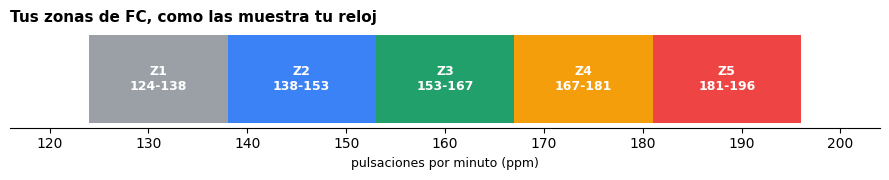

In [44]:
# --- Glosario: alimenta las ayudas (ⓘ) de la aplicación ---
GLOSARIO = {
    # Métricas fisiológicas
    'Body Battery': "Reserva de energía (0-100) que estima el reloj combinando HRV, estrés, sueño y actividad. Por debajo de 20-30, el cuerpo pide recuperación, no entrenamiento.",
    'HRV': "Variabilidad de la frecuencia cardiaca: los milisegundos que cambian entre latido y latido. Alta y estable = bien recuperado; si cae de golpe, fatiga, estrés o enfermedad.",
    'Estrés': "Índice 0-100 derivado de la HRV. Sostenido por encima de 70 el sistema nervioso está en alerta y asimila peor el entrenamiento.",
    'Sueño profundo': "Fase del sueño donde ocurre la reparación muscular y hormonal. Menos de ~1 h por noche de forma repetida frena la adaptación.",
    'FC': "Frecuencia cardiaca, en pulsaciones por minuto (ppm). Es el cuentarrevoluciones del entrenamiento.",
    'FC máxima / reposo': "Tus dos extremos: la FC máxima observada en esfuerzos duros y la FC al despertar. Entre ambas se calculan tus zonas (método de Karvonen).",
    'CTL (fitness)': "Carga crónica: media de tu entrenamiento de ~6 semanas. Es tu forma física acumulada; sube despacio y se pierde despacio.",
    'ATL (fatiga)': "Carga aguda: media de ~7 días. Es el cansancio reciente; sube y baja rápido.",
    'TSB (frescura)': "Fitness menos fatiga. Negativo = sobrecarga (entrenando fuerte); positivo = fresco. Muy negativo (<-25) = riesgo; muy positivo en carrera = llegas a punto.",
    'TRIMP': "Impulso de entrenamiento: cuánto 'pesa' una sesión combinando duración e intensidad cardiaca.",
    # Términos del plan
    'Z1-Z5 (zonas)': "Intensidades por FC: Z1 muy suave (recuperar), Z2 aeróbico (la base, puedes hablar), Z3 medio (te cuesta hablar), Z4 umbral (frases cortas), Z5 máximo (no hablas).",
    'Z2': "La zona donde se construye la resistencia del 70.3. Parece 'demasiado fácil': esa es la señal de que lo estás haciendo bien.",
    'Z4 / umbral': "El ritmo más alto que aguantas ~1 hora. Las series aquí elevan tu techo, pero solo cuando la base ya existe.",
    'D+': "Desnivel positivo acumulado: metros totales de subida de la ruta. Más D+ = más carga muscular y cardiaca al mismo ritmo.",
    'brick': "Bici seguida inmediatamente de carrera. Entrena la transición T2: los primeros minutos con 'piernas de cemento' que sentirás el día del 70.3.",
    'series': "Repeticiones de un esfuerzo con recuperación entre ellas (ej. 6x800 m). Permiten acumular minutos a intensidades que de seguido no aguantarías.",
    'fartlek': "Juego de ritmos dentro de un rodaje: cambios cortos más rápidos sin parar. Intensidad controlada para fases tempranas.",
    'FTP': "Potencia máxima sostenible ~1 h en bici (vatios). Con potenciómetro, las series se hacen al 90-100% del FTP; sin él, por FC y velocidad.",
    'cadencia': "Pedaladas (rpm) o zancadas por minuto. En bici, 85-95 rpm protege las piernas para la carrera posterior; en cuestas, 70-75.",
    'taper': "Reducción del volumen (~50%) las 2-3 semanas previas a la carrera manteniendo toques de intensidad: la fatiga se va, la forma se queda.",
    'pacing': "Estrategia de ritmo de carrera: a qué velocidad/FC afrontar cada segmento del 70.3 para no fundirte antes de la media maratón.",
}

def ayuda(termino):
    """Búsqueda flexible en el glosario (en la aplicación, una ayuda por término)."""
    t = termino.lower()
    for k, v in GLOSARIO.items():
        if t in k.lower(): return f"{k}: {v}"
    return f"'{termino}' no está en el glosario."

# --- Botón «Actualizar mi día»: recalcula SOLO la sesión de hoy ---
DIAS_ES = ['Lunes', 'Martes', 'Miércoles', 'Jueves', 'Viernes', 'Sábado', 'Domingo']

def actualizar_hoy(plan, sueno_h=None, body_battery=None, stress=None,
                   hrv=None, enfermo=False):
    """Recalcula la recomendación del día con las métricas de esta mañana,
    sin rehacer la semana. Tres niveles: MANTENER, SUAVIZAR (−40% de
    duración, todo Z1-Z2, sin calidad) o DESCANSO (la sesión se reprograma,
    no se pierde). En la aplicación es el botón «Actualizar mi día»."""
    dia = DIAS_ES[pd.Timestamp.today().dayofweek]
    sesiones_hoy = [s for s in plan['sesiones'] if s['dia'].split(' ')[0] == dia]
    z = plan['zonas']

    graves, moderados = [], []
    if enfermo:
        graves.append('enfermedad o malestar')
    if body_battery is not None and body_battery < 20:
        graves.append(f'Body Battery muy baja ({body_battery:.0f})')
    if sueno_h is not None and sueno_h < 5:
        graves.append(f'noche muy corta ({sueno_h:.1f} h)')
    if not graves:
        if body_battery is not None and body_battery < 35:
            moderados.append(f'Body Battery baja ({body_battery:.0f})')
        if sueno_h is not None and sueno_h < 6.5:
            moderados.append(f'sueño insuficiente ({sueno_h:.1f} h)')
        if stress is not None and stress > 70:
            moderados.append(f'estrés alto ({stress:.0f})')
        if (hrv is not None and not pd.isna(plan.get('hrv', np.nan))
                and hrv < plan['hrv'] * 0.85):
            moderados.append(f'HRV un 15% por debajo de tu media ({hrv:.0f} ms)')

    if graves:
        ajuste = {'decision': 'DESCANSO HOY',
                  'sesion_ajustada': 'Descanso completo: caminar suave, hidratarte y priorizar dormir.',
                  'nota': ('La sesión prevista no se pierde: se reprograma y la semana se '
                           'recompone sin acumular carga extra. Si era de calidad, se '
                           'intercambia con un rodaje.')}
    elif moderados:
        partes = []
        for s in sesiones_hoy:
            if s['deporte'] in ('Descanso', 'Movilidad'): continue
            dur = int(s['dur_min'] * 0.6)
            partes.append(f"{s['deporte']}: versión suave de {dur} min, todo en Z1-Z2 "
                          f"({z['hr']['Z1'][0]}-{z['hr']['Z2'][1]} ppm), sin series, "
                          f"ritmos ni rectas.")
        ajuste = {'decision': 'SUAVIZAR HOY',
                  'sesion_ajustada': ' '.join(partes) if partes else 'Hoy ya era descanso: mantenlo.',
                  'nota': ('Día regenerativo puntual: mañana se reevalúa. Si hoy tocaba '
                           'calidad, se intercambia con el rodaje de otro día de la semana.')}
    else:
        ajuste = {'decision': 'MANTENER',
                  'sesion_ajustada': ('; '.join(s['detalle'] for s in sesiones_hoy)
                                      if sesiones_hoy else 'Día de descanso programado.'),
                  'nota': 'Tus métricas de esta mañana están en tu rango: el plan sigue tal cual.'}
    ajuste['dia'] = dia
    ajuste['motivos'] = graves + moderados or ['métricas en rango']
    return ajuste

# Ejemplo del botón: el deportista A amanece tras una mala noche
plan_a = next((p for p in planes if p['athlete'] == SUJETO_PRUEBA), planes[0])
demo = actualizar_hoy(plan_a, sueno_h=4.9, body_battery=28, stress=62)
print(f"«Actualizar mi día» — {demo['dia']} | decisión: {demo['decision']}")
print(f"  Motivos: {', '.join(demo['motivos'])}")
print(f"  Sesión ajustada: {demo['sesion_ajustada']}")
print(f"  Nota: {demo['nota']}")
print()
print("Glosario:", len(GLOSARIO), "términos. Ejemplo ->", ayuda('brick'))

# --- Cuadro final «Para entender tu plan» + ilustración de zonas ---
TERMINOS_DEL_PLAN = ['FC', 'Z1-Z5 (zonas)', 'Z2', 'D+', 'brick', 'cadencia', 'TSB (frescura)']

def bloque_glosario(plan=None):
    """Cuadro explicativo que cierra cada recomendación. En la aplicación es el
    desplegable «Para entender tu plan», con el gráfico de zonas."""
    out = ['─' * 64, 'PARA ENTENDER TU PLAN']
    for k in TERMINOS_DEL_PLAN:
        out.append(f"  · {k} — {GLOSARIO[k]}")
    return '\n'.join(out)

GARMIN_COLORS = {'Z1': '#9aa0a6', 'Z2': '#3b82f6', 'Z3': '#22a06b',
                 'Z4': '#f59e0b', 'Z5': '#ef4444'}

def grafico_zonas(z, titulo='Tus zonas de FC, como las muestra tu reloj'):
    """Barra de zonas con los colores del reloj Garmin (gris, azul, verde,
    naranja, rojo) y los ppm reales del atleta, para asociarlas de
    inmediato."""
    import matplotlib.pyplot as plt
    fig, ax = plt.subplots(figsize=(9, 1.9))
    for zona, (lo, hi) in z['hr'].items():
        ax.barh(0, hi - lo, left=lo, height=0.62, color=GARMIN_COLORS[zona])
        ax.text((lo + hi) / 2, 0, f"{zona}\n{lo}-{hi}", ha='center', va='center',
                color='white', fontsize=9, fontweight='bold')
    ax.set_xlim(z['hr']['Z1'][0] - 8, z['hr']['Z5'][1] + 8)
    ax.set_yticks([])
    ax.set_xlabel('pulsaciones por minuto (ppm)', fontsize=9)
    for s in ('top', 'right', 'left'):
        ax.spines[s].set_visible(False)
    ax.set_title(titulo, fontsize=11, loc='left')
    plt.tight_layout()
    return fig

print()
print(bloque_glosario())
import matplotlib.pyplot as plt
grafico_zonas(plan_a['zonas']); plt.show()

### 8c. Plan de competencia, km a km

La semana de competencia incluye un plan de carrera por tramos de
kilómetros para las tres disciplinas, construido con las zonas y ritmos
objetivo del deportista. La clave fisiológica es que se sale de la natación
con la FC disparada (estrés del agua, neopreno y el
paso de horizontal a vertical), de modo que la bici arranca **progresiva
al 85 %** y solo sube al ritmo objetivo cuando la FC vuelve a su sitio.
Cada tramo lleva velocidad/ritmo, tope de FC, cadencia y nutrición.

In [45]:
def plan_competencia(plan):
    """Plan de carrera por tramos de km, con las zonas y ritmos objetivo
    del atleta. Devuelve (segmentos, resumen de tiempo estimado)."""
    z = plan['zonas']; hr = z['hr']
    v_b, v_r, v_n = z['bici_obj'], z['run_obj'], z['nat_obj']
    seg = []
    add = lambda d, t, txt: seg.append({'disciplina': d, 'tramo': t, 'indicacion': txt})

    # ---- NATACIÓN (1,9 km) ----
    add('NATACIÓN 1,9 km', '0-300 m',
        "Salida CONTROLADA al 90%: deja pasar al grupo rápido y busca agua libre. "
        "El objetivo es no disparar la FC en los primeros minutos: la carrera no se gana aquí.")
    add('NATACIÓN 1,9 km', '300-1.600 m',
        f"Ritmo de crucero a {_pace_swim(v_n)}. Busca pies de alguien un punto más rápido "
        f"(el drafting es legal y ahorra ~5% de energía). Respira cada 2-3 brazadas.")
    add('NATACIÓN 1,9 km', '1.600-1.900 m',
        "Aumenta el pataleo suavemente: redirige sangre a las piernas antes de ponerte "
        "de pie y visualiza la T1.")
    add('TRANSICIÓN T1', '—',
        f"Saldrás del agua con la FC en {hr['Z4'][0]}+ ppm aunque no hayas apretado: "
        f"estrés del agua, neopreno y pasar de horizontal a vertical. Camina rápido, no esprintes.")

    # ---- BICI (90 km): arranque progresivo hasta recuperar la FC ----
    add('BICI 90 km', 'km 0-5',
        f"Arranque PROGRESIVO al 85% ({v_b * 0.85:.0f} km/h), cadencia 90-95 rpm. Tu FC viene "
        f"alta de la natación: NO la persigas; espera a que baje de {hr['Z3'][0]} ppm. Bebe ya.")
    add('BICI 90 km', 'km 5-15',
        f"Sube gradualmente hacia el ritmo objetivo ({v_b:.0f} km/h) SOLO cuando la FC se asiente "
        f"en Z2-Z3 bajo ({hr['Z2'][0]}-{hr['Z3'][0]} ppm). Primera comida en el km 10-15.")
    add('BICI 90 km', 'km 15-70',
        f"Velocidad de crucero {v_b:.0f} km/h, FC tope {hr['Z3'][1]} ppm. Come 60-90 g de "
        f"carbohidrato/hora (cada 30-40 min). En subidas, sentado y sin pasar de {hr['Z3'][1]} ppm "
        f"aunque te adelanten: lo devolverás corriendo.")
    add('BICI 90 km', 'km 70-85',
        f"El tramo del juicio: si las piernas van bien, MANTÉN {v_b:.0f} km/h — no subas. "
        f"Última comida sólida antes del km 80.")
    add('BICI 90 km', 'km 85-90',
        f"Afloja al 95% ({v_b * 0.95:.0f} km/h) y sube la cadencia a 95-100 rpm: piernas sueltas "
        f"para la T2. Estira la espalda y termina el bidón.")
    add('TRANSICIÓN T2', '—',
        "La FC vuelve a subir al desmontar: es normal. Cambio rápido pero sin pánico; "
        "gorra, dorsal y a correr.")

    # ---- CARRERA (21,1 km) ----
    add('CARRERA 21,1 km', 'km 0-3',
        f"BRICK: piernas de cemento los primeros 2-3 km. Sal a {_pace_run(v_r * 0.92)} aunque te "
        f"sientas capaz de más: la FC ya viene en {hr['Z3'][0]}+ ppm y debe asentarse.")
    add('CARRERA 21,1 km', 'km 3-10',
        f"Ritmo objetivo {_pace_run(v_r)}, FC tope {hr['Z3'][1]} ppm. Agua o isotónico en cada "
        f"avituallamiento; gel en el km 7-8.")
    add('CARRERA 21,1 km', 'km 10-16',
        f"Mantén {_pace_run(v_r)}. Aquí se decide la carrera: si la FC sube a Z4 "
        f"({hr['Z4'][0]}+ ppm) sin haber subido el ritmo, afloja 10-15 s/km y reevalúa.")
    add('CARRERA 21,1 km', 'km 16-19',
        f"La parte dura. Permitido entrar en Z4 bajo ({hr['Z4'][0]}-"
        f"{int((hr['Z4'][0] + hr['Z4'][1]) / 2)} ppm) si las sensaciones acompañan.")
    add('CARRERA 21,1 km', 'km 19-21,1',
        "Vacía el tanque: todo lo que quede. Cruzar la meta de un 70.3 se recuerda toda la vida.")

    # ---- Tiempo estimado por segmento ----
    t_nat = 1.9 / v_n * 60
    t_bici = (5 / (v_b * 0.85) + 10 / (v_b * 0.95) + 70 / v_b + 5 / (v_b * 0.95)) * 60
    t_run = (3 / (v_r * 0.92) + 18.1 / v_r) * 60
    trans = plan['objetivo']['transiciones_min'] if plan.get('objetivo') else 8
    total = t_nat + trans + t_bici + t_run
    resumen = (f"Tiempo estimado: natación {_min2t(t_nat)} + T1/T2 {_min2t(trans)} + "
               f"bici {_min2t(t_bici)} + carrera {_min2t(t_run)} = {_min2t(total)}")
    if plan.get('objetivo'):
        resumen += f" (objetivo declarado: {plan['objetivo']['objetivo_total']})"
    return seg, resumen


def texto_plan_competencia(plan):
    seg, resumen = plan_competencia(plan)
    out, disc = [], None
    for s in seg:
        if s['disciplina'] != disc:
            disc = s['disciplina']
            out.append(f"\n  {disc}")
        out.append(f"    {s['tramo']:>12s} | {s['indicacion']}")
    out.append(f"\n  {resumen}")
    return '\n'.join(out)


# --- Ejemplo: B como deportista experimentado con carrera este domingo ---
# Los tiempos de la marca anterior son FICTICIOS: ningún deportista del estudio
# ha competido en un 70.3. Sirven solo para mostrar el plan orientado a marca.
PERFIL_ATLETA['B'] = 'experimentado'
OBJETIVOS_70_3['B'] = {'anterior': {'nat': '0:42', 'bici': '2:58',
                                    'run': '2:05', 'total': '5:55'},
                       'objetivo_total': '5:35'}
FECHA_COMPETENCIA['B'] = str((pd.Timestamp.today() + pd.Timedelta(days=6)).date())

if 'B' in garmin_data:
    plan_b = generar_plan_semanal('B')
    print("Ejemplo con tiempos de marca FICTICIOS (ningún deportista del estudio ha competido en un 70.3)")
    print()
    print(generar_explicacion(plan_b))
else:
    print("(B no está en los datos cargados)")

Ejemplo con tiempos de marca FICTICIOS (ningún deportista del estudio ha competido en un 70.3)

Macrociclo: fase Competencia · faltan 1 semanas para el 70.3 (2026-11-15) · progresión de forma: fase final: mantener, no construir (CTL 64 / objetivo 70).
AVISO IMPORTANTE: para un atleta experimentado se recomiendan al menos 12 semanas de preparación y este plan solo tiene 7; considera una carrera más lejana o ajusta el objetivo (terminar bien, no competir).

Semana de competencia. Todo lo que había que entrenar ya está entrenado: días cortos, activaciones y el domingo tu 70.3, con el pacing calculado a partir de tus propios datos.

Tus referencias de esta semana — FC máx: 192 ppm | FC reposo: 54 ppm | Z2: 136-150 ppm | Z4: 164-178 ppm | Rodaje: 5:25 min/km | Series: 5:22 min/km | Bici Z2: 23 km/h | Natación: 2:29/100 m
Validación de ritmos: validado con 69 carreras reales en Z2 de tu historial.
Objetivo de marca: 5:55 → 5:35 (-20 min, 5.6%). Splits objetivo: natación 0:39 · bici 2:48 · ca

## 9. Almacenamiento de resultados (Parquet, SQLite y joblib)

Parquet guarda las tablas grandes (actividades, serie diaria de carga y variables de cada deportista); SQLite
guarda los resultados del cuaderno (planes, sesiones y predicciones); joblib guarda los dos modelos de
transferencia y las listas de variables que esperan, que es lo único que necesita la aplicación.

In [46]:
import sqlite3
import joblib

os.makedirs('salidas/parquet', exist_ok=True)
os.makedirs('salidas/modelos', exist_ok=True)

# 1) Parquet: datos voluminosos, comprimidos por columnas
if not df_act.empty:
    df_act.to_parquet('salidas/parquet/actividades.parquet', index=False, compression='snappy')
if fitness_data:
    pd.concat(fitness_data.values(), ignore_index=True).to_parquet(
        'salidas/parquet/fitness_fatiga.parquet', index=False, compression='snappy')
df_profiles.reset_index().to_parquet('salidas/parquet/perfiles.parquet', index=False)

# 2) SQLite: resultados del cuaderno (variables, planes, sesiones y predicciones)
con = sqlite3.connect('salidas/triatlon.db')
df_profiles.reset_index().to_sql('perfiles', con, if_exists='replace', index=False)
df_planes.to_sql('planes_semanales', con, if_exists='replace', index=False)
df_sesiones.to_sql('sesiones_plan', con, if_exists='replace', index=False)
pd.DataFrame(predicciones_cyc).to_sql('predicciones_ciclismo', con, if_exists='replace', index=False)
if predicciones_run:
    pd.DataFrame(predicciones_run).to_sql('predicciones_carrera', con, if_exists='replace', index=False)

# comprobación rápida de lo que quedó guardado
tablas = pd.read_sql("SELECT name FROM sqlite_master WHERE type='table'", con)['name'].tolist()
print("Tablas en triatlon.db:", tablas)
con.close()

# 3) Modelos para la aplicación. La app lee de preprocesadores.joblib qué variables
#    espera cada modelo, así que no hay que tocar su código al cambiarlas.
joblib.dump(model_xgb,     'salidas/modelos/xgb_run2cyc.joblib')
joblib.dump(model_xgb_run, 'salidas/modelos/xgb_cyc2run.joblib')
joblib.dump({'feature_cols': FEATURE_COLS, 'feat_cyc2run': FEAT_CYC2RUN,
             'params_directo': PARAMS_DIR, 'params_inverso': PARAMS_INV},
            'salidas/modelos/preprocesadores.joblib')
# Copia en el formato propio de XGBoost, independiente de la versión de joblib
model_xgb.save_model('salidas/modelos/xgb_run2cyc.json')
model_xgb_run.save_model('salidas/modelos/xgb_cyc2run.json')

# tamaño de cada fichero
for root, _, fnames in os.walk('salidas'):
    for fn in fnames:
        fp = os.path.join(root, fn)
        print(f"  {fp}: {os.path.getsize(fp) / 1024:.1f} KB")

print("\nResultados guardados en salidas/. La sección 11 los empaqueta en salidas.zip.")

Tablas en triatlon.db: ['perfiles', 'planes_semanales', 'sesiones_plan', 'predicciones_ciclismo', 'predicciones_carrera']
  salidas/triatlon.db: 32.0 KB
  salidas/modelos/preprocesadores.joblib: 0.4 KB
  salidas/modelos/xgb_cyc2run.joblib: 438.1 KB
  salidas/modelos/xgb_run2cyc.json: 1175.6 KB
  salidas/modelos/xgb_cyc2run.json: 360.1 KB
  salidas/modelos/xgb_run2cyc.joblib: 1182.6 KB
  salidas/parquet/perfiles.parquet: 21.9 KB
  salidas/parquet/fitness_fatiga.parquet: 84.6 KB
  salidas/parquet/actividades.parquet: 168.4 KB
  salidas/figuras/curva_aprendizaje_ambos.png: 114.3 KB
  salidas/figuras/curva_respuesta_modelos.png: 181.6 KB
  salidas/figuras/actividades_por_deportista.png: 64.7 KB
  salidas/figuras/curva_validacion_profundidad.png: 120.1 KB
  salidas/figuras/ciclismo_real_vs_predicho.png: 64.8 KB
  salidas/figuras/ctl_atl_tsb_ultimo_anio.png: 244.2 KB
  salidas/figuras/shap_modelo_directo.png: 31.9 KB
  salidas/figuras/comparacion_modelos.png: 107.2 KB

Resultados guardados e

## 10. Panel de control del cuaderno

Vista rápida para revisar los resultados durante el desarrollo. La herramienta para el deportista es la
aplicación de Streamlit.

In [47]:
if fitness_data:
    fig = make_subplots(rows=2, cols=2,
        subplot_titles=['CTL/TSB (último año)', 'Actividades por deporte (horas)',
                        'FC media por participante', 'Velocidad ciclismo proyectada'],
        specs=[[{'type': 'scatter'}, {'type': 'bar'}], [{'type': 'box'}, {'type': 'bar'}]])

    colors_list = [COLORS.get(n, '#888') for n in fitness_data]

    for i, (name, fd) in enumerate(fitness_data.items()):
        fd_p = fd.tail(365); c = colors_list[i]
        fig.add_trace(go.Scatter(x=fd_p['date'], y=fd_p['CTL'], name=f'{name} CTL',
            line=dict(color=c, width=2), legendgroup=name, showlegend=True), row=1, col=1)
        fig.add_trace(go.Scatter(x=fd_p['date'], y=fd_p['TSB'], name=f'{name} TSB',
            line=dict(color=c, width=1, dash='dot'), legendgroup=name, showlegend=False), row=1, col=1)

    if not df_act.empty:
        sport_dur = df_act.groupby(['athlete', 'sport'])['duration_min'].sum().reset_index()
        for i, (name, grp) in enumerate(sport_dur.groupby('athlete')):
            fig.add_trace(go.Bar(x=grp['sport'], y=grp['duration_min'] / 60, name=name,
                marker_color=colors_list[i], legendgroup=name, showlegend=False), row=1, col=2)
        for i, (name, grp) in enumerate(df_act.groupby('athlete')):
            fig.add_trace(go.Box(y=grp['avg_hr'].dropna(), name=name,
                marker_color=colors_list[i], showlegend=False), row=2, col=1)

    # velocidades de ciclismo proyectadas (estimado conservador)
    if predicciones_cyc:
        df_pred = pd.DataFrame(predicciones_cyc)
        cols_bar = [COLORS.get(n, '#888') for n in df_pred['athlete']]
        fig.add_trace(go.Bar(x=df_pred['athlete'], y=df_pred['pred_conservador_kmh'],
            marker_color=cols_bar, text=df_pred['pred_conservador_kmh'].astype(str) + ' km/h',
            textposition='outside', showlegend=False), row=2, col=2)

    fig.update_layout(height=680, title_text='Panel de control — triatlón 70.3',
                      template='plotly_white', hovermode='x unified',
                      legend=dict(orientation='h', yanchor='bottom', y=1.02))
    fig.update_yaxes(title_text='TRIMP', row=1, col=1)
    fig.update_yaxes(title_text='Horas totales', row=1, col=2)
    fig.update_yaxes(title_text='FC media (bpm)', row=2, col=1)
    fig.update_yaxes(title_text='Velocidad km/h', row=2, col=2)
    fig.show()

print("\nCuaderno ejecutado completo. Estado final de cada deportista:")
for name, row in df_profiles.iterrows():
    nota = " (caso de evaluación)" if name == SUJETO_PRUEBA else ""
    print(f"  Deportista {name}: CTL={row.get('ctl_current', np.nan):.1f} | TSB={row.get('tsb_current', np.nan):.1f}{nota}")


Cuaderno ejecutado completo. Estado final de cada deportista:
  Deportista A: CTL=44.5 | TSB=-14.6 (caso de evaluación)
  Deportista B: CTL=63.7 | TSB=-16.8
  Deportista C: CTL=74.1 | TSB=3.4
  Deportista D: CTL=0.5 | TSB=0.5


## 11. Empaquetar `salidas/` para la aplicación

Crea `salidas.zip` y, en Colab, lo descarga. Para actualizar la aplicación basta con descomprimirlo junto a
`app.py` (o subir `salidas/modelos/` al repositorio) y volver a desplegar.

In [48]:
import shutil

ESPERADOS = ['salidas/modelos/xgb_run2cyc.joblib', 'salidas/modelos/xgb_cyc2run.joblib',
             'salidas/modelos/xgb_run2cyc.json', 'salidas/modelos/xgb_cyc2run.json',
             'salidas/modelos/preprocesadores.joblib', 'salidas/triatlon.db',
             'salidas/parquet/actividades.parquet', 'salidas/parquet/fitness_fatiga.parquet',
             'salidas/parquet/perfiles.parquet']
faltan = [f for f in ESPERADOS if not os.path.exists(f)]
print("Faltan:", faltan if faltan else "nada, están todos los ficheros")

ruta_zip = shutil.make_archive('salidas', 'zip', '.', 'salidas')
print(f"Creado {ruta_zip} ({os.path.getsize(ruta_zip) / 1e6:.1f} MB)")
try:
    from google.colab import files
    files.download(ruta_zip)
except ImportError:
    pass

Faltan: nada, están todos los ficheros
Creado /content/salidas.zip (1.6 MB)


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>